# JAK-STAT 信号通路模型参数重拟合
**参考文献**: Raue A. et al. (2009) *Structural and practical identifiability analysis of partially observed dynamical models by exploiting the profile likelihood*, Bioinformatics 25(15):1923–1929.

**数据来源**: Swameye et al. (2003) PNAS, dataset 1（论文原链接 `webber.physik.uni-freiburg.de/~jeti/PNAS_Swameye_Data/` 已失效，本 notebook 使用 Data2Dynamics (D2D) 仓库保存的同一份原始数据 `pnas_data_original.xls`）。

## 模型 (Raue 2009, Sec. 5)

$$
\begin{aligned}
\dot x_1 &= -p_1 x_1 u + 2 p_4 x_4^{\tau} & y_1 &= s_1 (x_2 + 2x_3)\\
\dot x_2 &= +p_1 x_1 u - p_2 x_2^2 & y_2 &= s_2 (x_1 + x_2 + 2x_3)\\
\dot x_3 &= +\tfrac12 p_2 x_2^2 - p_3 x_3 \\
\dot x_4 &= +p_3 x_3 - p_4 x_4^{\tau}
\end{aligned}
$$

- $x_1$: 胞质 STAT, $x_2$: pSTAT, $x_3$: pSTAT 二聚体 (胞质), $x_4$: 核内二聚体
- $u(t)$: 活化受体 pEpoR 的实验测量值的样条插值（外部输入）
- 上标 $\tau$ 表示延迟反应，用 **linear chain approximation** 实现：10 个中间步骤，每步速率 $p_4$，有效延迟 $\tau = 10/p_4$
- 可观测量: $y_1$ = 胞质磷酸化 STAT (pSTAT, a.u.), $y_2$ = 胞质总 STAT (tSTAT, a.u.)
- 待拟合参数 $\theta = (p_1,p_2,p_3,p_4,s_1,s_2,x_1(0))$，$x_2(0)=x_3(0)=x_4(0)=0$
- 论文指出 $p_2, x_1(0), s_1, s_2$ 结构不可识别（只有 $p_2 x_1(0)$, $s_1 x_1(0)$, $s_2 x_1(0)$ 可识别），$p_3$ 实际不可识别（向上无界）。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline
from scipy.optimize import least_squares
np.set_printoptions(precision=4, suppress=True)

## 1. 实验数据 (Swameye 2003, dataset 1) 并保存为 `data.npz`

In [2]:
# 列: time(min), pSTAT_au, pSTAT_au_std, tSTAT_au, tSTAT_au_std, pEpoR_au
raw = np.array([
    # t     pSTAT   sd      tSTAT   sd     pEpoR
    [ 0.0,  np.nan, np.nan, 1.0000, 0.084, 0.01713],
    [ 2.0,  0.3315, 0.050,  0.9275, 0.046, 0.1450 ],
    [ 4.0,  0.8645, 0.066,  0.7923, 0.038, 0.2442 ],
    [ 6.0,  0.9635, 0.070,  0.7778, 0.032, 0.7659 ],
    [ 8.0,  0.9279, 0.065,  0.7053, 0.033, 1.0000 ],
    [10.0,  0.8162, 0.051,  0.6522, 0.037, 0.8605 ],
    [12.0,  0.7553, 0.053,  0.5894, 0.039, 0.7829 ],
    [14.0,  0.7680, 0.051,  0.5894, 0.040, 0.5705 ],
    [16.0,  0.8416, 0.040,  0.6377, 0.030, 0.6217 ],
    [18.0,  0.7680, 0.040,  0.6425, 0.028, 0.3310 ],
    [20.0,  0.8010, 0.048,  0.6908, 0.030, 0.3388 ],
    [25.0,  0.7832, 0.052,  0.6908, 0.031, 0.3116 ],
    [30.0,  0.8086, 0.054,  0.7585, 0.032, 0.05062],
    [40.0,  0.4888, 0.055,  0.8068, 0.040, 0.02504],
    [50.0,  0.2782, 0.044,  0.9275, 0.046, 0.01163],
    [60.0,  0.2553, 0.071,  0.9710, 0.082, np.nan ],
])
t_all = raw[:, 0]

m1 = ~np.isnan(raw[:, 1])            # pSTAT 在 t=0 缺失
t_pSTAT, pSTAT, pSTAT_sd = raw[m1, 0], raw[m1, 1], raw[m1, 2]
t_tSTAT, tSTAT, tSTAT_sd = raw[:, 0], raw[:, 3], raw[:, 4]
m3 = ~np.isnan(raw[:, 5])            # pEpoR 在 t=60 缺失
t_pEpoR, pEpoR = raw[m3, 0], raw[m3, 5]

np.savez('data.npz',
         t_pSTAT=t_pSTAT, pSTAT=pSTAT, pSTAT_sd=pSTAT_sd,
         t_tSTAT=t_tSTAT, tSTAT=tSTAT, tSTAT_sd=tSTAT_sd,
         t_pEpoR=t_pEpoR, pEpoR=pEpoR,
         raw_table=raw,
         columns=np.array(['time_min','pSTAT_au','pSTAT_au_std','tSTAT_au','tSTAT_au_std','pEpoR_au']))
print({k: v.shape for k, v in np.load('data.npz').items()})

# 同时保存为 MATLAB .mat
from scipy.io import savemat
savemat('data.mat', dict(t_pSTAT=t_pSTAT, pSTAT=pSTAT, pSTAT_sd=pSTAT_sd, t_tSTAT=t_tSTAT, tSTAT=tSTAT, tSTAT_sd=tSTAT_sd,
                         t_pEpoR=t_pEpoR, pEpoR=pEpoR, raw_table=raw,
                         columns=np.array(['time_min', 'pSTAT_au', 'pSTAT_au_std', 'tSTAT_au', 'tSTAT_au_std', 'pEpoR_au'], dtype=object),
                         source='Swameye et al. 2003 PNAS dataset 1 (via Data2Dynamics pnas_data_original.xls); NaN entries in raw_table = missing'))
print('saved data.mat')

{'t_pSTAT': (15,), 'pSTAT': (15,), 'pSTAT_sd': (15,), 't_tSTAT': (16,), 'tSTAT': (16,), 'tSTAT_sd': (16,), 't_pEpoR': (15,), 'pEpoR': (15,), 'raw_table': (16, 6), 'columns': (6,)}
saved data.mat


## 2. 外部输入 $u(t)$：pEpoR 测量值的样条插值

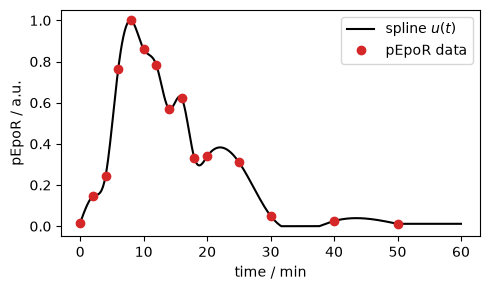

In [3]:
_spl = CubicSpline(t_pEpoR, pEpoR, bc_type='natural')
def u_input(t):
    # 60 min 处无测量：50 min 之后保持末值（末值已接近 0）
    t = np.clip(t, t_pEpoR[0], t_pEpoR[-1])
    return np.maximum(_spl(t), 0.0)  # 样条可能轻微越过 0，截断

tt = np.linspace(0, 60, 601)
plt.figure(figsize=(5, 3))
plt.plot(tt, u_input(tt), 'k-', label='spline $u(t)$')
plt.plot(t_pEpoR, pEpoR, 'o', color='tab:red', label='pEpoR data')
plt.xlabel('time / min'); plt.ylabel('pEpoR / a.u.'); plt.legend(); plt.tight_layout()

## 3. ODE 模型（含 10 步 linear chain 延迟）

In [4]:
N_CHAIN = 10
PNAMES = ['p1', 'p2', 'p3', 'p4', 's1', 's2', 'x1_0']

def rhs(t, x, p1, p2, p3, p4):
    x1, x2, x3, x4 = x[:4]
    z = x[4:]                      # z_1..z_10: 延迟链
    u = u_input(t)
    dx = np.empty_like(x)
    dx[0] = -p1 * x1 * u + 2 * p4 * z[-1]      # 延迟后返回胞质 (二聚体解离 -> 2 个 STAT)
    dx[1] =  p1 * x1 * u - p2 * x2**2
    dx[2] =  0.5 * p2 * x2**2 - p3 * x3
    dx[3] =  p3 * x3 - p4 * x4
    dx[4] =  p4 * x4 - p4 * z[0]
    dx[5:] = p4 * z[:-1] - p4 * z[1:]
    return dx

def simulate(theta, t_eval):
    p1, p2, p3, p4, s1, s2, x1_0 = theta
    x0 = np.zeros(4 + N_CHAIN); x0[0] = x1_0
    sol = solve_ivp(rhs, (0, t_eval[-1]), x0, t_eval=t_eval, args=(p1, p2, p3, p4),
                    method='LSODA', rtol=1e-8, atol=1e-10)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.y

def observables(theta, t_eval):
    p1, p2, p3, p4, s1, s2, x1_0 = theta
    x = simulate(theta, t_eval)
    y1 = s1 * (x[1] + 2 * x[2])            # pSTAT
    y2 = s2 * (x[0] + x[1] + 2 * x[2])     # tSTAT
    return y1, y2, x

## 4. 参数拟合（$\chi^2$ 加权最小二乘，log10 参数空间，多起点）

$$\chi^2(\theta)=\sum_k \left(\frac{y_k^{\rm data}-y_k(\theta)}{\sigma_k}\right)^2$$

$\sigma_k$ 取实验给出的标准差。
- **只优化可识别组合**：模型对 $(p_2,s_1,s_2,x_1(0))\to(p_2/c,\ s_1/c,\ s_2/c,\ c\,x_1(0))$ 不变（把状态按 $x_1(0)$ 缩放即可看出），$\chi^2$ 只依赖 6 个量
  $$q=\log_{10}\big(p_1,\ P_2=p_2x_1(0),\ p_3,\ p_4,\ S_1=s_1x_1(0),\ S_2=s_2x_1(0)\big).$$
  因此直接在这 6 个组合上优化，去掉了冗余的结构对称方向。计算时取规范 $\log_{10}x_1(0)=0.31$（论文值）调用 7 参数模型，$\chi^2$ 与规范选取无关（下面数值检验）。
- **边界**（log10）：$p_1,p_3,p_4\in[-3,3]$；三个组合 $\in[-6,6]$，即原来 $[-3,3]^7$ 盒子中两个参数乘积可达的范围。
- **Jacobian**：`least_squares` 默认的 2 点有限差分步长（约 $10^{-8}$）与 ODE 求解精度同量级，Jacobian 会被数值噪声污染。这里用**一阶前向灵敏度方程**计算解析 Jacobian；$x_1(0)$ 固定时 $\theta$ 是 $q$ 的平移，故 $\partial r/\partial q$ 就是 7 维 Jacobian 的前 6 列。
- **多起点**：起点在上述边界内均匀采样，12 进程并行。
- **后续各节**使用最优 $q$ 在规范 $x_1(0)=10^{0.31}$ 下的 7 参数表示（`best`, `best_log`）。

In [5]:
t_grid = np.unique(np.concatenate([t_pSTAT, t_tSTAT]))
i1 = np.searchsorted(t_grid, t_pSTAT); i2 = np.searchsorted(t_grid, t_tSTAT)

def residuals(log10_theta):
    theta = 10.0 ** log10_theta
    try:
        y1, y2, _ = observables(theta, t_grid)
    except Exception:
        return np.full(len(t_pSTAT) + len(t_tSTAT), 1e3)
    return np.concatenate([(y1[i1] - pSTAT) / pSTAT_sd, (y2[i2] - tSTAT) / tSTAT_sd])

def chi2(log10_theta):
    return np.sum(residuals(log10_theta) ** 2)

# ---- 解析 Jacobian: 一阶前向灵敏度 y = dx/d(p1,p2,p3,p4,x1_0) ----
_NX, _KO = 4 + N_CHAIN, 5
def _sens_rhs(t, s, p1, p2, p3, p4):
    x = s[:_NX]; y = s[_NX:].reshape(_NX, _KO); u = u_input(t)
    x1, x2, x3, x4 = x[:4]; z = x[4:]
    A = np.zeros((_NX, _NX))
    A[0, 0] = -p1 * u; A[0, _NX - 1] = 2 * p4; A[1, 0] = p1 * u; A[1, 1] = -2 * p2 * x2
    A[2, 1] = p2 * x2; A[2, 2] = -p3; A[3, 2] = p3; A[3, 3] = -p4; A[4, 3] = p4; A[4, 4] = -p4
    for i in range(5, _NX): A[i, i - 1] = p4; A[i, i] = -p4
    B = np.zeros((_NX, _KO))
    B[0, 0] = -x1 * u; B[1, 0] = x1 * u; B[1, 1] = -x2**2; B[2, 1] = 0.5 * x2**2; B[2, 2] = -x3; B[3, 2] = x3
    B[0, 3] = 2 * z[-1]; B[3, 3] = -x4; B[4, 3] = x4 - z[0]; B[5:, 3] = z[:-1] - z[1:]
    return np.concatenate([rhs(t, x, p1, p2, p3, p4), (A @ y + B).ravel()])

_c1 = np.zeros(_NX); _c1[1] = 1; _c1[2] = 2          # y1 = s1 * c1.x
_c2 = np.zeros(_NX); _c2[0] = 1; _c2[1] = 1; _c2[2] = 2   # y2 = s2 * c2.x
def jac_residuals(log10_theta):
    th = 10.0 ** log10_theta; p1, p2, p3, p4, s1, s2, x10 = th
    x0 = np.zeros(_NX); x0[0] = x10; y0 = np.zeros((_NX, _KO)); y0[0, 4] = 1.0
    try:
        sol = solve_ivp(_sens_rhs, (0, t_grid[-1]), np.concatenate([x0, y0.ravel()]), t_eval=t_grid,
                        args=(p1, p2, p3, p4), method='LSODA', rtol=1e-8, atol=1e-10)
        if not sol.success: raise RuntimeError
    except Exception:
        return np.zeros((len(t_pSTAT) + len(t_tSTAT), 7))
    S = sol.y.T; x = S[:, :_NX]; y = S[:, _NX:].reshape(-1, _NX, _KO)
    Jt = np.zeros((len(t_grid), 2, 7)); ode = [0, 1, 2, 3, 6]
    Jt[:, 0, ode] = s1 * np.einsum('m,nmj->nj', _c1, y); Jt[:, 0, 4] = x @ _c1
    Jt[:, 1, ode] = s2 * np.einsum('m,nmj->nj', _c2, y); Jt[:, 1, 5] = x @ _c2
    Jt *= th[None, None, :] * np.log(10.0)                 # d/d log10(theta)
    return np.vstack([Jt[i1, 0] / pSTAT_sd[:, None], Jt[i2, 1] / tSTAT_sd[:, None]])

# 检验解析 Jacobian
_xt = np.array([0.31, -1.0, -0.49, 0.42, -0.25, -0.36, 0.31])
_Jfd = np.column_stack([(residuals(_xt + e) - residuals(_xt - e)) / 2e-4 for e in 1e-4 * np.eye(7)])
print(f'analytic Jacobian vs central FD: max rel err = {np.abs(jac_residuals(_xt) - _Jfd).max() / np.abs(_Jfd).max():.2e}')

# ---- 重参数化: 只优化可识别组合 ----
# 状态可按 x1(0) 缩放 (x -> x / x1(0)), chi2 只依赖 6 个量:
#   q = log10 (p1, P2 = p2*x1(0), p3, p4, S1 = s1*x1(0), S2 = s2*x1(0))
# 为了调用 7 参数的模型函数, 取规范 log10 x1(0) = X1_GAUGE (论文值); chi2 与规范选取无关.
QNAMES = ['p1', 'p2*x1_0', 'p3', 'p4', 's1*x1_0', 's2*x1_0']
X1_GAUGE = 0.31

def q_to_theta(q, x1=X1_GAUGE):
    q = np.asarray(q, float)
    return np.array([q[0], q[1] - x1, q[2], q[3], q[4] - x1, q[5] - x1, x1])

def theta_to_q(lg):
    lg = np.asarray(lg, float)
    return np.array([lg[0], lg[1] + lg[6], lg[2], lg[3], lg[4] + lg[6], lg[5] + lg[6]])

def residuals_q(q):
    return residuals(q_to_theta(q))

def jac_q(q):
    # x1(0) 固定时 theta = q 的平移, 故 d r / d q = 7 维解析 Jacobian 的前 6 列 (p1, p2, p3, p4, s1, s2)
    return jac_residuals(q_to_theta(q))[:, :6]

# 检验: (a) 不同规范给出相同残差 (精确对称); (b) 6 维 Jacobian 与中心差分一致
_qt = theta_to_q(_xt)
print(f'gauge invariance: max |r(x1=0.31) - r(x1=1.5)| = {np.abs(residuals(q_to_theta(_qt, 0.31)) - residuals(q_to_theta(_qt, 1.5))).max():.2e}')
_Jqfd = np.column_stack([(residuals_q(_qt + e) - residuals_q(_qt - e)) / 2e-4 for e in 1e-4 * np.eye(6)])
print(f'6-d Jacobian vs central FD: max rel err = {np.abs(jac_q(_qt) - _Jqfd).max() / np.abs(_Jqfd).max():.2e}')

# 边界 (log10): p1, p3, p4 in [-3, 3]; 三个组合 in [-6, 6] (= 原 [-3, 3]^7 中两个参数乘积可达的范围)
lb_q = np.array([-3., -6., -3., -3., -6., -6.]); ub_q = np.array([3., 6., 3., 3., 6., 6.])

def fit_from(q0):
    try:
        r = least_squares(residuals_q, np.clip(q0, lb_q, ub_q), jac=jac_q, bounds=(lb_q, ub_q), method='trf', x_scale='jac',
                          ftol=1e-10, xtol=1e-10, gtol=1e-10, max_nfev=3000)
        return 2 * r.cost, r.x
    except Exception:
        return np.inf, np.asarray(q0)

n_starts = 50
X0 = np.random.default_rng(2026).uniform(lb_q, ub_q, size=(n_starts, 6))
import multiprocessing as mp, time
_t0 = time.time()
try:
    with mp.get_context('fork').Pool(min(12, mp.cpu_count())) as pool:
        results = pool.map(fit_from, list(X0))
except Exception as e:                                   # 并行失败时退回串行
    print('parallel pool failed, running serially:', e)
    results = [fit_from(x0) for x0 in X0]
_ord = sorted((k for k, r in enumerate(results) if np.isfinite(r[0])), key=lambda k: results[k][0])
X0_sorted = X0[_ord]                                   # 与排序后的 results 一一对应的起点
results = [results[k] for k in _ord]
chi2_vals = np.array([z[0] for z in results])
print(f'{n_starts} starts in {time.time() - _t0:.0f} s')
print('multistart chi2 (sorted, first 15):', np.round(chi2_vals[:15], 3))
_v, _c = np.unique(np.round(chi2_vals, 1), return_counts=True)
print('chi2 clusters (value: number of starts):', ', '.join(f'{v:.1f}: {c}' for v, c in zip(_v[:8], _c[:8])))

best_chi2, best_q = results[0]
best_log = q_to_theta(best_q)                           # 7 参数表示 (规范 x1(0) = 10^0.31), 供后续各节使用
best = 10.0 ** best_log
print(f'\nbest chi2 = {best_chi2:.3f}  (N_data = {len(t_pSTAT)+len(t_tSTAT)}, N_identifiable = 6)')
print('optimized combinations (log10):')
for n, lv, lo_, hi_ in zip(QNAMES, best_q, lb_q, ub_q):
    print(f'   {n:8s} = {10**lv:10.4g}   (log10 = {lv:+.3f})' + ('   <- at bound' if min(abs(lv - lo_), abs(lv - hi_)) < 1e-3 else ''))
print(f'7-parameter representative (gauge log10 x1(0) = {X1_GAUGE}):')
for n, v, lv in zip(PNAMES, best, best_log):
    print(f'   {n:8s} = {v:10.4g}   (log10 = {lv:+.3f})')

analytic Jacobian vs central FD: max rel err = 1.33e-05
gauge invariance: max |r(x1=0.31) - r(x1=1.5)| = 2.14e-07


6-d Jacobian vs central FD: max rel err = 1.33e-05


50 starts in 199 s
multistart chi2 (sorted, first 15): [57.404 57.404 57.404 57.404 57.404 57.404 57.404 57.404 57.404 57.404
 57.404 67.848 67.848 67.848 67.848]
chi2 clusters (value: number of starts): 57.4: 11, 67.8: 34, 144.1: 4, 390.5: 1

best chi2 = 57.404  (N_data = 31, N_identifiable = 6)
optimized combinations (log10):
   p1       =      1.882   (log10 = +0.275)
   p2*x1_0  =      1e+06   (log10 = +6.000)   <- at bound
   p3       =    0.08854   (log10 = -1.053)
   p4       =      1.896   (log10 = +0.278)
   s1*x1_0  =       1.31   (log10 = +0.117)
   s2*x1_0  =     0.9739   (log10 = -0.011)
7-parameter representative (gauge log10 x1(0) = 0.31):
   p1       =      1.882   (log10 = +0.275)
   p2       =  4.898e+05   (log10 = +5.690)
   p3       =    0.08854   (log10 = -1.053)
   p4       =      1.896   (log10 = +0.278)
   s1       =     0.6418   (log10 = -0.193)
   s2       =      0.477   (log10 = -0.321)
   x1_0     =      2.042   (log10 = +0.310)


### 与论文 Table 1 校准值比较（论文以 log10 数量级给出）

In [6]:
paper_log10 = {'p1': 0.31, 'p2': -1.00, 'p3': -0.49, 'p4': 0.42, 'x1_0': 0.31}
print(f"{'param':6s} {'paper log10':>12s} {'refit log10':>12s}")
for n in ['p1', 'p2', 'p3', 'p4', 'x1_0']:
    print(f"{n:6s} {paper_log10[n]:>+12.2f} {best_log[PNAMES.index(n)]:>+12.2f}" + ('   (gauge choice, not fitted)' if n == 'x1_0' else ''))

print('\n结构不可识别参数只有以下组合可识别 (Raue 2009 Eq. 11):')
p1, p2, p3, p4, s1, s2, x1_0 = best
print(f'  p2*x1(0) = {p2*x1_0:.4f}   (paper: 10^(-1.00+0.31) = {10**(-0.69):.4f})')
print(f'  s1*x1(0) = {s1*x1_0:.4f}')
print(f'  s2*x1(0) = {s2*x1_0:.4f}')
print(f'  有效延迟 tau = 10/p4 = {10/p4:.2f} min   (paper: {10/10**0.42:.2f} min)')

param   paper log10  refit log10
p1            +0.31        +0.27
p2            -1.00        +5.69
p3            -0.49        -1.05
p4            +0.42        +0.28
x1_0          +0.31        +0.31   (gauge choice, not fitted)

结构不可识别参数只有以下组合可识别 (Raue 2009 Eq. 11):
  p2*x1(0) = 999998.1634   (paper: 10^(-1.00+0.31) = 0.2042)
  s1*x1(0) = 1.3105
  s2*x1(0) = 0.9739
  有效延迟 tau = 10/p4 = 5.27 min   (paper: 3.80 min)


### 4b. 用论文参数检验当前最优是否为全局最优

论文 Table 1 只给出 $p_1,\dots,p_4,x_1(0)$；$s_1,s_2$ 对给定的动力学参数是线性的，用加权最小二乘闭式解取最优值。
1. 在论文参数处计算 $\chi^2$；
2. 以论文参数为起点，在 6 个组合参数中做局部优化（同样的解析 Jacobian），看它收敛到哪个极小；
3. 与多起点全局最优比较，并画出两个极小的轨迹。

由于 $(p_2,s_1,s_2,x_1(0))\to(p_2/c,\,s_1/c,\,s_2/c,\,c\,x_1(0))$ 不改变 $\chi^2$（结构不可识别），比较时同时给出把 $x_1(0)$ 移到论文值后的等价参数。

(1) paper parameters (+ optimal s1 = 0.5566, s2 = 0.4335):  chi2 = 75.200
(2) local optimum from paper start (minimum B):               chi2 = 67.848   (34/50 random starts converge here)
(3) multistart global optimum (minimum A):                    chi2 = 57.404   (11/50 random starts converge here)
    Delta chi2 (B - A) = 10.44   -> current optimum is better than the paper basin

log10 values, structural representative with x1(0) = paper value 10^0.31:
                            p1      p2      p3      p4      s1      s2    x1_0  p2*x1_0  tau=10/p4
paper (Table 1)          +0.31   -1.00   -0.49   +0.42   -0.25   -0.36   +0.31    -0.69     3.80 min
B: from paper start      +0.23   -0.87   -0.34   +0.44   -0.21   -0.35   +0.31    -0.56     3.60 min
A: global optimum        +0.27   +5.69   -1.05   +0.28   -0.19   -0.32   +0.31    +6.00     5.27 min


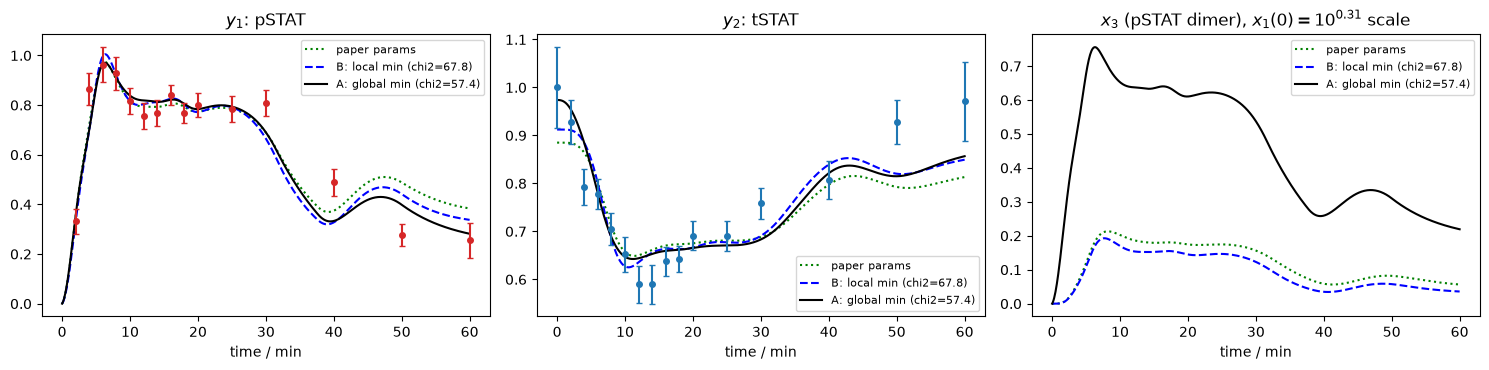

In [7]:
def optimal_scales(dyn_log10):
    # 给定 log10 (p1, p2, p3, p4, x1_0), 求 s1, s2 的加权最小二乘闭式解
    th = 10.0 ** np.array([*dyn_log10[:4], 0.0, 0.0, dyn_log10[4]])
    y1u, y2u, _ = observables(th, t_grid)
    a, b = y1u[i1] / pSTAT_sd, pSTAT / pSTAT_sd; c, d = y2u[i2] / tSTAT_sd, tSTAT / tSTAT_sd
    return (a @ b) / (a @ a), (c @ d) / (c @ c)

def to_x1_paper(lg):
    # 沿结构不可识别流形精确移动, 使 log10 x1(0) = 论文值 0.31 (chi2 不变)
    sh = lg[6] - paper_log10['x1_0']
    return np.array([lg[0], lg[1] + sh, lg[2], lg[3], lg[4] + sh, lg[5] + sh, lg[6] - sh])

dyn_paper = np.array([paper_log10[k] for k in ['p1', 'p2', 'p3', 'p4', 'x1_0']])
s1_p, s2_p = optimal_scales(dyn_paper)
x_paper = np.array([*dyn_paper[:4], np.log10(s1_p), np.log10(s2_p), dyn_paper[4]])
chi2_paper = chi2(x_paper)
q_paper = theta_to_q(x_paper)
chi2_from_paper, q_from_paper = fit_from(q_paper)     # 同样在 6 个组合参数中优化
x_from_paper = q_to_theta(q_from_paper)

# 收敛到论文吸引域 (局部极小 B) 的起点数
n_B = int(np.sum(np.abs(chi2_vals - chi2_from_paper) < 0.05)); n_A = int(np.sum(np.abs(chi2_vals - best_chi2) < 0.05))
print(f'(1) paper parameters (+ optimal s1 = {s1_p:.4f}, s2 = {s2_p:.4f}):  chi2 = {chi2_paper:.3f}')
print(f'(2) local optimum from paper start (minimum B):               chi2 = {chi2_from_paper:.3f}   ({n_B}/{len(chi2_vals)} random starts converge here)')
print(f'(3) multistart global optimum (minimum A):                    chi2 = {best_chi2:.3f}   ({n_A}/{len(chi2_vals)} random starts converge here)')
print(f'    Delta chi2 (B - A) = {chi2_from_paper - best_chi2:.2f}   -> current optimum is better than the paper basin\n')

rows_cmp = [('paper (Table 1)', x_paper), ('B: from paper start', to_x1_paper(x_from_paper)), ('A: global optimum', to_x1_paper(best_log))]
print('log10 values, structural representative with x1(0) = paper value 10^0.31:')
print(f"{'':22s}" + ''.join(f'{n:>8s}' for n in PNAMES) + f"{'p2*x1_0':>9s}{'tau=10/p4':>11s}")
for lab, lg in rows_cmp:
    print(f'{lab:22s}' + ''.join(f'{v:+8.2f}' for v in lg) + f'{lg[1] + lg[6]:+9.2f}{10 / 10**lg[3]:9.2f} min')

tt_ = np.linspace(0, 60, 601)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for lab, lg, sty in [('paper params', x_paper, 'g:'), (f'B: local min (chi2={chi2_from_paper:.1f})', x_from_paper, 'b--'), (f'A: global min (chi2={best_chi2:.1f})', best_log, 'k-')]:
    y1_, y2_, x_ = observables(10 ** lg, tt_)
    ax[0].plot(tt_, y1_, sty, label=lab); ax[1].plot(tt_, y2_, sty, label=lab)
    xr = x_ * 10 ** (paper_log10['x1_0'] - lg[6])          # 状态换算到 x1(0) = 论文值的等价尺度
    ax[2].plot(tt_, xr[2], sty, label=lab)
ax[0].errorbar(t_pSTAT, pSTAT, pSTAT_sd, fmt='o', color='tab:red', capsize=2, ms=4)
ax[1].errorbar(t_tSTAT, tSTAT, tSTAT_sd, fmt='o', color='tab:blue', capsize=2, ms=4)
ax[0].set_title('$y_1$: pSTAT'); ax[1].set_title('$y_2$: tSTAT'); ax[2].set_title('$x_3$ (pSTAT dimer), $x_1(0)=10^{0.31}$ scale')
for a in ax: a.set_xlabel('time / min'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. 拟合结果可视化

chi2 = 57.404,  N_data = 31,  chi2/dof = 2.296 (6 identifiable parameters)


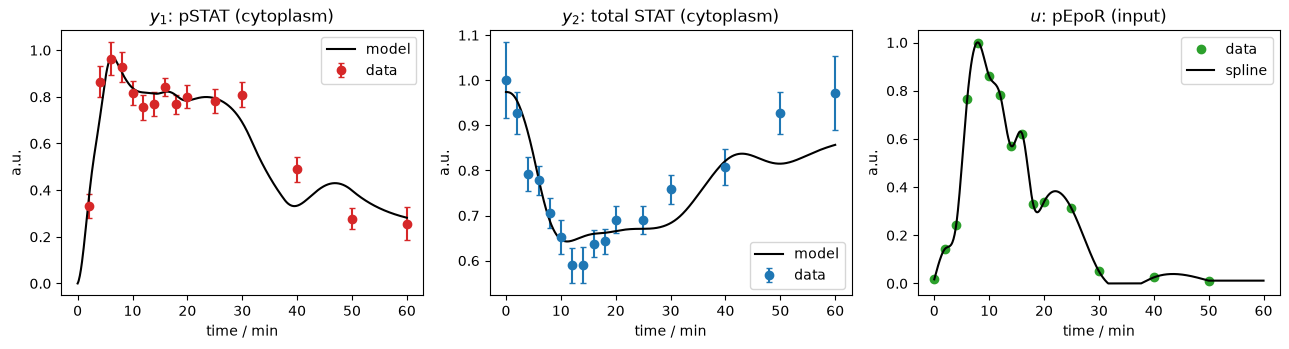

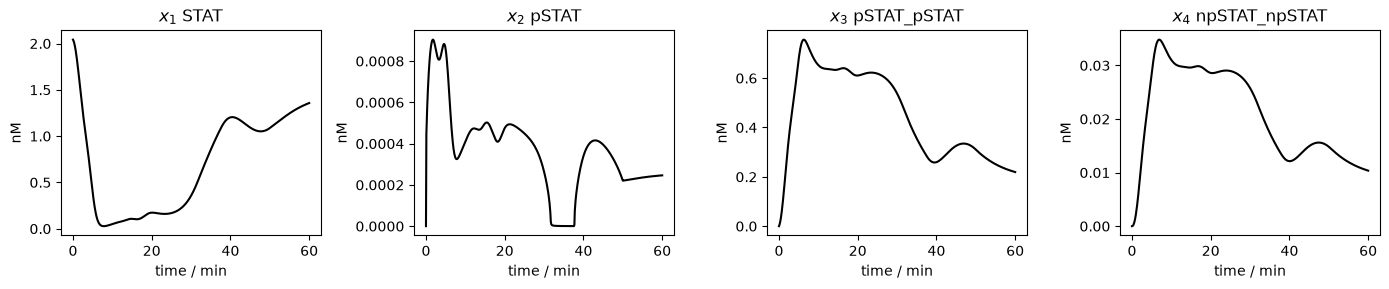

In [8]:
tt = np.linspace(0, 60, 601)
y1, y2, x = observables(best, tt)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].errorbar(t_pSTAT, pSTAT, pSTAT_sd, fmt='o', color='tab:red', capsize=2, label='data')
ax[0].plot(tt, y1, 'k-', label='model'); ax[0].set_title('$y_1$: pSTAT (cytoplasm)')
ax[1].errorbar(t_tSTAT, tSTAT, tSTAT_sd, fmt='o', color='tab:blue', capsize=2, label='data')
ax[1].plot(tt, y2, 'k-', label='model'); ax[1].set_title('$y_2$: total STAT (cytoplasm)')
ax[2].plot(t_pEpoR, pEpoR, 'o', color='tab:green', label='data')
ax[2].plot(tt, u_input(tt), 'k-', label='spline'); ax[2].set_title('$u$: pEpoR (input)')
for a in ax:
    a.set_xlabel('time / min'); a.set_ylabel('a.u.'); a.legend()
plt.tight_layout()

fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for k, name in enumerate(['$x_1$ STAT', '$x_2$ pSTAT', '$x_3$ pSTAT_pSTAT', '$x_4$ npSTAT_npSTAT']):
    ax[k].plot(tt, x[k], 'k-'); ax[k].set_title(name); ax[k].set_xlabel('time / min'); ax[k].set_ylabel('nM')
plt.tight_layout()

res = residuals(best_log)
print(f'chi2 = {np.sum(res**2):.3f},  N_data = {len(res)},  chi2/dof = {np.sum(res**2)/(len(res)-len(best_q)):.3f} (6 identifiable parameters)')

### 5b. 将数据与模型拟合结果保存为 MATLAB `.mat`

In [9]:
from scipy.io import savemat
y1_grid, y2_grid, _ = observables(best, t_grid)
# Gauss-Newton Hessian of chi2 in log10 space (same as Sec. 6)
def _num_jac(f, x, h=1e-5):
    f0 = f(x); Jm = np.empty((len(f0), len(x)))
    for j in range(len(x)):
        xp = x.copy(); xp[j] += h; xm = x.copy(); xm[j] -= h
        Jm[:, j] = (f(xp) - f(xm)) / (2 * h)
    return Jm
_Ja = jac_residuals(best_log); _H = 2 * _Ja.T @ _Ja; _w = np.linalg.eigvalsh(_H)   # 解析 Jacobian (有限差分在弱方向上被 ODE 误差淹没)
fit_out = dict(
    # 模型设置
    model='Raue 2009 JAK-STAT: 4 states + linear chain delay; y1 = s1*(x2+2*x3), y2 = s2*(x1+x2+2*x3)',
    N_CHAIN=N_CHAIN, param_names=np.array(PNAMES, dtype=object), n_starts=n_starts,
    # 优化变量: 6 个可识别组合 (log10); 7 参数表示取规范 log10 x1(0) = X1_GAUGE
    combo_names=np.array([n.replace('*', '') for n in QNAMES], dtype=object), log10_combo_fit=best_q, bounds_log10_combo=np.column_stack([lb_q, ub_q]), x1_gauge_log10=X1_GAUGE,
    # 最优解
    theta_fit=best, log10_theta_fit=best_log, chi2_min=best_chi2, N_data=len(t_pSTAT) + len(t_tSTAT), chi2_per_dof=best_chi2 / (len(t_pSTAT) + len(t_tSTAT) - 6),
    tau_delay_min=10.0 / best[3],
    # 多起点全部结果 (按 chi2 升序)
    multistart_chi2=np.array([z[0] for z in results]), multistart_log10_theta=np.array([q_to_theta(z[1]) for z in results]), multistart_log10_combo=np.array([z[1] for z in results]),
    # 论文 Table 1 值 (log10) 与论文参数检验 (4b)
    paper_log10=dict(p1=0.31, p2=-1.00, p3=-0.49, p4=0.42, x1_0=0.31),
    paper_check=dict(log10_theta_paper=x_paper, chi2_paper=chi2_paper, log10_theta_localmin_B=x_from_paper, chi2_localmin_B=chi2_from_paper, log10_combo_localmin_B=q_from_paper,
                     n_starts_to_A=n_A, n_starts_to_B=n_B, log10_A_x1paper=to_x1_paper(best_log), log10_B_x1paper=to_x1_paper(x_from_paper)),
    multistart_start_points_log10_combo=X0_sorted,   # 与 multistart_chi2 同序
    # 模型在数据时刻的预测与残差
    t_data=t_grid, y1_model_at_data=y1_grid, y2_model_at_data=y2_grid,
    residuals_weighted=res, residual_labels='first 15 = pSTAT (t>0), last 16 = tSTAT; residual = (model - data)/sd',
    # 平滑轨迹 (0-60 min)
    t_fine=tt, y1_model=y1, y2_model=y2, x_states=x, state_names=np.array(['x1_STAT', 'x2_pSTAT', 'x3_pSTAT_pSTAT', 'x4_npSTAT_npSTAT'] + [f'z{i+1}_delay_chain' for i in range(N_CHAIN)], dtype=object),
    # 输入样条
    u_pEpoR_fine=u_input(tt), u_spline_knots_t=t_pEpoR, u_spline_knots_value=pEpoR, u_spline_type='scipy CubicSpline natural, clipped >= 0, constant beyond 50 min',
    # Hessian (log10 空间, Gauss-Newton 近似, 解析 Jacobian)
    hessian_log10_GN=_H, hessian_eigenvalues=_w,
)
savemat('fit_results.mat', fit_out, long_field_names=True, do_compression=True)
print('saved fit_results.mat with fields:', list(fit_out.keys()))

saved fit_results.mat with fields: ['model', 'N_CHAIN', 'param_names', 'n_starts', 'combo_names', 'log10_combo_fit', 'bounds_log10_combo', 'x1_gauge_log10', 'theta_fit', 'log10_theta_fit', 'chi2_min', 'N_data', 'chi2_per_dof', 'tau_delay_min', 'multistart_chi2', 'multistart_log10_theta', 'multistart_log10_combo', 'paper_log10', 'paper_check', 'multistart_start_points_log10_combo', 't_data', 'y1_model_at_data', 'y2_model_at_data', 'residuals_weighted', 'residual_labels', 't_fine', 'y1_model', 'y2_model', 'x_states', 'state_names', 'u_pEpoR_fine', 'u_spline_knots_t', 'u_spline_knots_value', 'u_spline_type', 'hessian_log10_GN', 'hessian_eigenvalues']


## 6. 全局最优处 $\chi^2$ 的 Hessian（Gauss–Newton 近似）

用最优点处的**解析 Jacobian**（一阶灵敏度方程）近似 $H \approx 2J^TJ$（$\chi^2$ 的 Hessian，log10 参数空间）。
- 结构不可识别参数使 $H$ 奇异：有一个精确为零的特征值（方向为 $(p_2,s_1,s_2,x_1(0))$ 的缩放对称）。
- 最优点停在 $p_2x_1(0)$ 的上界，该方向的特征值也极小（但不为零）。中心差分 Jacobian 在这个方向上会被 ODE 求解误差淹没，所以这里不用它。

In [10]:
def num_jac(f, x, h=1e-5):
    f0 = f(x); J = np.empty((len(f0), len(x)))
    for j in range(len(x)):
        xp = x.copy(); xp[j] += h; xm = x.copy(); xm[j] -= h
        J[:, j] = (f(xp) - f(xm)) / (2 * h)
    return J

J = jac_residuals(best_log)                       # 解析 Jacobian; 有限差分 (num_jac) 在极弱方向上被 ODE 误差淹没
H = 2 * J.T @ J
w = np.linalg.eigvalsh(H)
print('Hessian eigenvalues (7 params, log10 space):', w)
print(f'numerical rank of J (SVD, machine-precision tolerance) = {np.linalg.matrix_rank(J)} of 7')
print('-> 最小特征值为 0 (舍入误差量级): 一维结构不可识别流形 (p2, s1, s2, x1(0))')
print('-> 第二小特征值很小但不为 0: p2*x1(0) 方向 (最优点停在其上界, chi2 沿该方向仍在缓慢下降)\n')


Hessian eigenvalues (7 params, log10 space): [     0.          0.        611.5871    954.7321   2317.7356  42306.0991
 166823.7209]
numerical rank of J (SVD, machine-precision tolerance) = 6 of 7
-> 最小特征值为 0 (舍入误差量级): 一维结构不可识别流形 (p2, s1, s2, x1(0))
-> 第二小特征值很小但不为 0: p2*x1(0) 方向 (最优点停在其上界, chi2 沿该方向仍在缓慢下降)



## 7. Profile likelihood 可识别性分析（参照 Raue 2009 Fig. 3 的范围与阈值）

$\chi^2_{\rm PL}(\theta_i)=\min_{\theta_{j\ne i}}\chi^2(\theta)$。与第 4 节一致，重优化在 6 个可识别组合上进行。
- **7 个原始参数**（上排，与论文 Fig. 3 对应）：
  - $p_1,p_3,p_4$：固定该参数，其余 5 个组合在边界内重优化（解析 Jacobian，从最优点向两侧外推）。
  - $p_2,s_1,s_2,x_1(0)$：固定其中一个为 $v$ 后，总能选 $x_1(0)$ 使 6 个组合仍等于全局最优，所以 profile 恒等于 $\chi^2_{\min}$（精确对称，结构不可识别）。这里沿对称流形把最优点移到 $\theta_i=v$ 并实际求解 ODE 计算 $\chi^2$ 作为数值验证。
- **3 个可识别组合**（下排）：$p_2x_1(0)$、$s_1x_1(0)$、$s_2x_1(0)$，固定该组合，其余 5 个重优化。$p_2x_1(0)$ 扫描 $[-3,9]$，超出拟合上界 6（蓝色点划线）以显示右侧的渐近行为；$s_1x_1(0)$、$s_2x_1(0)$ 的 profile 很陡，取半宽 0.1。
- **范围**：以当前最优为中心，取论文 Fig. 3 的宽度（$p_1$: 0.4，$p_2$: 4，$p_3$: 2，$p_4$、$x_1(0)$、$s_1$、$s_2$: 0.6）。
- **阈值**：逐点 1-σ 区间 $\Delta=\chi^2_1(0.68)\approx1.0$；联合 1-σ 区间 $\Delta=\chi^2_6(0.68)\approx7.0$（现在只有 6 个可识别参数；论文按 7 个参数取 $\chi^2_7(0.68)\approx8.1$）。
- **判定**（论文 Definition 1）：profile 两侧都超过阈值 → 可识别；有极小但至少一侧不超过 → 实际不可识别；整段平坦（变化 $<\Delta_{0.68}$）→ 结构不可识别。区间端点由 PCHIP 插值的 profile 与阈值的交点给出。

In [11]:
from scipy.stats import chi2 as chi2_dist
N_FREE = 6                                              # 可识别参数个数 (6 个组合)
thr_pw = chi2_dist.ppf(0.68, df=1); thr_sim = chi2_dist.ppf(0.68, df=N_FREE)
print(f'thresholds: pointwise = {thr_pw:.3f}, simultaneous (df={N_FREE}) = {thr_sim:.3f}')

def profile_q(iq, grid, start_q):
    # 6 维组合空间中的 profile: 固定 q[iq] = v, 其余 5 个组合在边界内重优化 (解析 Jacobian);
    # 从最优点向两侧外推, 每个网格点的起点 = 全局最优 + 相邻 (更靠内) 网格点的解
    lo, hi = np.delete(lb_q, iq), np.delete(ub_q, iq)
    out = np.empty(len(grid)); qs = np.empty((len(grid), 6)); k0 = int(np.argmin(np.abs(grid - start_q[iq])))
    def solve(v, prev):
        f = lambda z: residuals_q(np.insert(z, iq, v)); fj = lambda z: np.delete(jac_q(np.insert(z, iq, v)), iq, axis=1)
        cands = []
        for z0 in [np.delete(start_q, iq)] + ([prev] if prev is not None else []):
            r = least_squares(f, np.clip(z0, lo, hi), jac=fj, bounds=(lo, hi), x_scale='jac', max_nfev=800)
            cands.append((2 * r.cost, r.x))
        return min(cands, key=lambda z: z[0])
    for side in (range(k0, len(grid)), range(k0, -1, -1)):
        prev = None
        for k in side:
            out[k], prev = solve(grid[k], prev); qs[k] = np.insert(prev, iq, grid[k])
    return out, qs

def profile_structural(i7, grid):
    # p2, s1, s2, x1_0: 固定 theta_i = v, 其余 6 个参数自由 (无单独边界) -> 总能选 x1(0) 使 6 个组合等于全局最优,
    # 因此 profile = chi2_min (精确对称). 这里沿对称流形把最优点移到 theta_i = v 并实际求解 ODE 计算 chi2, 作为数值验证.
    out = np.empty(len(grid))
    for k, v in enumerate(grid):
        x1 = v if i7 == 6 else best_q[i7] - v            # i7 = 1 (p2), 4 (s1), 5 (s2) 与 q 的索引相同
        out[k] = chi2(q_to_theta(best_q, x1))
    return out

def _with_center(g, c):
    # 加入最优点, 并去掉离它不到 1/4 网格间距的节点 (避免近重复节点使 PCHIP 在最小值处出现虚假斜率)
    g = np.asarray(g, float); g = g[np.abs(g - c) > 0.25 * np.min(np.diff(np.sort(g)))]
    return np.sort(np.append(g, c))

def _window(center, hw, lo, hi, n):
    # 宽度保持论文值; 若窗口越过边界则整体平移到边界内
    a = np.clip(center - hw, lo, hi - 2 * hw); return np.linspace(a, a + 2 * hw, n)

N_GRID = 17
# (a) 7 个原始参数 (与论文 Fig. 3 对应): p1, p3, p4 在 6 维空间中 profile; p2, s1, s2, x1_0 沿对称流形
half_width = {'p1': 0.2, 'p2': 2.0, 'p3': 1.0, 'p4': 0.3, 's1': 0.3, 's2': 0.3, 'x1_0': 0.3}
grids = {}
for i, n in enumerate(PNAMES):
    g = _window(best_log[i], half_width[n], -3, 3, N_GRID) if n in ('p1', 'p3', 'p4') else np.linspace(best_log[i] - half_width[n], best_log[i] + half_width[n], N_GRID)
    grids[n] = _with_center(g, best_log[i])
# (b) 3 个组合: P2 扫描 [-3, 9] (超出拟合上界 6 以显示右侧渐近行为); S1, S2 的 profile 很陡, 取半宽 0.1
CNAMES = ['p2*x1_0', 's1*x1_0', 's2*x1_0']; CIDX = {'p2*x1_0': 1, 's1*x1_0': 4, 's2*x1_0': 5}
grids_c = {'p2*x1_0': np.linspace(-3, 9, 25), 's1*x1_0': _window(best_q[4], 0.1, -6, 6, 21), 's2*x1_0': _window(best_q[5], 0.1, -6, 6, 21)}
grids_c = {n: _with_center(g, best_q[CIDX[n]]) for n, g in grids_c.items()}

# 6 个需要重优化的 profile 按参数并行 (每个进程内部仍顺序外推)
jobs = [('theta', 'p1', 0), ('theta', 'p3', 2), ('theta', 'p4', 3)] + [('combo', n, CIDX[n]) for n in CNAMES]
def _run_job(job):
    kind, n, iq = job
    return profile_q(iq, grids[n] if kind == 'theta' else grids_c[n], best_q)
_t0 = time.time()
try:
    with mp.get_context('fork').Pool(len(jobs)) as pool: _res = pool.map(_run_job, jobs)
except Exception as e:
    print('parallel pool failed, running serially:', e); _res = [_run_job(j) for j in jobs]
profiles, profiles_c, profile_paths = {}, {}, {}
for (kind, n, iq), (pl, qs) in zip(jobs, _res):
    (profiles if kind == 'theta' else profiles_c)[n] = pl; profile_paths[n] = qs
for i, n in [(1, 'p2'), (4, 's1'), (5, 's2'), (6, 'x1_0')]:
    profiles[n] = profile_structural(i, grids[n])
print(f'profiles done in {time.time() - _t0:.0f} s')
for n in PNAMES: print(f'  {n:8s} chi2_PL range [{profiles[n].min():.3f}, {profiles[n].max():.3f}]')
for n in CNAMES: print(f'  {n:8s} chi2_PL range [{profiles_c[n].min():.3f}, {profiles_c[n].max():.3f}]')

thresholds: pointwise = 0.989, simultaneous (df=6) = 7.009


profiles done in 142 s
  p1       chi2_PL range [57.404, 76.466]
  p2       chi2_PL range [57.404, 57.404]
  p3       chi2_PL range [57.404, 254.179]
  p4       chi2_PL range [57.404, 126.285]
  s1       chi2_PL range [57.404, 57.404]
  s2       chi2_PL range [57.404, 57.404]
  x1_0     chi2_PL range [57.404, 57.404]
  p2*x1_0  chi2_PL range [57.393, 322.488]
  s1*x1_0  chi2_PL range [57.404, 90.698]
  s2*x1_0  chi2_PL range [57.404, 169.900]


chi2_min = 57.404

(a) 7 original parameters (structural representative: log10 x1(0) = 0.31)
param    log10 fit |       pointwise (Δ=0.99)       |     simultaneous (Δ=7.01)      | verdict (pointwise)
p1           +0.27 | [ +0.23,  +0.32]  identifiable           | [ +0.15,  +0.39]  identifiable           | identifiable
p2           +5.69 | [   —  ,    —  ]  structurally non-ident | [   —  ,    —  ]  structurally non-ident | structurally non-identifiable (flat)
p3           -1.05 | [ -1.09,  -1.01]  identifiable           | [ -1.17,  -0.87]  identifiable           | identifiable
p4           +0.28 | [ +0.23,  +0.33]  identifiable           | [ +0.17,  +0.42]  identifiable           | identifiable
s1           -0.19 | [   —  ,    —  ]  structurally non-ident | [   —  ,    —  ]  structurally non-ident | structurally non-identifiable (flat)
s2           -0.32 | [   —  ,    —  ]  structurally non-ident | [   —  ,    —  ]  structurally non-ident | structurally non-identifiable (flat)
x1_0    

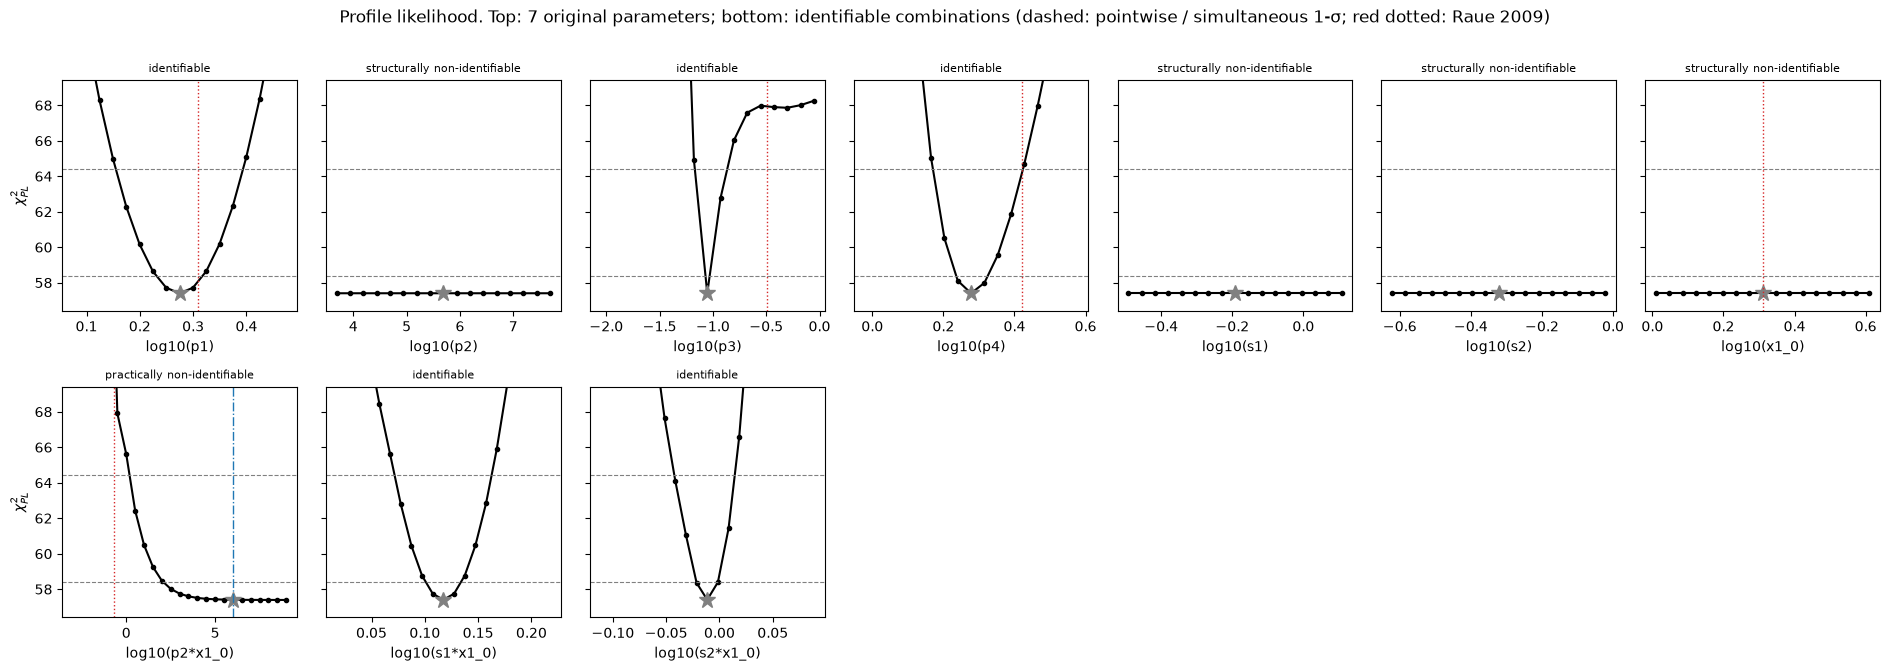

saved profile_likelihood.npz


In [12]:
from scipy.interpolate import PchipInterpolator
def classify(g, pl, ghat, chi2min, thr, flat_tol=None):
    # 判定与区间: 用 PCHIP 插值后的 profile 求与阈值的交点; None 表示在扫描范围内未超阈值
    flat_tol = thr_pw if flat_tol is None else flat_tol
    if pl.max() - pl.min() < flat_tol: return 'structurally non-identifiable (flat)', None, None
    level = chi2min + thr; f = PchipInterpolator(g, pl)
    def crossing(gg):
        vals = f(gg); idx = np.where(vals > level)[0]
        if len(idx) == 0: return None
        k = idx[0]; return gg[k] if k == 0 else gg[k-1] + (level - vals[k-1]) * (gg[k] - gg[k-1]) / (vals[k] - vals[k-1])
    gl = crossing(np.linspace(ghat, g[0], 2001)); gr = crossing(np.linspace(ghat, g[-1], 2001))
    if gl is not None and gr is not None: verdict = 'identifiable'
    else: verdict = 'practically non-identifiable (' + ('lower' if gl is None else '') + ('/' if gl is None and gr is None else '') + ('upper' if gr is None else '') + ' unbounded)'
    return verdict, gl, gr

def _summarize(names, grid_d, prof_d, fit_d):
    out = {}
    for n in names:
        g, pl, gh = grid_d[n], prof_d[n], fit_d[n]
        v1, l1, r1 = classify(g, pl, gh, best_chi2, thr_pw); v2, l2, r2 = classify(g, pl, gh, best_chi2, thr_sim)
        fmt = lambda x: f'{x:+.2f}' if x is not None else '  —  '
        print(f"{n:8s} {gh:>+9.2f} | [{fmt(l1):>6s}, {fmt(r1):>6s}]  {v1[:22]:22s} | [{fmt(l2):>6s}, {fmt(r2):>6s}]  {v2[:22]:22s} | {v1}")
        out[n] = dict(grid=g, chi2_PL=pl, verdict_pw=v1, ci_pw=(l1, r1), verdict_sim=v2, ci_sim=(l2, r2))
    return out

print(f"chi2_min = {best_chi2:.3f}\n")
hdr = f"{'param':8s} {'log10 fit':>9s} | {'pointwise (Δ=%.2f)' % thr_pw:^30s} | {'simultaneous (Δ=%.2f)' % thr_sim:^30s} | verdict (pointwise)"
print('(a) 7 original parameters (structural representative: log10 x1(0) = %.2f)' % X1_GAUGE); print(hdr)
pl_summary = _summarize(PNAMES, grids, profiles, dict(zip(PNAMES, best_log)))
print('\n(b) identifiable combinations'); print(hdr)
pl_summary_c = _summarize(CNAMES, grids_c, profiles_c, {n: best_q[CIDX[n]] for n in CNAMES})

paper_log10_all = {'p1': 0.31, 'p2': -1.00, 'p3': -0.49, 'p4': 0.42, 'x1_0': 0.31, 'p2*x1_0': -0.69}
fig, ax = plt.subplots(2, 7, figsize=(19, 6.6), sharey=True)
def _panel(a, g, pl, gh, n, verdict):
    a.plot(g, pl, 'k.-', lw=1.5); a.plot(gh, best_chi2, '*', color='gray', ms=12)
    a.axhline(best_chi2 + thr_pw, ls='--', color='gray', lw=0.8); a.axhline(best_chi2 + thr_sim, ls='--', color='gray', lw=0.8)
    if n in paper_log10_all and g.min() <= paper_log10_all[n] <= g.max(): a.axvline(paper_log10_all[n], color='tab:red', ls=':', lw=1)
    a.set_xlabel(f'log10({n})'); a.set_title(verdict.split(' (')[0], fontsize=8); a.set_ylim(best_chi2 - 1, best_chi2 + 12)
for a, (i, n) in zip(ax[0], enumerate(PNAMES)): _panel(a, grids[n], profiles[n], best_log[i], n, pl_summary[n]['verdict_pw'])
for a, n in zip(ax[1], CNAMES): _panel(a, grids_c[n], profiles_c[n], best_q[CIDX[n]], n, pl_summary_c[n]['verdict_pw'])
ax[1][0].axvline(ub_q[1], color='tab:blue', ls='-.', lw=1)          # p2*x1_0 的拟合上界
for a in ax[1][3:]: a.axis('off')
ax[0][0].set_ylabel('$\\chi^2_{PL}$'); ax[1][0].set_ylabel('$\\chi^2_{PL}$')
plt.suptitle('Profile likelihood. Top: 7 original parameters; bottom: identifiable combinations (dashed: pointwise / simultaneous 1-σ; red dotted: Raue 2009)', y=1.01)
plt.tight_layout(); plt.show()
np.savez('profile_likelihood.npz', **{f'grid_{n}': grids[n] for n in PNAMES}, **{f'chi2PL_{n}': profiles[n] for n in PNAMES},
         **{f'grid_{n.replace("*", "")}': grids_c[n] for n in CNAMES}, **{f'chi2PL_{n.replace("*", "")}': profiles_c[n] for n in CNAMES},
         chi2_min=best_chi2, thr_pw=thr_pw, thr_sim=thr_sim)
print('saved profile_likelihood.npz')

### 7b. 将 profile likelihood 曲线保存为 MATLAB `.mat`

In [13]:
# 把第 7 节各参数的 profile likelihood 曲线保存为 MATLAB .mat
#   PL.<param>: 7 个原始参数 (与 profile_likelihood.m 兼容);  PL_combo.<p2x1_0 | s1x1_0 | s2x1_0>: 3 个可识别组合
from scipy.io import savemat
def _num(x): return np.nan if x is None else float(x)
def _pl_struct(n, grid_d, prof_d, summ, fit_log):
    return dict(name=n, log10_grid=grid_d[n], chi2_PL=prof_d[n], delta_chi2=prof_d[n] - best_chi2,
                log10_fit=float(fit_log), theta_fit=float(10 ** fit_log),
                ci_pointwise_log10=np.array([_num(summ[n]['ci_pw'][0]), _num(summ[n]['ci_pw'][1])]),
                ci_simultaneous_log10=np.array([_num(summ[n]['ci_sim'][0]), _num(summ[n]['ci_sim'][1])]),
                verdict_pointwise=summ[n]['verdict_pw'], verdict_simultaneous=summ[n]['verdict_sim'])
PL_struct = {n: _pl_struct(n, grids, profiles, pl_summary, best_log[i]) for i, n in enumerate(PNAMES)}
PL_combo = {n.replace('*', ''): _pl_struct(n, grids_c, profiles_c, pl_summary_c, best_q[CIDX[n]]) for n in CNAMES}
for n in CNAMES: PL_combo[n.replace('*', '')]['optimized_combinations_log10'] = profile_paths[n]
savemat('profile_likelihood.mat',
        dict(PL=PL_struct, param_names=np.array(PNAMES, dtype=object), chi2_min=best_chi2,
             threshold_pointwise=thr_pw, threshold_simultaneous=thr_sim, n_free_parameters=N_FREE,
             theta_fit=best, log10_theta_fit=best_log, x1_gauge_log10=X1_GAUGE,
             PL_combo=PL_combo, combo_names=np.array([n.replace('*', '') for n in CNAMES], dtype=object), log10_combo_fit=best_q,
             bounds_log10_combo=np.column_stack([lb_q, ub_q]),
             note=('Optimization is over 6 identifiable combinations q = log10(p1, p2*x1_0, p3, p4, s1*x1_0, s2*x1_0). '
                   'PL.<param>: profiles of the 7 original parameters; p1, p3, p4 re-optimize the other 5 combinations, '
                   'p2, s1, s2, x1_0 are exactly flat by the scaling symmetry. PL_combo: profiles of the 3 combinations. '
                   'NaN CI bound = unbounded within the scanned range. PL_combo.p2x1_0 is scanned beyond the fit bound (log10 = 6); there chi2 keeps '
                   'decreasing slightly, so delta_chi2 is slightly negative (about -0.01).')),
        long_field_names=True, do_compression=True)
print('saved profile_likelihood.mat  ->  MATLAB usage:  S = load("profile_likelihood.mat"); plot(S.PL.p1.log10_grid, S.PL.p1.chi2_PL); plot(S.PL_combo.p2x1_0.log10_grid, S.PL_combo.p2x1_0.chi2_PL)')

saved profile_likelihood.mat  ->  MATLAB usage:  S = load("profile_likelihood.mat"); plot(S.PL.p1.log10_grid, S.PL.p1.chi2_PL); plot(S.PL_combo.p2x1_0.log10_grid, S.PL_combo.p2x1_0.chi2_PL)


## 8. 按 Hao & Wang (M3AS manuscript) 的设置计算 $J_\eta$, $H_\eta$, $F_\eta$, $K_\eta$

**设置**（manuscript Sec. 1, Eqs. 1.15–1.20）
- 对数坐标 $\eta=\ln\theta$，$D_*=\mathrm{diag}(\theta^*)$；损失 $l(\eta)=\tfrac12\sum_n\|h(t_n,\eta)-\hat h_n\|_2^2$。
  这里数据误差非齐次，故把观测量按 $\sigma_{n,l}$ 标准化：$h\to h/\sigma$，使 $l=\tfrac12\chi^2$（"loss expressed in units of the noise variance"）。
- 每个观测时刻的 Jacobian $J_{\eta,n}=\nabla_\eta h(t_n,\eta^*)\in\mathbb R^{L\times k}$，二阶方向响应 $(H_{\eta,n}[u,w])_l=u^\top\nabla^2_\eta h_l(t_n,\eta^*)w$；
  按时刻堆叠得 $J_\eta\in\mathbb R^{NL\times k}$，$H_\eta\in\mathbb R^{NL\times k\times k}$。
- 链式法则 (Eqs. 1.16, 1.17)：$J_\eta=J_\theta D_*$，$\nabla^2_\eta h_l=D_*\nabla^2_\theta h_l D_*+\mathrm{diag}(\theta^*\odot\nabla_\theta h_l)$。
- Gauss–Newton / Fisher 信息矩阵 $F_\eta=J_\eta^\top J_\eta$；残差修正 Hessian (Eq. 1.20)
  $K_\eta=\nabla^2_\eta l=F_\eta+C_\eta,\quad C_\eta=\sum_{n,l}r^*_{n,l}\nabla^2_\eta h_l(t_n,\eta^*)$，$r^*=h(t,\eta^*)-\hat h$。
- $\nabla_\theta h$、$\nabla^2_\theta h$ 按 manuscript 附录 3.1 用前向灵敏度 ODE（Eqs. 3.2–3.10）计算：
  $\dot y=\partial_x f\,y+\partial_\theta f$，$\dot z_{\cdot jp}=(\partial_x f) z_{\cdot jp}+(\partial_{xx}f[y_p])y_j+\partial_{x\theta_p}f\,y_j+\partial_{x\theta_j}f\,y_p$。
  $x_1(0)$ 是参数，故 $y(0)$ 中对应列为 $e_1$，其余初值为 0。

$\theta=(p_1,p_2,p_3,p_4,s_1,s_2,x_1(0))$，$k=7$；$N L=15+16=31$。

In [14]:
KO = 5                    # 进入 ODE 的参数: p1,p2,p3,p4,x1_0
NX = 4 + N_CHAIN
IDX_ODE = [0, 1, 2, 3, 6]  # 它们在完整 theta 中的位置

def A_mat(x, u, p1, p2, p3, p4):          # df/dx
    A = np.zeros((NX, NX)); x2 = x[1]
    A[0, 0] = -p1 * u; A[0, NX - 1] = 2 * p4
    A[1, 0] = p1 * u;  A[1, 1] = -2 * p2 * x2
    A[2, 1] = p2 * x2; A[2, 2] = -p3
    A[3, 2] = p3;      A[3, 3] = -p4
    A[4, 3] = p4;      A[4, 4] = -p4
    for i in range(5, NX): A[i, i - 1] = p4; A[i, i] = -p4
    return A

def dA_dir(v, p2):                        # (d^2 f/dx dx)[v]  (A 只通过 x2 依赖 x)
    dA = np.zeros((NX, NX)); dA[1, 1] = -2 * p2 * v[1]; dA[2, 1] = p2 * v[1]; return dA

def B_mat(x, u, p1, p2, p3, p4):          # df/dtheta_ode
    x1, x2, x3, x4 = x[:4]; z = x[4:]; B = np.zeros((NX, KO))
    B[0, 0] = -x1 * u; B[1, 0] = x1 * u
    B[1, 1] = -x2**2;  B[2, 1] = 0.5 * x2**2
    B[2, 2] = -x3;     B[3, 2] = x3
    B[0, 3] = 2 * z[-1]; B[3, 3] = -x4; B[4, 3] = x4 - z[0]; B[5:, 3] = z[:-1] - z[1:]
    return B

def dB_dir(x, v, u):                      # (d^2 f/dx dtheta)[v]
    x2 = x[1]; dB = np.zeros((NX, KO))
    dB[0, 0] = -v[0] * u; dB[1, 0] = v[0] * u
    dB[1, 1] = -2 * x2 * v[1]; dB[2, 1] = x2 * v[1]
    dB[2, 2] = -v[2]; dB[3, 2] = v[2]
    dB[0, 3] = 2 * v[-1]; dB[3, 3] = -v[3]; dB[4, 3] = v[3] - v[4]; dB[5:, 3] = v[4:-1] - v[5:]
    return dB

def aug_rhs(t, s, p1, p2, p3, p4):
    x = s[:NX]; y = s[NX:NX + NX * KO].reshape(NX, KO); z = s[NX + NX * KO:].reshape(NX, KO, KO)
    u = u_input(t); A = A_mat(x, u, p1, p2, p3, p4); B = B_mat(x, u, p1, p2, p3, p4)
    dx = rhs(t, x, p1, p2, p3, p4)
    dy = A @ y + B                                   # Eq. (3.3)
    dz = np.einsum('im,mjp->ijp', A, z)              # Eq. (3.4) Term 1
    for p in range(KO):
        dBp = dB_dir(x, y[:, p], u)
        dz[:, :, p] += dA_dir(y[:, p], p2) @ y + dBp # Terms 2,3
        dz[:, p, :] += dBp                           # Term 4 (对称项); d^2f/dtheta^2 = 0
    return np.concatenate([dx, dy.ravel(), dz.ravel()])

def sensitivities(theta, t_eval):
    p1, p2, p3, p4, s1, s2, x1_0 = theta
    x0 = np.zeros(NX); x0[0] = x1_0
    y0 = np.zeros((NX, KO)); y0[0, 4] = 1.0
    s0 = np.concatenate([x0, y0.ravel(), np.zeros(NX * KO * KO)])
    sol = solve_ivp(aug_rhs, (0, t_eval[-1]), s0, t_eval=t_eval, args=(p1, p2, p3, p4),
                    method='LSODA', rtol=1e-10, atol=1e-12)
    assert sol.success, sol.message
    S = sol.y.T; n = len(t_eval)
    return S[:, :NX], S[:, NX:NX + NX * KO].reshape(n, NX, KO), S[:, NX + NX * KO:].reshape(n, NX, KO, KO)

def model_derivatives(theta, t_eval):
    # 返回 h (n,L), grad_theta h (n,L,k), Hess_theta h (n,L,k,k);  h1 = s1(x2+2x3), h2 = s2(x1+x2+2x3)
    s1, s2 = theta[4], theta[5]
    x, y, z = sensitivities(theta, t_eval); n = len(t_eval)
    c1 = np.zeros(NX); c1[1] = 1; c1[2] = 2
    c2 = np.zeros(NX); c2[0] = 1; c2[1] = 1; c2[2] = 2
    h = np.zeros((n, 2)); J = np.zeros((n, 2, 7)); H = np.zeros((n, 2, 7, 7))
    ix = np.ix_(IDX_ODE, IDX_ODE)
    for l, (c, s, i_s) in enumerate([(c1, s1, 4), (c2, s2, 5)]):
        g = x @ c; gy = np.einsum('m,nmj->nj', c, y); gz = np.einsum('m,nmjp->njp', c, z)
        h[:, l] = s * g
        J[:, l, IDX_ODE] = s * gy; J[:, l, i_s] = g
        H[:, l][:, ix[0], ix[1]] = s * gz
        H[:, l, i_s, IDX_ODE] = gy; H[:, l, IDX_ODE, i_s] = gy
    return h, J, H

# 有限差分验证 (在全局最优点)
h0, J0, H0 = model_derivatives(best, t_grid)
Jfd = np.zeros_like(J0); Hfd = np.zeros_like(H0)
for j in range(7):
    e = np.zeros(7); e[j] = 1e-6 * max(1.0, abs(best[j]))
    hp, Jp, _ = model_derivatives(best + e, t_grid); hm, Jm, _ = model_derivatives(best - e, t_grid)
    Jfd[..., j] = (hp - hm) / (2 * e[j]); Hfd[..., j] = (Jp - Jm) / (2 * e[j])
print('grad_theta h  vs 有限差分: max rel err =', np.abs(J0 - Jfd).max() / np.abs(J0).max())
print('Hess_theta h  vs 有限差分: max rel err =', np.abs(H0 - Hfd).max() / np.abs(H0).max())
print('模型输出 vs observables(): max abs diff =', np.abs(h0[:, 0] - observables(best, t_grid)[0]).max())

grad_theta h  vs 有限差分: max rel err = 1.1294986754146463e-05
Hess_theta h  vs 有限差分: max rel err = 2.917608614945033e-06
模型输出 vs observables(): max abs diff = 1.6627566878923972e-08


### 8.1 组装 $J_\eta$, $H_\eta$, $F_\eta$, $K_\eta$ 并做特征分解

按 manuscript 的堆叠顺序，先按观测时刻 $n$、再按观测分量 $l$ 排列（$y_1$ 在 $t=0$ 无数据，该行省略），共 $NL=31$ 行。
同时给出 Theorem 2 的量：$[U,V]$（$F_\eta$ 的非零/零特征空间）、$E=U^\top C_\eta U$、$B=U^\top C_\eta V$、$D=V^\top C_\eta V$、$A=\Lambda+E$、
相对曲率变化 $\epsilon_U=\|\Lambda^{-1/2}E\Lambda^{-1/2}\|_2$ (Eq. 1.33)、Schur 补 $S=D-B^\top A^{-1}B$ (Eq. 1.35)、
$\ker K_\eta$ 与 $\ker J_\eta$ 的最大主角 $\tan\vartheta_{\max}=\|A^{-1}BW_0\|_2$ (Eq. 1.40)、以及 $\|\sin\Theta_U\|_2=\|T_{21}\|_2$ (Eq. 1.43)。

In [15]:
ETA_NAMES = [f'ln {n}' for n in PNAMES]

def build_eta_matrices(theta):
    # 堆叠索引: 每个时刻 n 先 y1(pSTAT) 再 y2(tSTAT); 以 sigma 标准化
    h, Jt, Ht = model_derivatives(theta, t_grid)
    rows_h, rows_J, rows_H, rows_r, labels = [], [], [], [], []
    for n, tn in enumerate(t_grid):
        for l, (tl, yl, sdl) in enumerate([(t_pSTAT, pSTAT, pSTAT_sd), (t_tSTAT, tSTAT, tSTAT_sd)]):
            m = np.where(np.isclose(tl, tn))[0]
            if len(m) == 0: continue
            sd = sdl[m[0]]
            rows_h.append(h[n, l] / sd); rows_r.append((h[n, l] - yl[m[0]]) / sd)
            rows_J.append(Jt[n, l] / sd); rows_H.append(Ht[n, l] / sd); labels.append((tn, l))
    J_theta = np.array(rows_J); H_theta = np.array(rows_H); r_star = np.array(rows_r)
    D = np.diag(theta)
    J_eta = J_theta @ D                                                          # Eq. (1.16)
    H_eta = np.einsum('ij,njk,kl->nil', D, H_theta, D) + \
            np.einsum('nj,jk->njk', theta[None, :] * J_theta, np.eye(7))        # Eq. (1.17)
    F_eta = J_eta.T @ J_eta                                                      # Fisher / Gauss-Newton
    C_eta = np.einsum('n,nij->ij', r_star, H_eta)                                # 残差修正
    K_eta = F_eta + C_eta                                                        # Eq. (1.20)
    return dict(J_eta=J_eta, H_eta=H_eta, F_eta=F_eta, C_eta=C_eta, K_eta=K_eta, r_star=r_star,
                J_theta=J_theta, H_theta=H_theta, labels=labels)

def eig_desc(M):
    w, V = np.linalg.eigh((M + M.T) / 2); o = np.argsort(w)[::-1]; return w[o], V[:, o]

def theorem2_analysis(M, tol_rel=1e-8):
    F, C, K, J = M['F_eta'], M['C_eta'], M['K_eta'], M['J_eta']
    lamF, UF = eig_desc(F); lamK, UK = eig_desc(K)
    r = int(np.linalg.matrix_rank(J))            # SVD 数值秩 (机器精度容差); 弱方向 (sigma/sigma_max ~ 1e-5) 不应被当作零空间
    U, V = UF[:, :r], UF[:, r:]; Lam = np.diag(lamF[:r])
    E = U.T @ C @ U; B = U.T @ C @ V; Dm = V.T @ C @ V; A = Lam + E
    Lih = np.diag(lamF[:r] ** -0.5); M_rel = Lih @ E @ Lih
    eps_U = np.linalg.norm(M_rel, 2); A_pd = np.linalg.eigvalsh((A + A.T) / 2).min() > 0
    out = dict(lamF=lamF, UF=UF, lamK=lamK, UK=UK, r=r, U=U, V=V, E=E, B=B, D=Dm, A=A, eps_U=eps_U,
               lam_min_rel=np.linalg.eigvalsh((M_rel + M_rel.T) / 2).min(), A_pd=A_pd)
    if A_pd and V.shape[1] > 0:
        S = Dm - B.T @ np.linalg.solve(A, B); lamS, WS = eig_desc(S)
        s_rank = int(np.sum(lamS > tol_rel * max(lamF[0], 1)))
        W0 = WS[:, s_rank:]
        out.update(S=S, lamS=lamS, s_rank=s_rank, W0=W0,
                   tan_theta_max=np.linalg.norm(np.linalg.solve(A, B) @ W0, 2) if W0.shape[1] else 0.0,
                   ker_dim_K=V.shape[1] - s_rank)
    # Eq. (1.41)-(1.43): 在 [U,V] 坐标下的 K 的特征向量 T, 取前 r 列
    Mk = np.block([[A, B], [B.T, Dm]]); _, T = eig_desc(Mk); T21 = T[r:, :r]
    out['sin_Theta_U'] = np.linalg.norm(T21, 2) if T21.size else 0.0
    out['U_tilde'] = U @ T[:r, :r] + V @ T21
    return out

def report(theta, label):
    M = build_eta_matrices(theta); R = theorem2_analysis(M)
    J, F, C, K, r = M['J_eta'], M['F_eta'], M['C_eta'], M['K_eta'], M['r_star']
    print('=' * 78); print(f'{label}:  theta* =', np.round(theta, 4))
    print(f'J_eta shape {J.shape},  H_eta shape {M["H_eta"].shape},  chi2 = ||r*||^2 = {np.sum(r**2):.3f}')
    print(f'一阶最优性 ||J_eta^T r*||_2 = {np.linalg.norm(J.T @ r):.3e}   (内点极小值应≈0)')
    print(f'||F_eta||_2 = {np.linalg.norm(F, 2):.4g},  ||C_eta||_2 = {np.linalg.norm(C, 2):.4g},  ||K_eta||_2 = {np.linalg.norm(K, 2):.4g}')
    print('\n特征值 (降序):')
    print(f"{'i':>2s} {'lambda(F_eta)':>15s} {'lambda(K_eta)':>15s}")
    for i in range(7): print(f'{i+1:2d} {R["lamF"][i]:15.6g} {R["lamK"][i]:15.6g}')
    sJ = np.linalg.svd(J, compute_uv=False)
    print(f'\nsingular values of J_eta: {np.array2string(sJ, precision=3)}')
    print(f'rank(F_eta) = rank(J_eta) = {R["r"]} (SVD 数值秩),  ker(F_eta) = ker(J_eta) 维数 = {7 - R["r"]}')
    print('\nF_eta 特征向量 (列 = 特征向量, 行 = ln 参数):')
    print('        ' + ' '.join(f'{"u"+str(i+1):>8s}' for i in range(7)))
    for j in range(7): print(f'{ETA_NAMES[j]:8s}' + ' '.join(f'{R["UF"][j,i]:8.3f}' for i in range(7)))
    print('\nK_eta 特征向量:')
    print('        ' + ' '.join(f'{"v"+str(i+1):>8s}' for i in range(7)))
    for j in range(7): print(f'{ETA_NAMES[j]:8s}' + ' '.join(f'{R["UK"][j,i]:8.3f}' for i in range(7)))
    print('\nTheorem 2 量:')
    print(f'  eps_U = ||Lam^-1/2 E Lam^-1/2||_2 = {R["eps_U"]:.4g};  lambda_min(Lam^-1/2 E Lam^-1/2) = {R["lam_min_rel"]:.4g}  (> -1 <=> A ≻ 0: {R["A_pd"]})')
    if 'S' in R:
        print(f'  D = V^T C V = {np.round(R["D"], 6).tolist()}')
        print(f'  Schur 补 S 的特征值 = {np.round(R["lamS"], 6).tolist()},  rank(S) = {R["s_rank"]}  ->  dim ker(K_eta) = {R["ker_dim_K"]}')
        print(f'  ||B||_2 = {np.linalg.norm(R["B"], 2):.4g},  tan(theta_max) = ||A^-1 B W0||_2 = {R["tan_theta_max"]:.4g}')
    print(f'  ||sin Theta_U||_2 = ||T21||_2 = {R["sin_Theta_U"]:.4g}   (range(U) 与 K_eta 前 r 个特征向量张成空间之间)')
    return M, R

M_A, R_A = report(best, '7 参数全局最优')

7 参数全局最优:  theta* = [     1.8817 489777.9198      0.0885      1.8961      0.6418      0.477
      2.0417]
J_eta shape (31, 7),  H_eta shape (31, 7, 7),  chi2 = ||r*||^2 = 57.404
一阶最优性 ||J_eta^T r*||_2 = 3.718e-03   (内点极小值应≈0)
||F_eta||_2 = 1.573e+04,  ||C_eta||_2 = 19.01,  ||K_eta||_2 = 1.573e+04

特征值 (降序):
 i   lambda(F_eta)   lambda(K_eta)
 1         15732.5         15731.2
 2         3989.71         3988.57
 3         218.576         208.568
 4         90.0368         94.0392
 5         57.6762         54.0399
 6       1.881e-06      0.00192388
 7     6.03679e-13     5.42079e-13

singular values of J_eta: [125.429  63.164  14.784   9.489   7.594   0.001   0.   ]
rank(F_eta) = rank(J_eta) = 6 (SVD 数值秩),  ker(F_eta) = ker(J_eta) 维数 = 1

F_eta 特征向量 (列 = 特征向量, 行 = ln 参数):
              u1       u2       u3       u4       u5       u6       u7
ln p1     -0.006    0.106   -0.090   -0.968   -0.208    0.000   -0.000
ln p2     -0.000   -0.000   -0.000    0.000   -0.000    0.866   -0.500
ln p3

### 8.2 可视化：$F_\eta$ 与 $K_\eta$ 的特征值谱和特征向量热图

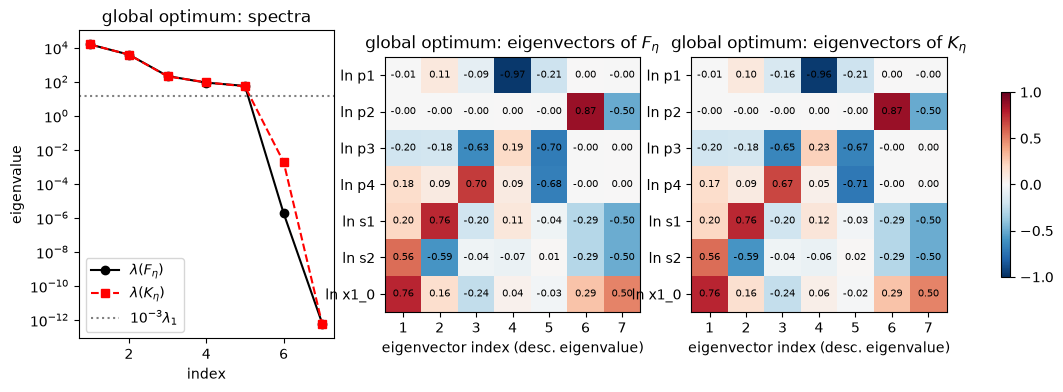

saved identifiability_matrices.npz


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for row, (M, R, lab) in enumerate([(M_A, R_A, 'global optimum')]):
    a = ax[0]
    a.semilogy(np.arange(1, 8), np.maximum(R['lamF'], 1e-16), 'ko-', label='$\\lambda(F_\\eta)$')
    a.semilogy(np.arange(1, 8), np.maximum(R['lamK'], 1e-16), 'rs--', label='$\\lambda(K_\\eta)$')
    a.axhline(1e-3 * R['lamF'][0], ls=':', color='gray', label='$10^{-3}\\lambda_1$')
    a.set_xlabel('index'); a.set_ylabel('eigenvalue'); a.set_title(f'{lab}: spectra'); a.legend()
    for col, (Vm, name) in enumerate([(R['UF'], '$F_\\eta$'), (R['UK'], '$K_\\eta$')]):
        a = ax[col + 1]
        im = a.imshow(Vm, cmap='RdBu_r', vmin=-1, vmax=1)
        a.set_xticks(range(7)); a.set_xticklabels([f'{i+1}' for i in range(7)])
        a.set_yticks(range(7)); a.set_yticklabels(ETA_NAMES)
        a.set_xlabel('eigenvector index (desc. eigenvalue)'); a.set_title(f'{lab}: eigenvectors of {name}')
        for i in range(7):
            for j in range(7): a.text(j, i, f'{Vm[i,j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=ax.ravel().tolist(), shrink=0.6)
plt.show()

np.savez('identifiability_matrices.npz',
         theta=best, J_eta=M_A['J_eta'], H_eta=M_A['H_eta'], F_eta=M_A['F_eta'], K_eta=M_A['K_eta'], C_eta=M_A['C_eta'], r_star=M_A['r_star'],
         eta_names=np.array(ETA_NAMES), row_labels=np.array(M_A['labels']))
print('saved identifiability_matrices.npz')

### 8.2b 特征向量变化的一阶摄动检验

令 $F_\eta=U_\eta\Lambda_\eta U_\eta^\top$，$E_\eta:=U_\eta^\top C_\eta U_\eta$，则 $K_\eta=U_\eta(\Lambda_\eta+E_\eta)U_\eta^\top$。在小扰动、特征值单重且分离时

$$\Delta u_i\approx\sum_{j\ne i}\frac{(E_\eta)_{ji}}{\lambda_i(F_\eta)-\lambda_j(F_\eta)}\,u_j,$$

因此特征向量"改变很小"对应于 $\dfrac{|(E_\eta)_{ji}|}{|\lambda_i(F_\eta)-\lambda_j(F_\eta)|}\ll1$：真正起作用的不是 $\|C_\eta\|$ 本身，而是缩放后的耦合与谱间隙之比。下面计算 $E_\eta$、该比值矩阵、一阶预测 $\|\Delta u_i\|$，并与 $K_\eta$ 实际特征向量（按最大重叠配对、符号对齐）的变化 $\|v_i-u_i\|$ 和夹角 $\sin\angle(u_i,v_i)$ 对比。

 i     lam_i(F) lam(K) matched    min gap  max_j ratio  |du| pred  |du| actual  sin(angle)
 1    1.573e+04      1.573e+04   1.17e+04     0.000257   0.000342     0.000342    0.000342
 2         3990           3989   3.77e+03      0.00184    0.00238      0.00238     0.00238
 3        218.6          208.6        129       0.0518     0.0701       0.0763      0.0763
 4        90.04          94.04       32.4       0.0518     0.0521       0.0584      0.0584
 5        57.68          54.04       32.4       0.0472     0.0475       0.0497      0.0497
 6    1.881e-06       0.001924   1.88e-06     0.000283   0.000302     0.000109    0.000109
 7    6.037e-13      5.421e-13   1.88e-06     0.000283   0.000283     2.77e-07    2.77e-07

E_eta = U^T C_eta U (F 的特征基下的残差修正):
[[ -1.245   0.335  -3.989   0.345   3.499  -0.002   0.   ]
 [  0.335  -1.163   2.108   7.18   -5.522  -0.001   0.   ]
 [ -3.989   2.108 -10.77    6.661   7.596   0.001  -0.   ]
 [  0.345   7.18    6.661   4.403   0.175  -0.      0.   ]

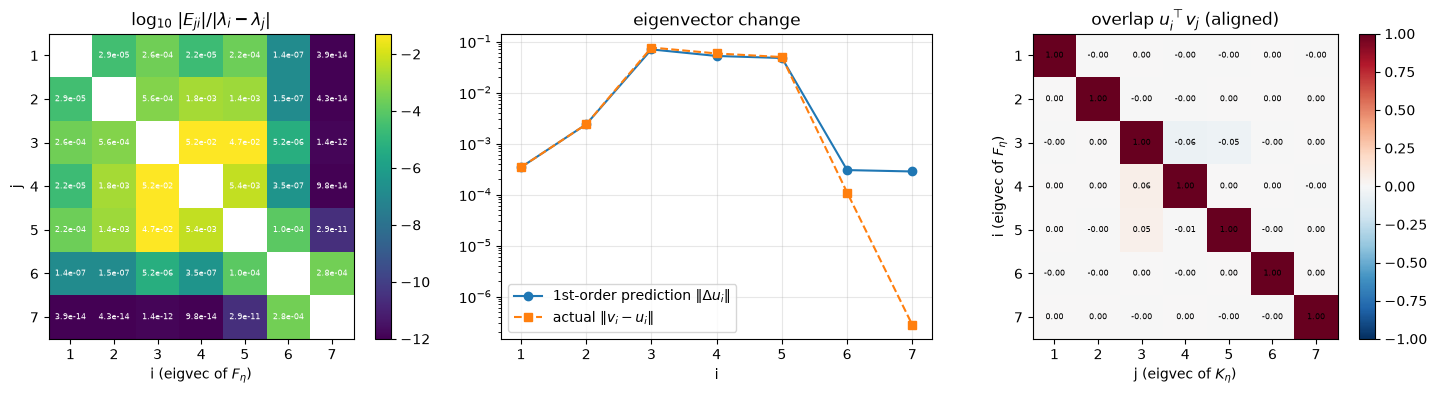

In [17]:
# 特征向量变化的一阶摄动检验:  K = U (Lam + E) U^T,  E = U^T C U
lamF, UF = R_A['lamF'], R_A['UF']; lamK, UK = R_A['lamK'], R_A['UK']
E = UF.T @ M_A['C_eta'] @ UF
k = len(lamF)
gap = lamF[:, None] - lamF[None, :]                       # gap[j, i] = lambda_j - lambda_i
with np.errstate(divide='ignore', invalid='ignore'):
    ratio = np.abs(E) / np.abs(gap.T)                     # ratio[j, i] = |E_ji| / |lambda_i - lambda_j|
np.fill_diagonal(ratio, np.nan)

# 一阶预测 Delta u_i = sum_{j != i} E_ji / (lambda_i - lambda_j) u_j
dU_pred = np.zeros((k, k))
for i in range(k):
    for j in range(k):
        if j != i: dU_pred[:, i] += E[j, i] / (lamF[i] - lamF[j]) * UF[:, j]

# 实际变化: 把 K 的特征向量按最大 |u_i . v_j| 与 F 的配对并对齐符号
match = [int(np.argmax(np.abs(UF[:, i] @ UK))) for i in range(k)]
UK_al = np.column_stack([UK[:, match[i]] * np.sign(UF[:, i] @ UK[:, match[i]]) for i in range(k)])
dU_act = UK_al - UF

print(f"{'i':>2s} {'lam_i(F)':>12s} {'lam(K) matched':>14s} {'min gap':>10s} {'max_j ratio':>12s} {'|du| pred':>10s} {'|du| actual':>12s} {'sin(angle)':>11s}")
for i in range(k):
    g = np.abs(lamF[i] - np.delete(lamF, i)).min()
    ang = np.sqrt(max(0.0, 1 - (UF[:, i] @ UK_al[:, i])**2))
    print(f"{i+1:2d} {lamF[i]:12.4g} {lamK[match[i]]:14.4g} {g:10.3g} {np.nanmax(ratio[:, i]):12.3g} {np.linalg.norm(dU_pred[:, i]):10.3g} {np.linalg.norm(dU_act[:, i]):12.3g} {ang:11.3g}")
print('\nE_eta = U^T C_eta U (F 的特征基下的残差修正):'); print(np.array2string(E, precision=3, suppress_small=True))
print('\n|E_ji| / |lambda_i - lambda_j|  (行 j, 列 i; 远小于 1 => u_i 几乎不变):'); print(np.array2string(ratio, formatter={'float_kind': lambda x: 'nan' if np.isnan(x) else f'{x:.2e}'}))
print('\n配对 (F 的 u_i -> K 的 v_j):', [(i+1, m+1) for i, m in enumerate(match)])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
im0 = ax[0].imshow(np.log10(np.where(np.isnan(ratio), np.nan, np.maximum(ratio, 1e-12))), cmap='viridis')
ax[0].set_title('$\\log_{10}\\,|E_{ji}|/|\\lambda_i-\\lambda_j|$'); ax[0].set_xlabel('i (eigvec of $F_\\eta$)'); ax[0].set_ylabel('j'); plt.colorbar(im0, ax=ax[0])
ax[0].set_xticks(range(k)); ax[0].set_xticklabels(range(1, k+1)); ax[0].set_yticks(range(k)); ax[0].set_yticklabels(range(1, k+1))
for i in range(k):
    for j in range(k):
        if i != j: ax[0].text(i, j, f'{ratio[j,i]:.1e}', ha='center', va='center', fontsize=6, color='w')
ax[1].semilogy(range(1, k+1), np.linalg.norm(dU_pred, axis=0), 'o-', label='1st-order prediction $\\|\\Delta u_i\\|$')
ax[1].semilogy(range(1, k+1), np.linalg.norm(dU_act, axis=0), 's--', label='actual $\\|v_i - u_i\\|$')
ax[1].set_xlabel('i'); ax[1].set_title('eigenvector change'); ax[1].legend(); ax[1].grid(alpha=.3)
im2 = ax[2].imshow(UF.T @ UK_al, cmap='RdBu_r', vmin=-1, vmax=1); ax[2].set_title('overlap $u_i^\\top v_j$ (aligned)')
ax[2].set_xlabel('j (eigvec of $K_\\eta$)'); ax[2].set_ylabel('i (eigvec of $F_\\eta$)'); plt.colorbar(im2, ax=ax[2])
ax[2].set_xticks(range(k)); ax[2].set_xticklabels(range(1, k+1)); ax[2].set_yticks(range(k)); ax[2].set_yticklabels(range(1, k+1))
for i in range(k):
    for j in range(k): ax[2].text(j, i, f'{(UF.T @ UK_al)[i,j]:.2f}', ha='center', va='center', fontsize=6)
plt.tight_layout(); plt.show()

### 8.3 坐标实际可识别性指标（Coordinate practical identifiability，在全局最优处）

对每个坐标 $p$，把 $\eta=(\tilde\eta,\eta_p)$ 分块（manuscript Eqs. 1.54–1.61）：$\tilde J$ 为 $J_\eta$ 删去第 $p$ 列，$j_p$ 为该列；
$\tilde K_\eta=E K_\eta E^\top$，$k_{\eta,p}=EK_\eta e_p$，$K_{\eta,pp}=e_p^\top K_\eta e_p$。

| 指标 | 定义 | 出处 |
|---|---|---|
| Gauss–Newton 坐标曲率 | $\kappa^F_p=F_{pp}-f_p^\top\tilde F^\dagger f_p=\|g^F_p\|_2^2$，$g^F_p=(I-\tilde J\tilde J^\dagger)j_p$ | Eqs. 1.72–1.73 |
| 残差修正坐标曲率 | $\kappa^K_p=K_{\eta,pp}-k_{\eta,p}^\top\tilde K_\eta^\dagger k_{\eta,p}$ | Eq. 1.64 |
| 有效数据响应向量 | $g^K_p=j_p-\tilde J\tilde K_\eta^\dagger k_{\eta,p}$ | Eq. 1.64 |
| 坐标 Lipschitz 系数 | $L^F_p=1/\sqrt{\kappa^F_p}$，$L^K_p=\|g^K_p\|_2/\kappa^K_p$ | Eqs. 1.67, 1.71 |
| 可识别判据 | $\kappa^K_p>0\iff e_p^\top z=0\ \forall z\in\ker K_\eta$ | Eq. 1.68 |
| 残差修正比 | $R^{RH}_p=L^K_p/L^F_p=R^{RH}_{p,\rm resp}\,R^{RH}_{p,\rm curv}$，$R_{\rm resp}=\|g^K_p\|/\|g^F_p\|=\sqrt{1+\|\tilde J d_p\|^2/\kappa^F_p}$，$R_{\rm curv}=\kappa^F_p/\kappa^K_p$ | Eqs. 1.74–1.75 |
| 对数分解 | $I^{RH}_p=I_{\rm resp}+I_{\rm curv}$，$I_{\rm resp}=\log R_{\rm resp}\ge0$，$I_{\rm curv}=-\log(\kappa^K_p/\kappa^F_p)$ | Eqs. 1.76–1.78 |
| 二次模型后验标准差 | $\mathrm{sd}_{\rm quad}(\eta_p)=\sigma/\sqrt{\kappa^K_p}$（标准化后 $\sigma=1$），$=\sigma\sqrt{(K_\eta^\dagger)_{pp}}$ | Eqs. 1.100–1.105 |
| 可信区间 | $\eta^*_p\pm z_{1-\alpha/2}\,\sigma/\sqrt{\kappa^K_p}$，$\theta$ 尺度取指数 | Eqs. 1.103–1.104 |

$R^{RH}_p<1$ 表示保留残差 Hessian 后该坐标对数据扰动的最坏放大减小。Algorithm 1 中的 metrics $K_0,K_1$ 在 manuscript 中引用了未定义的公式（Eq. ??），此处未实现。

In [18]:
from scipy.stats import norm

def pinv_sym(M, rtol=1e-12):
    # 对称矩阵的 Moore-Penrose 伪逆及零空间正交基 (相对阈值 rtol)
    w, V = np.linalg.eigh((M + M.T) / 2); big = np.abs(w) > rtol * np.abs(w).max()
    return (V[:, big] / w[big]) @ V[:, big].T, V[:, ~big]

def coordinate_metrics(J, K, names, sigma=1.0, rtol=1e-12, alpha=0.05):
    k = J.shape[1]; F = J.T @ J
    lamK = np.linalg.eigvalsh((K + K.T) / 2)
    _, ZK = pinv_sym(K, rtol)                       # ker(K_eta) 正交基
    zq = norm.ppf(1 - alpha / 2); rows = []
    for p in range(k):
        nu = [i for i in range(k) if i != p]
        Jt, jp = J[:, nu], J[:, p]
        # Gauss-Newton 分块 (Eqs. 1.72-1.73)
        Ft, fp, Fpp = Jt.T @ Jt, Jt.T @ jp, jp @ jp
        zF = np.linalg.lstsq(Jt, jp, rcond=None)[0]; gF = jp - Jt @ zF; kF = gF @ gF     # = F~^+ f_p (最小范数解), 用最小二乘避免 F~ 的平方条件数
        # 残差修正分块 (Eqs. 1.59-1.61, 1.64)
        Kt, kp, Kpp = K[np.ix_(nu, nu)], K[nu, p], K[p, p]
        Kt_pinv, NKt = pinv_sym(Kt, rtol); zK = Kt_pinv @ kp
        kK = Kpp - kp @ zK; gK = jp - Jt @ zK
        compat = (np.linalg.norm(Jt @ NKt) <= 1e-6 * max(1, np.linalg.norm(Jt))) if NKt.shape[1] else True  # ker(K~) ⊆ ker(J~)
        ep_null = np.abs(ZK[p, :]).max() if ZK.shape[1] else 0.0                                             # Eq. 1.68
        ident_F = kF > 1e-10 * Fpp; ident_K = (kK > 1e-10 * max(Kpp, 1e-300)) and ep_null < 1e-6
        LF = 1 / np.sqrt(kF) if ident_F else np.inf
        LK = np.linalg.norm(gK) / kK if ident_K else np.inf
        dp = zK - zF; Jd2 = (Jt @ dp) @ (Jt @ dp)
        both = ident_F and ident_K
        R_resp = np.sqrt(1 + Jd2 / kF) if ident_F else np.nan
        R_curv = kF / kK if both else np.nan
        sdK = sigma / np.sqrt(kK) if ident_K else np.inf
        rows.append(dict(name=names[p], kappa_F=kF, kappa_K=kK, gF=np.linalg.norm(gF), gK=np.linalg.norm(gK),
                         L_F=LF, L_K=LK, R_RH=LK / LF if both else np.nan, R_resp=R_resp, R_curv=R_curv,
                         I_resp=np.log(R_resp) if ident_F else np.nan, I_curv=-np.log(kK / kF) if both else np.nan,
                         Jd2=Jd2, compat=compat, ep_null=ep_null, ident_F=ident_F, ident_K=ident_K,
                         sd_ln=sdK, sd_log10=sdK / np.log(10), z=zq))
    return rows, lamK, ZK

def print_metrics(rows, lamK, ZK, theta, names, title):
    print('=' * 100); print(title)
    print(f'K_eta ⪰ 0: {lamK.min() > -1e-8 * lamK.max()}  (lambda_min = {lamK.min():.3g});  dim ker(K_eta) = {ZK.shape[1]}')
    if ZK.shape[1]:
        for j in range(ZK.shape[1]): print('  ker(K_eta) 基向量:', ' '.join(f'{names[i]}:{ZK[i,j]:+.3f}' for i in range(len(names)) if abs(ZK[i,j]) > 1e-6))
    print(f"\n{'coord':8s} {'kappa_F':>10s} {'kappa_K':>10s} {'|g_F|':>8s} {'|g_K|':>8s} {'L_F':>8s} {'L_K':>8s} {'R_RH':>7s} {'R_resp':>7s} {'R_curv':>7s} {'I_resp':>7s} {'I_curv':>7s}  identifiable(F/K)  e_p^T z")
    for R in rows:
        print(f"{R['name']:8s} {R['kappa_F']:10.4g} {R['kappa_K']:10.4g} {R['gF']:8.3g} {R['gK']:8.3g} {R['L_F']:8.3g} {R['L_K']:8.3g} "
              f"{R['R_RH']:7.3f} {R['R_resp']:7.3f} {R['R_curv']:7.3f} {R['I_resp']:7.3f} {R['I_curv']:7.3f}  {str(R['ident_F']):5s}/{str(R['ident_K']):5s}      {R['ep_null']:.2g}")
    print(f"\n二次模型后验不确定性 (sigma = 1, 残差已标准化) 与 95% 可信区间:")
    print(f"{'coord':8s} {'theta*':>10s} {'sd(ln)':>8s} {'sd(log10)':>9s} {'CrI_log10 (lo, hi)':>22s} {'CrI_theta (lo, hi)':>26s}")
    for R, th in zip(rows, theta):
        if np.isfinite(R['sd_ln']):
            lo, hi = np.log10(th) - R['z'] * R['sd_log10'], np.log10(th) + R['z'] * R['sd_log10']
            print(f"{R['name']:8s} {th:10.4g} {R['sd_ln']:8.3g} {R['sd_log10']:9.3g}   ({lo:+.3f}, {hi:+.3f})        ({10**lo:.4g}, {10**hi:.4g})")
        else:
            print(f"{R['name']:8s} {th:10.4g} {'inf':>8s} {'inf':>9s}   {'unbounded (non-identifiable)':>22s}")

rows7, lamK7, ZK7 = coordinate_metrics(M_A['J_eta'], M_A['K_eta'], ETA_NAMES)
print_metrics(rows7, lamK7, ZK7, best, ETA_NAMES, '全局最优, 全部 7 个坐标')

# 交叉检验: kappa_K^p = 1/(K_eta^+)_pp, kappa_F^p = 1/(F_eta^+)_pp  (Eq. 1.102; 对零空间方向不成立)
Kp = pinv_sym(M_A['K_eta'])[0]; Fp = pinv_sym(M_A['F_eta'])[0]
print('\n检验 (仅可识别坐标): 1/(K^+)_pp =', np.round([1 / Kp[i, i] for i in [0, 2, 3]], 4), ' vs kappa_K =', np.round([rows7[i]['kappa_K'] for i in [0, 2, 3]], 4))
print('                       1/(F^+)_pp =', np.round([1 / Fp[i, i] for i in [0, 2, 3]], 4), ' vs kappa_F =', np.round([rows7[i]['kappa_F'] for i in [0, 2, 3]], 4))

全局最优, 全部 7 个坐标
K_eta ⪰ 0: True  (lambda_min = 5.42e-13);  dim ker(K_eta) = 1
  ker(K_eta) 基向量: ln p2:-0.500 ln s1:-0.500 ln s2:-0.500 ln x1_0:+0.500

coord       kappa_F    kappa_K    |g_F|    |g_K|      L_F      L_K    R_RH  R_resp  R_curv  I_resp  I_curv  identifiable(F/K)  e_p^T z
ln p1         79.44      93.34     8.91     9.47    0.112    0.101   0.904   1.062   0.851   0.061  -0.161  True /True       2.3e-14
ln p2     1.234e-26  4.884e-12 1.11e-13 8.91e-12      inf      inf     nan     nan     nan     nan     nan  False/False      0.5
ln p3         27.27      91.62     5.22     9.63    0.191    0.105   0.549   1.844   0.298   0.612  -1.212  True /True       3.1e-14
ln p4         37.83      86.13     6.15     9.83    0.163    0.114   0.702   1.599   0.439   0.469  -0.823  True /True       2.5e-14
ln s1     1.322e-26  2.728e-12 1.15e-13 8.97e-13      inf      inf     nan     nan     nan     nan     nan  False/False      0.5
ln s2      1.13e-26  2.728e-12 1.06e-13 5.58e-13      inf 

### 8.4 可视化：坐标曲率、Lipschitz 系数与残差修正分解

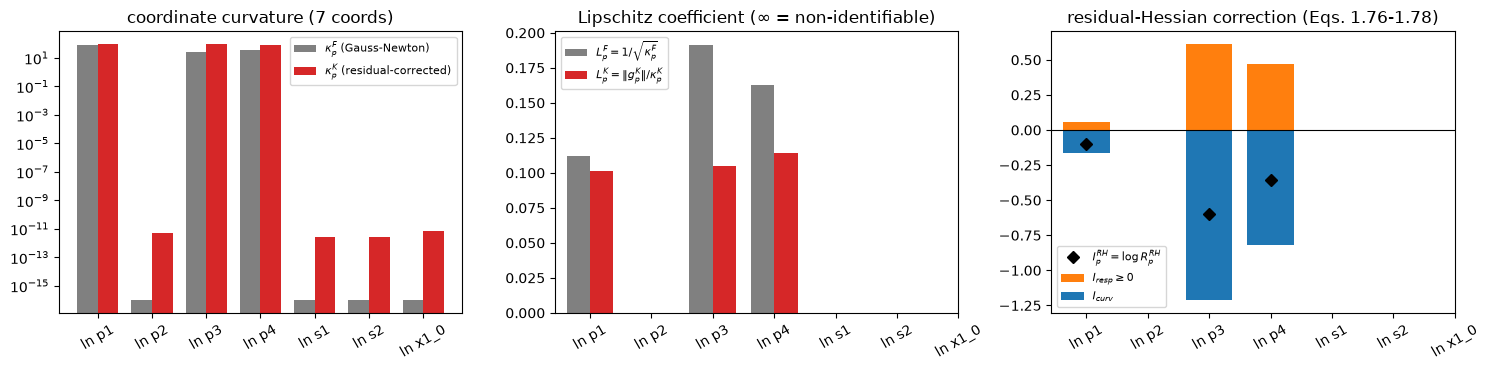

saved coordinate_identifiability.npz


In [19]:
def bar_metrics(rows, title_suffix):
    nm = [R['name'] for R in rows]; xk = np.arange(len(rows)); w = 0.38
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    kF = np.array([max(R['kappa_F'], 1e-16) for R in rows]); kK = np.array([max(R['kappa_K'], 1e-16) for R in rows])
    ax[0].bar(xk - w/2, kF, w, label='$\\kappa^F_p$ (Gauss-Newton)', color='gray'); ax[0].bar(xk + w/2, kK, w, label='$\\kappa^K_p$ (residual-corrected)', color='tab:red')
    ax[0].set_yscale('log'); ax[0].set_title('coordinate curvature ' + title_suffix); ax[0].legend(fontsize=8)
    LF = np.array([R['L_F'] if np.isfinite(R['L_F']) else np.nan for R in rows]); LK = np.array([R['L_K'] if np.isfinite(R['L_K']) else np.nan for R in rows])
    ax[1].bar(xk - w/2, LF, w, label='$L^F_p=1/\\sqrt{\\kappa^F_p}$', color='gray'); ax[1].bar(xk + w/2, LK, w, label='$L^K_p=\\|g^K_p\\|/\\kappa^K_p$', color='tab:red')
    ax[1].set_title('Lipschitz coefficient (∞ = non-identifiable)'); ax[1].legend(fontsize=8)
    Ir = np.array([R['I_resp'] for R in rows]); Ic = np.array([R['I_curv'] for R in rows])
    ax[2].bar(xk, Ir, w * 2, label='$I_{resp}\\geq 0$', color='tab:orange'); ax[2].bar(xk, Ic, w * 2, label='$I_{curv}$', color='tab:blue')
    ax[2].plot(xk, Ir + Ic, 'kD', label='$I^{RH}_p=\\log R^{RH}_p$'); ax[2].axhline(0, color='k', lw=0.8)
    ax[2].set_title('residual-Hessian correction (Eqs. 1.76-1.78)'); ax[2].legend(fontsize=8)
    for a in ax: a.set_xticks(xk); a.set_xticklabels(nm, rotation=30)
    plt.tight_layout(); plt.show()

bar_metrics(rows7, '(7 coords)')

np.savez('coordinate_identifiability.npz',
         names7=np.array(ETA_NAMES), kappa_F7=np.array([R['kappa_F'] for R in rows7]), kappa_K7=np.array([R['kappa_K'] for R in rows7]),
         L_F7=np.array([R['L_F'] for R in rows7]), L_K7=np.array([R['L_K'] for R in rows7]), R_RH7=np.array([R['R_RH'] for R in rows7]),
         sd_ln7=np.array([R['sd_ln'] for R in rows7]), ker_K7=ZK7)
print('saved coordinate_identifiability.npz')

### 8.4b 可识别组合的 Hao–Wang 坐标指标：$p_2x_1(0)$、$s_1x_1(0)$、$s_2x_1(0)$

Hao–Wang 的坐标指标对任意线性坐标都成立。取组合坐标
$$q=\ln\big(p_1,\ p_2x_1(0),\ p_3,\ p_4,\ s_1x_1(0),\ s_2x_1(0)\big),$$
在固定规范 $x_1(0)$ 下 $\eta$ 是 $q$ 的仿射函数 $\eta=Bq+c$，因此 $J_q=J_\eta B$、$H_q=B^\top H_\eta B$（仿射变换不产生额外的二阶项），即取 $J_\eta$、$H_\eta$ 的前 6 列/行。由于 $J_\eta$ 的各列满足 $\mathrm{col}(x_1(0))=\mathrm{col}(p_2)+\mathrm{col}(s_1)+\mathrm{col}(s_2)$（精确对称），结果与规范选取无关（下面数值检验）。

在 6 维组合空间中没有精确零空间，$K_q$ 应为正定，三个组合各自得到有限的 $\kappa^F,\kappa^K,L^F,L^K$ 与二次模型可信区间；并与第 7 节 profile likelihood 的逐点 1-σ 区间对照。

规范无关性检验: max |col(x1_0) - col(p2) - col(s1) - col(s2)| of J_eta = 7.11e-14
eigenvalues F_q: [   0.       57.5357   89.5035  185.3519 3570.1771 6969.4243]
eigenvalues K_q: [   0.0014   53.9999   93.0271  177.5009 3568.9229 6966.5196]
组合坐标 q (6 个可识别参数)
K_eta ⪰ 0: True  (lambda_min = 0.00144);  dim ker(K_eta) = 0

coord       kappa_F    kappa_K    |g_F|    |g_K|      L_F      L_K    R_RH  R_resp  R_curv  I_resp  I_curv  identifiable(F/K)  e_p^T z
ln p1         79.44      93.34     8.91     9.47    0.112    0.101   0.904   1.062   0.851   0.061  -0.161  True /True       0
ln(p2*x1_0)  1.411e-06   0.001443  0.00119  0.00139      842    0.965   0.001   1.172   0.001   0.159  -6.930  True /True       0
ln p3         27.27      91.62     5.22     9.63    0.191    0.105   0.549   1.844   0.298   0.612  -1.212  True /True       0
ln p4         37.83      86.13     6.15     9.83    0.163    0.114   0.702   1.599   0.439   0.469  -0.823  True /True       0
ln(s1*x1_0)      367.7      640.4     19.

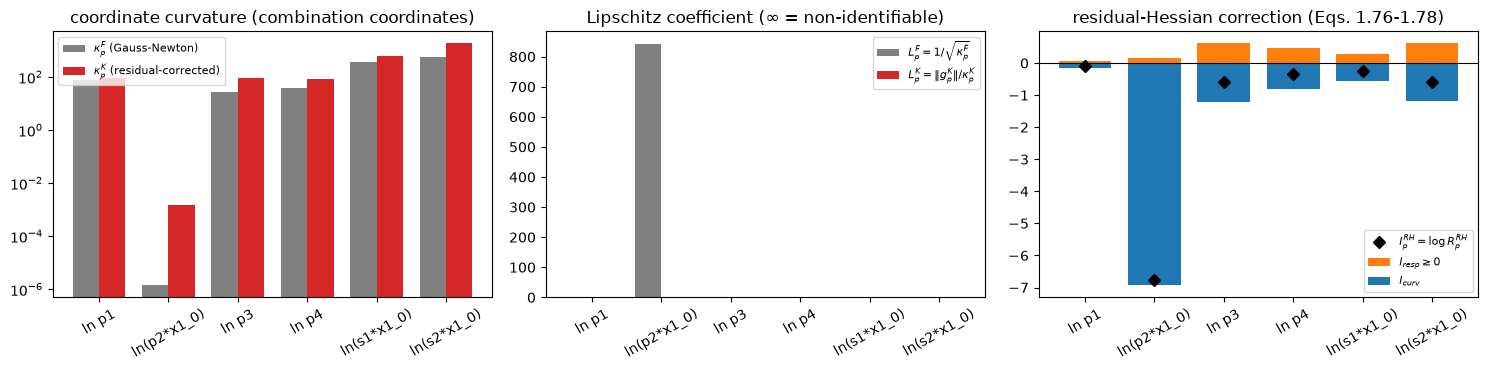

saved coordinate_identifiability_combo.npz


In [20]:
# 组合坐标 q = ln(p1, p2*x1_0, p3, p4, s1*x1_0, s2*x1_0):  J_q = J_eta[:, :6],  H_q = H_eta[:, :6, :6]
QN_LN = ['ln p1', 'ln(p2*x1_0)', 'ln p3', 'ln p4', 'ln(s1*x1_0)', 'ln(s2*x1_0)']
J_q = M_A['J_eta'][:, :6]; H_q = M_A['H_eta'][:, :6, :6]
F_q = J_q.T @ J_q; C_q = np.einsum('n,nij->ij', M_A['r_star'], H_q); K_q = F_q + C_q
print('规范无关性检验: max |col(x1_0) - col(p2) - col(s1) - col(s2)| of J_eta =',
      f"{np.abs(M_A['J_eta'][:, 6] - M_A['J_eta'][:, 1] - M_A['J_eta'][:, 4] - M_A['J_eta'][:, 5]).max():.2e}")
print('eigenvalues F_q:', np.array2string(np.linalg.eigvalsh(F_q), precision=4))
print('eigenvalues K_q:', np.array2string(np.linalg.eigvalsh(K_q), precision=4))

rows_q, lamK_q, ZK_q = coordinate_metrics(J_q, K_q, QN_LN)
print_metrics(rows_q, lamK_q, ZK_q, 10 ** best_q, QN_LN, '组合坐标 q (6 个可识别参数)')

# 与第 7 节 profile likelihood 的逐点 1-sigma 区间对照 (二次模型: fit ± sd, log10)
print('\n二次模型 1-sigma 区间 (fit ± sd_log10) vs profile likelihood 逐点 1-sigma 区间 (log10):')
print(f"{'coord':14s} {'fit':>7s} {'quad lo':>9s} {'quad hi':>9s} {'PL lo':>9s} {'PL hi':>9s}")
_pl_map = {'ln p1': ('p1', pl_summary), 'ln p3': ('p3', pl_summary), 'ln p4': ('p4', pl_summary),
           'ln(p2*x1_0)': ('p2*x1_0', pl_summary_c), 'ln(s1*x1_0)': ('s1*x1_0', pl_summary_c), 'ln(s2*x1_0)': ('s2*x1_0', pl_summary_c)}
for R, qv in zip(rows_q, best_q):
    key, summ = _pl_map[R['name']]; lo, hi = summ[key]['ci_pw']
    f = lambda v: f'{v:+9.3f}' if v is not None and np.isfinite(v) else '      —  '
    print(f"{R['name']:14s} {qv:+7.3f} {f(qv - R['sd_log10'])} {f(qv + R['sd_log10'])} {f(lo)} {f(hi)}")

bar_metrics(rows_q, '(combination coordinates)')
np.savez('coordinate_identifiability_combo.npz', names=np.array(QN_LN, dtype=object), log10_fit=best_q,
         kappa_F=np.array([R['kappa_F'] for R in rows_q]), kappa_K=np.array([R['kappa_K'] for R in rows_q]),
         L_F=np.array([R['L_F'] for R in rows_q]), L_K=np.array([R['L_K'] for R in rows_q]), R_RH=np.array([R['R_RH'] for R in rows_q]),
         sd_ln=np.array([R['sd_ln'] for R in rows_q]), F_q=F_q, C_q=C_q, K_q=K_q)
print('saved coordinate_identifiability_combo.npz')

### 8.5 与 Yao orthogonal method、Quaiser & Mönnigmann eigenvalue method 的比较

两种方法都基于全局最优处的灵敏度矩阵。为公平比较，两者使用同一矩阵 $Z=J_\eta\in\mathbb R^{31\times7}$（行按 $\sigma$ 标准化、列为对数/相对灵敏度，即 Quaiser 的 $S$ 与 $H=S^\top S=F_\eta$）。

**Yao et al. (2003) orthogonal method**（Yao 2003; Lund & Foss 2008 的 QRCP 形式）
- 列归一化 $\bar s_i=s_i/\|s_i\|$；第 $L{+}1$ 步选取对已选列张成空间正交残差最大的列：$i=\arg\max_i\|(I-P_L)\bar s_i\|_2$，等价于列主元 QR 的 $|R_{L+1,L+1}|$。
- 排序 = QRCP 列置换；当 $\max_i\|r_i^{(L)}\|<\varepsilon$（归一化时常用 $\varepsilon=0.04$）停止，已选列对应可估计参数，其余固定。

**Quaiser & Mönnigmann (2009) eigenvalue method**
- $H=S^\top S$（Gauss 近似 Hessian，正半定），最小特征值 $\lambda_1$、特征向量 $u_1$。
- 若 $\lambda_1<\epsilon$：选 $k=\arg\max_k|u_{1,k}|$，把 $p_k$ 固定（移入不可识别集 $U$），对剩余参数重算 $H$；重复直到 $\lambda_1\ge\epsilon$。剔除顺序 = 从最不可识别到最可识别的排序。
- 若 $|u_{1,l}|$ 接近 $|u_{1,k}|$，则 $p_l$ 与 $p_k$ **co-dominant**（选择有歧义）。
- 论文的 method comparison：对任一排序，依次固定最不可识别的参数并重算 $\lambda_{\min}$，直到 $\lambda_{\min}\ge\epsilon$；需固定的参数越少方法越好。

阈值：Quaiser 对未缩放矩阵用 $\epsilon=10^{-4}$；本处矩阵已缩放，取相对阈值 $\epsilon=10^{-3}\lambda_{\max}(F_\eta)$（Hao & Wang Fig. 1 使用的比例），并同时给出 $\lambda_{\min}$ 随固定个数的完整路径以便换用其他阈值。

In [21]:
def yao_method(Z, names, eps=0.04, normalize=True, eta=1e-2):
    # Yao orthogonalization = 增量 QRCP (MGS + 范数降更新 + 重正交化 + 抵消误差重算)
    Zb = Z / np.linalg.norm(Z, axis=0) if normalize else Z.copy()
    p = Zb.shape[1]; c = np.sum(Zb**2, axis=0); c0 = c.copy()
    Q = np.zeros((Zb.shape[0], 0)); order, Rll = [], []
    raw = np.linalg.norm(Z, axis=0); remaining = list(range(p))
    while remaining:
        # 选正交残差最大的列; 列归一化后第一步所有残差都等于 1, 平局按原始列范数 (平方和最大者优先, 同 Quaiser 文中描述)
        cmax = max(c[k] for k in remaining); tied = [k for k in remaining if c[k] >= cmax * (1 - 1e-9)]
        i = max(tied, key=lambda k: raw[k]); order.append(i); Rll.append(np.sqrt(max(c[i], 0.0)))
        w = Zb[:, i] - Q @ (Q.T @ Zb[:, i]); w = w - Q @ (Q.T @ w)
        if np.linalg.norm(w) > 1e-14 * np.linalg.norm(Zb[:, i]): Q = np.column_stack([Q, w / np.linalg.norm(w)])
        remaining.remove(i)
        for k in remaining:
            c[k] -= (Q[:, -1] @ Zb[:, k])**2
            if c[k] / c0[k] < eta: c[k] = np.sum((Zb[:, k] - Q @ (Q.T @ Zb[:, k]))**2)
    Rll = np.array(Rll); n_est = int(np.sum(Rll >= eps))
    return dict(order=order, Rll=Rll, n_est=n_est, estimable=[names[i] for i in order[:n_est]], excluded=[names[i] for i in order[n_est:]])

def quaiser_method(Z, names, eps, codom=0.9):
    # Quaiser & Mönnigmann eigenvalue method (Algorithm steps 1-6)
    H = Z.T @ Z; I = list(range(Z.shape[1])); U = []; log = []
    while I:
        w, V = np.linalg.eigh(H[np.ix_(I, I)]); u = V[:, 0]; k = int(np.argmax(np.abs(u)))
        cod = [names[I[j]] for j in range(len(I)) if j != k and abs(u[j]) >= codom * abs(u[k])]
        log.append(dict(n_I=len(I), lam_min=w[0], removed=names[I[k]] if w[0] < eps else None,
                        u1={names[I[j]]: u[j] for j in range(len(I))}, codominant=cod))
        if w[0] >= eps: break
        U.append(I.pop(k))
    return dict(identifiable=[names[i] for i in I], unidentifiable=[names[i] for i in U], log=log)

def lam_min_path(Z, ranking_least_first):
    # Quaiser 的 method comparison: 依次固定最不可识别参数后 H 的最小特征值
    H = Z.T @ Z; I = list(range(Z.shape[1])); out = [np.linalg.eigvalsh(H).min()]
    for k in ranking_least_first[:-1]:
        I.remove(k); out.append(np.linalg.eigvalsh(H[np.ix_(I, I)]).min())
    return np.array(out)

Z = M_A['J_eta']
lam_max = np.linalg.eigvalsh(Z.T @ Z).max()
EPS_Q = 1e-3 * lam_max
print(f'lambda_max(F_eta) = {lam_max:.4g},  Quaiser 阈值 eps = 1e-3*lambda_max = {EPS_Q:.4g}\n')

# ---------- Yao ----------
yao = yao_method(Z, ETA_NAMES, eps=0.04, normalize=True)
print('Yao orthogonal method (列归一化, eps = 0.04)')
print(f"{'step':>4s} {'selected':10s} {'|R_LL| (residual norm)':>24s}")
for L, (i, r) in enumerate(zip(yao['order'], yao['Rll'])): print(f'{L+1:4d} {ETA_NAMES[i]:10s} {r:24.4g}')
print('  estimable :', yao['estimable']); print('  excluded  :', yao['excluded'])
yao_raw = yao_method(Z, ETA_NAMES, eps=0.04, normalize=False)
print('\nYao (不归一化, 仅排序):', [ETA_NAMES[i] for i in yao_raw['order']], ' |R_LL| =', np.round(yao_raw['Rll'], 4))

# ---------- Quaiser ----------
qm = quaiser_method(Z, ETA_NAMES, eps=EPS_Q)
print('\nQuaiser & Mönnigmann eigenvalue method')
for L in qm['log']:
    u_str = ', '.join(f'{k}:{v:+.3f}' for k, v in L['u1'].items())
    print(f"  n_I = {L['n_I']}: lambda_min = {L['lam_min']:.4g}  u1 = [{u_str}]")
    if L['removed']: print(f"     -> remove {L['removed']}" + (f"   (co-dominant: {L['codominant']})" if L['codominant'] else ''))
    else: print(f"     -> lambda_min >= eps, stop")
print('  identifiable  :', qm['identifiable']); print('  unidentifiable:', qm['unidentifiable'])

lambda_max(F_eta) = 1.573e+04,  Quaiser 阈值 eps = 1e-3*lambda_max = 15.73

Yao orthogonal method (列归一化, eps = 0.04)
step selected     |R_LL| (residual norm)
   1 ln x1_0                           1
   2 ln p1                             1
   3 ln s1                        0.6769
   4 ln p4                        0.4857
   5 ln p2                        0.3527
   6 ln p3                        0.1771
   7 ln s2                     1.362e-15
  estimable : ['ln x1_0', 'ln p1', 'ln s1', 'ln p4', 'ln p2', 'ln p3']
  excluded  : ['ln s2']

Yao (不归一化, 仅排序): ['ln x1_0', 'ln s1', 'ln p4', 'ln p3', 'ln p1', 'ln s2', 'ln p2']  |R_LL| = [96.0024 44.7346 12.4339  9.6574  9.4497  0.0012  0.    ]

Quaiser & Mönnigmann eigenvalue method
  n_I = 7: lambda_min = 6.037e-13  u1 = [ln p1:-0.000, ln p2:-0.500, ln p3:+0.000, ln p4:+0.000, ln s1:-0.500, ln s2:-0.500, ln x1_0:+0.500]
     -> remove ln p2   (co-dominant: ['ln s1', 'ln s2', 'ln x1_0'])
  n_I = 6: lambda_min = 4.703e-07  u1 = [ln p1:+0.000, ln p3:

**Method comparison（Quaiser 的统一准则）**：把三种排序（Yao 由可估计→不可估计倒序、Quaiser 剔除顺序、以及第 8.3 节按坐标 Lipschitz 系数 $L^K_p=\|g^K_p\|_2/\kappa^K_p$ 由大到小，$L^K_p=\infty$ 的坐标按其在 $\ker K_\eta$ 上的分量 $|e_p^\top z|$ 排序）各自从最不可识别参数开始依次固定，记录剩余 Hessian 的 $\lambda_{\min}$。

Hao-Wang L^K_p: {'ln p1': '0.101', 'ln p2': 'inf', 'ln p3': '0.105', 'ln p4': '0.114', 'ln s1': 'inf', 'ln s2': 'inf', 'ln x1_0': 'inf'}
阈值 eps = 15.73
Yao                ranking (least -> most identifiable): ['ln s2', 'ln p3', 'ln p2', 'ln p4', 'ln s1', 'ln p1', 'ln x1_0']
                   lambda_min path: [   0.       0.       0.      86.479   88.167  134.458 9216.462]   -> 需固定 3 个参数: ['ln s2', 'ln p3', 'ln p2']
Quaiser            ranking (least -> most identifiable): ['ln p2', 'ln x1_0', 'ln p3', 'ln p1', 'ln p4', 'ln s1', 'ln s2']
                   lambda_min path: [   0.       0.      57.536   86.733  137.623 2936.902 6280.635]   -> 需固定 2 个参数: ['ln p2', 'ln x1_0']
Hao-Wang L_K       ranking (least -> most identifiable): ['ln p2', 'ln s1', 'ln s2', 'ln x1_0', 'ln p4', 'ln p3', 'ln p1']
                   lambda_min path: [  0.      0.     57.333  59.557  59.848 130.584 134.46 ]   -> 需固定 2 个参数: ['ln p2', 'ln s1']


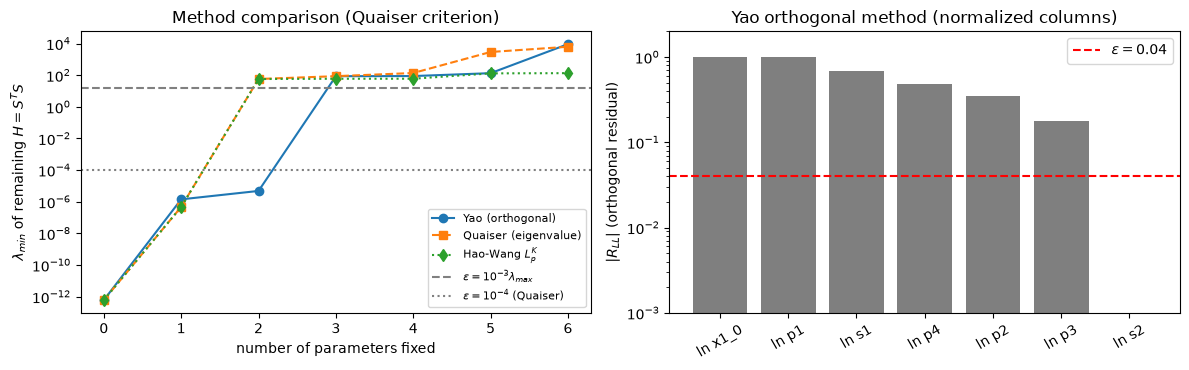

In [22]:
rank_yao = yao['order'][::-1]                                   # 最不可识别 -> 最可识别
rank_q = [ETA_NAMES.index(n) for n in qm['unidentifiable']] + [ETA_NAMES.index(n) for n in qm['identifiable']]
# Quaiser 剔除停止后, 剩余参数按 (最终 H 的) 最小特征向量分量继续排序以补全
if len(qm['identifiable']) > 1:
    Hs = Z[:, [ETA_NAMES.index(n) for n in qm['identifiable']]]; sub = [ETA_NAMES.index(n) for n in qm['identifiable']]
    rest = []
    while len(sub) > 1:
        w, V = np.linalg.eigh(Hs.T @ Hs); k = int(np.argmax(np.abs(V[:, 0]))); rest.append(sub.pop(k)); Hs = Z[:, sub]
    rank_q = [ETA_NAMES.index(n) for n in qm['unidentifiable']] + rest + sub
# Hao-Wang: 按坐标 Lipschitz 系数 L^K_p = ||g^K_p|| / kappa^K_p 降序 (最大 = 最不可识别; inf 表示 kappa_K = 0)
LK = np.array([R['L_K'] for R in rows7]); epz = np.array([R['ep_null'] for R in rows7]); kK = np.array([R['kappa_K'] for R in rows7])
rank_hw = sorted(range(7), key=lambda i: (0 if np.isinf(LK[i]) else 1, -float(epz[i]) if np.isinf(LK[i]) else -float(LK[i])))   # inf 组内按 |e_p^T z| 降序
print('Hao-Wang L^K_p:', {ETA_NAMES[i]: (f'{LK[i]:.3g}' if np.isfinite(LK[i]) else 'inf') for i in range(7)})

paths = {'Yao (orthogonal)': lam_min_path(Z, rank_yao), 'Quaiser (eigenvalue)': lam_min_path(Z, rank_q), 'Hao-Wang $L^K_p$': lam_min_path(Z, rank_hw)}
print(f'阈值 eps = {EPS_Q:.4g}')
for name, rk in [('Yao', rank_yao), ('Quaiser', rank_q), ('Hao-Wang L_K', rank_hw)]:
    pth = paths[[k for k in paths if k.startswith(name.split()[0])][0]]
    n_fix = int(np.argmax(pth >= EPS_Q)) if np.any(pth >= EPS_Q) else len(pth)
    print(f"{name:18s} ranking (least -> most identifiable): {[ETA_NAMES[i] for i in rk]}")
    print(f"{'':18s} lambda_min path: {np.array2string(pth, precision=3)}   -> 需固定 {n_fix} 个参数: {[ETA_NAMES[i] for i in rk[:n_fix]]}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for (name, pth), mk in zip(paths.items(), ['o-', 's--', 'd:']):
    ax[0].semilogy(np.arange(len(pth)), np.maximum(pth, 1e-16), mk, label=name)
ax[0].axhline(EPS_Q, color='gray', ls='--', label='$\\epsilon=10^{-3}\\lambda_{max}$'); ax[0].axhline(1e-4, color='gray', ls=':', label='$\\epsilon=10^{-4}$ (Quaiser)')
ax[0].set_xlabel('number of parameters fixed'); ax[0].set_ylabel('$\\lambda_{min}$ of remaining $H=S^TS$'); ax[0].set_title('Method comparison (Quaiser criterion)'); ax[0].legend(fontsize=8)
xk = np.arange(7)
ax[1].bar(xk, yao['Rll'], color='tab:gray'); ax[1].axhline(0.04, color='r', ls='--', label='$\\varepsilon=0.04$')
ax[1].set_xticks(xk); ax[1].set_xticklabels([ETA_NAMES[i] for i in yao['order']], rotation=30); ax[1].set_yscale('log'); ax[1].set_ylim(1e-3, 2)
ax[1].set_ylabel('$|R_{LL}|$ (orthogonal residual)'); ax[1].set_title('Yao orthogonal method (normalized columns)'); ax[1].legend()
plt.tight_layout(); plt.show()

**合图**：同一横轴（参数）上同时展示 Yao 与 Quaiser 的结果。上图为三种方法给出的排序位次（1 = 最不可识别）；下图左轴为 Yao 的正交残差 $|R_{LL}|$（柱），右轴为 Quaiser 剔除该参数时的 $\lambda_{\min}$（未被剔除者画最终 $\lambda_{\min}$），并标出两者阈值。

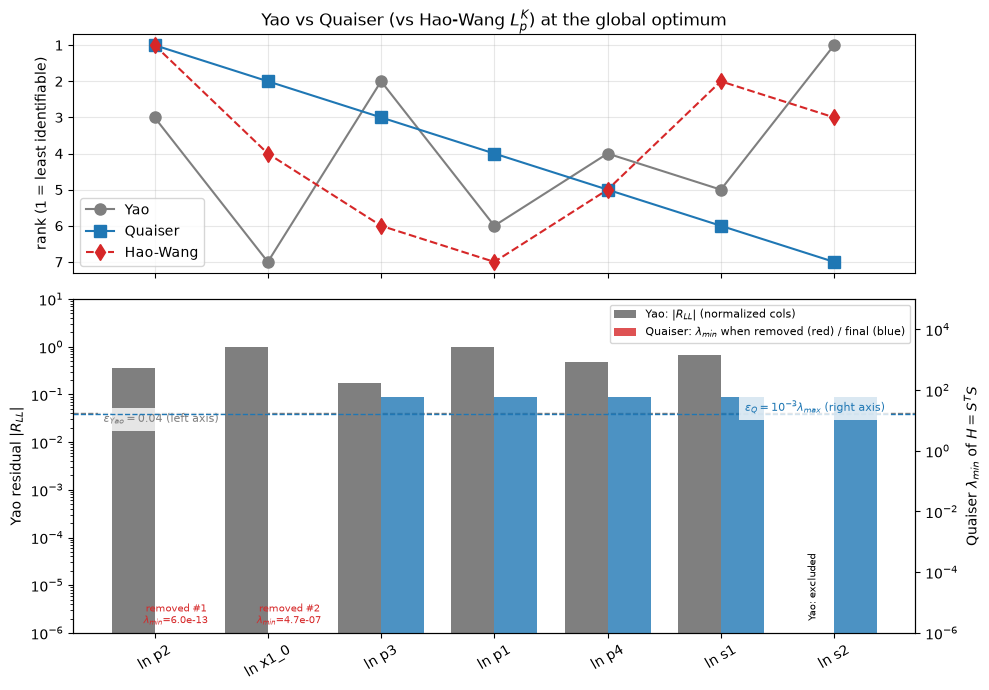

In [23]:
# 每个参数在各方法中的位次 (1 = 最不可识别)
pos = {m: {ETA_NAMES[i]: r + 1 for r, i in enumerate(rk)} for m, rk in [('Yao', rank_yao), ('Quaiser', rank_q), ('Hao-Wang', rank_hw)]}
# Quaiser: 剔除该参数时的 lambda_min; 未剔除者 = 最终 lambda_min
q_lam = {L['removed']: L['lam_min'] for L in qm['log'] if L['removed']}
lam_final = qm['log'][-1]['lam_min']
q_val = np.array([q_lam.get(n, lam_final) for n in ETA_NAMES]); q_removed = np.array([n in q_lam for n in ETA_NAMES])
yao_val = np.array([yao['Rll'][yao['order'].index(i)] for i in range(7)])

order_x = rank_q                                   # 横轴按 Quaiser 排序排列
xl = [ETA_NAMES[i] for i in order_x]; xk = np.arange(7)
fig, (a0, a1) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [1, 1.4]})
for m, mk, c in [('Yao', 'o-', 'tab:gray'), ('Quaiser', 's-', 'tab:blue'), ('Hao-Wang', 'd--', 'tab:red')]:
    a0.plot(xk, [pos[m][n] for n in xl], mk, color=c, label=m, ms=8)
a0.set_ylabel('rank (1 = least identifiable)'); a0.set_yticks(range(1, 8)); a0.invert_yaxis(); a0.grid(alpha=0.3); a0.legend(); a0.set_title('Yao vs Quaiser (vs Hao-Wang $L^K_p$) at the global optimum')

w = 0.38
a1.bar(xk - w/2, np.maximum(yao_val[order_x], 1e-6), w, color='tab:gray', label='Yao: $|R_{LL}|$ (normalized cols)')
a1.axhline(0.04, color='tab:gray', ls='--', lw=1); a1.text(-0.45, 0.04, '$\\varepsilon_{Yao}=0.04$ (left axis)', va='top', ha='left', fontsize=8, color='tab:gray', zorder=10, bbox=dict(fc='white', ec='none', alpha=0.8))
a1.set_yscale('log'); a1.set_ylabel('Yao residual $|R_{LL}|$'); a1.set_ylim(1e-6, 10)
a2 = a1.twinx()
cols = ['tab:red' if q_removed[i] else 'tab:blue' for i in order_x]
a2.bar(xk + w/2, np.maximum(q_val[order_x], 1e-6), w, color=cols, alpha=0.8, label='Quaiser: $\\lambda_{min}$ when removed (red) / final (blue)')
a2.axhline(EPS_Q, color='tab:blue', ls='--', lw=1); a2.text(6.45, EPS_Q, '$\\epsilon_{Q}=10^{-3}\\lambda_{max}$ (right axis)', va='bottom', ha='right', fontsize=8, color='tab:blue', zorder=10, bbox=dict(fc='white', ec='none', alpha=0.8))
a2.set_yscale('log'); a2.set_ylabel('Quaiser $\\lambda_{min}$ of $H=S^TS$'); a2.set_ylim(1e-6, 1e5)
for i, p in enumerate(order_x):
    if q_removed[p]: a2.text(i + w/2, max(q_val[p], 1e-6) * 2, f'removed #{qm["unidentifiable"].index(ETA_NAMES[p]) + 1}\n$\\lambda_{{min}}$={q_val[p]:.1e}', ha='center', fontsize=7, color='tab:red')
    if yao_val[p] < 0.04: a1.text(i - w/2, 2e-6, 'Yao: excluded', ha='center', fontsize=7, color='k', rotation=90)
h1, l1 = a1.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); a1.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper right')
a1.set_xticks(xk); a1.set_xticklabels(xl, rotation=30)
plt.tight_layout(); plt.show()

### 8.5b 组合坐标下的 Yao 与 Quaiser 方法

把三种方法换到组合坐标 $q=\ln(p_1,\ p_2x_1(0),\ p_3,\ p_4,\ s_1x_1(0),\ s_2x_1(0))$：灵敏度矩阵取 $Z_q=J_q=J_\eta B$（6 列），$H=Z_q^\top Z_q=F_q$。这里不再有精确零空间，三种方法的区别只体现在对弱方向 $p_2x_1(0)$ 的处理上。Quaiser 阈值仍取 $\epsilon=10^{-3}\lambda_{\max}$，Hao–Wang 排序按 8.4b 的 $L^K$。

Yao vs Quaiser vs Hao-Wang in combination coordinates $q$:  lambda_max(F) = 6969,  Quaiser eps = 6.969

Yao (列归一化, eps = 0.04): ln(s2*x1_0) (1) > ln(s1*x1_0) (1) > ln p1 (0.82) > ln p4 (0.486) > ln(p2*x1_0) (0.353) > ln p3 (0.177)
  estimable: ['ln(s2*x1_0)', 'ln(s1*x1_0)', 'ln p1', 'ln p4', 'ln(p2*x1_0)', 'ln p3']  excluded: []

Quaiser:
  n_I = 6: lambda_min = 1.411e-06  u1 = [ln p1:-0.000, ln(p2*x1_0):-1.000, ln p3:+0.000, ln p4:+0.000, ln(s1*x1_0):-0.000, ln(s2*x1_0):-0.000]  -> remove ln(p2*x1_0)
  n_I = 5: lambda_min = 57.54  u1 = [ln p1:-0.202, ln p3:-0.706, ln p4:-0.674, ln(s1*x1_0):-0.074, ln(s2*x1_0):-0.015]  -> stop
  identifiable: ['ln p1', 'ln p3', 'ln p4', 'ln(s1*x1_0)', 'ln(s2*x1_0)']  unidentifiable: ['ln(p2*x1_0)']

Hao-Wang L^K: {'ln p1': '0.101', 'ln(p2*x1_0)': '0.965', 'ln p3': '0.105', 'ln p4': '0.114', 'ln(s1*x1_0)': '0.0402', 'ln(s2*x1_0)': '0.0236'}
Yao            ranking (least -> most): ['ln p3', 'ln(p2*x1_0)', 'ln p4', 'ln p1', 'ln(s1*x1_0)', 'ln(s2*x1_0)']
 

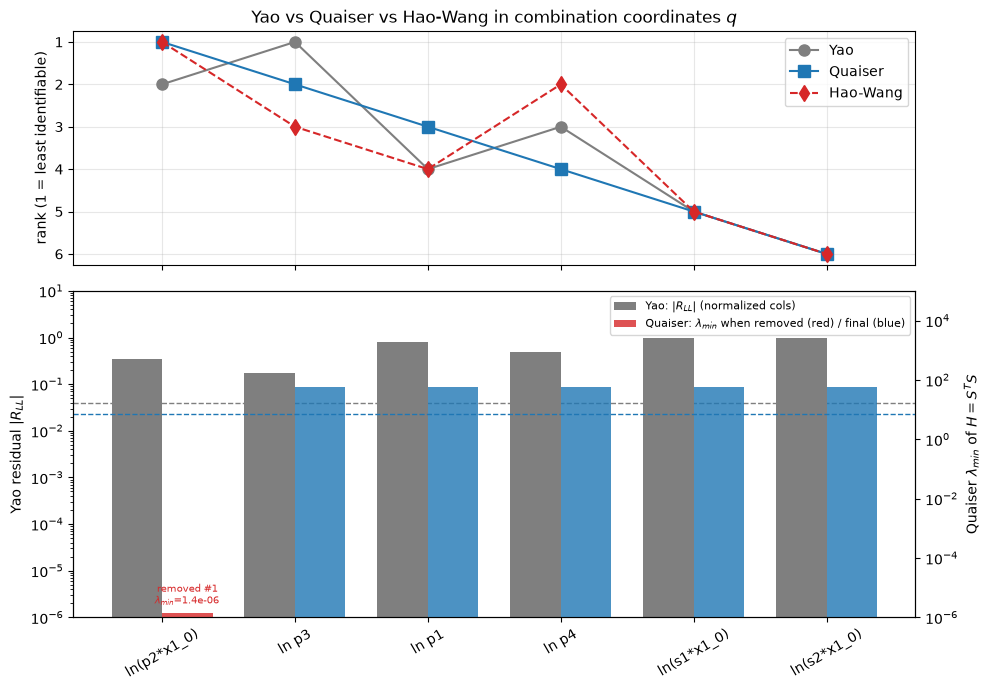

In [24]:
def run_methods(Z, names, rows, label, eps_rel=1e-3):
    # 对给定灵敏度矩阵 Z (n x k) 运行 Yao / Quaiser / Hao-Wang(L^K) 三种排序, 计算 lambda_min 路径并画合图
    k = Z.shape[1]; eps = eps_rel * np.linalg.eigvalsh(Z.T @ Z).max()
    print('=' * 100); print(f'{label}:  lambda_max(F) = {eps / eps_rel:.4g},  Quaiser eps = {eps:.4g}')
    ya = yao_method(Z, names, eps=0.04, normalize=True)
    print('\nYao (列归一化, eps = 0.04):', ' > '.join(f'{names[i]} ({r:.3g})' for i, r in zip(ya['order'], ya['Rll'])))
    print('  estimable:', ya['estimable'], ' excluded:', ya['excluded'])
    qa = quaiser_method(Z, names, eps=eps)
    print('\nQuaiser:')
    for L in qa['log']:
        print(f"  n_I = {L['n_I']}: lambda_min = {L['lam_min']:.4g}  u1 = [" + ', '.join(f'{a}:{v:+.3f}' for a, v in L['u1'].items()) + ']'
              + (f"  -> remove {L['removed']}" + (f" (co-dominant: {L['codominant']})" if L['codominant'] else '') if L['removed'] else '  -> stop'))
    print('  identifiable:', qa['identifiable'], ' unidentifiable:', qa['unidentifiable'])
    r_yao = ya['order'][::-1]
    sub = [names.index(n) for n in qa['identifiable']]; rest = []
    while len(sub) > 1:
        w_, V_ = np.linalg.eigh(Z[:, sub].T @ Z[:, sub]); j = int(np.argmax(np.abs(V_[:, 0]))); rest.append(sub.pop(j))
    r_qua = [names.index(n) for n in qa['unidentifiable']] + rest + sub
    LKv = np.array([R['L_K'] for R in rows]); epz_ = np.array([R['ep_null'] for R in rows])
    r_hw = sorted(range(k), key=lambda i: (0 if np.isinf(LKv[i]) else 1, -float(epz_[i]) if np.isinf(LKv[i]) else -float(LKv[i])))
    print('\nHao-Wang L^K:', {names[i]: (f'{LKv[i]:.3g}' if np.isfinite(LKv[i]) else 'inf') for i in range(k)})
    pth = {'Yao (orthogonal)': lam_min_path(Z, r_yao), 'Quaiser (eigenvalue)': lam_min_path(Z, r_qua), 'Hao-Wang $L^K_p$': lam_min_path(Z, r_hw)}
    nfix = {}
    for (nm, rk), key in zip([('Yao', r_yao), ('Quaiser', r_qua), ('Hao-Wang L_K', r_hw)], pth):
        pt = pth[key]; nfix[nm] = int(np.argmax(pt >= eps)) if np.any(pt >= eps) else len(pt)
        print(f"{nm:14s} ranking (least -> most): {[names[i] for i in rk]}\n{'':14s} lambda_min path: {np.array2string(pt, precision=3)}  -> 需固定 {nfix[nm]} 个: {[names[i] for i in rk[:nfix[nm]]]}")
    # 合图
    pos = {m: {names[i]: r + 1 for r, i in enumerate(rk)} for m, rk in [('Yao', r_yao), ('Quaiser', r_qua), ('Hao-Wang', r_hw)]}
    q_lam = {L['removed']: L['lam_min'] for L in qa['log'] if L['removed']}; lam_final = qa['log'][-1]['lam_min']
    q_val = np.array([q_lam.get(n, lam_final) for n in names]); q_rem = np.array([n in q_lam for n in names])
    yao_val = np.array([ya['Rll'][ya['order'].index(i)] for i in range(k)])
    ox = r_qua; xl = [names[i] for i in ox]; xk = np.arange(k); w = 0.38
    fig, (a0, a1) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [1, 1.4]})
    for m, mk, c in [('Yao', 'o-', 'tab:gray'), ('Quaiser', 's-', 'tab:blue'), ('Hao-Wang', 'd--', 'tab:red')]:
        a0.plot(xk, [pos[m][n] for n in xl], mk, color=c, label=m, ms=8)
    a0.set_ylabel('rank (1 = least identifiable)'); a0.set_yticks(range(1, k + 1)); a0.invert_yaxis(); a0.grid(alpha=0.3); a0.legend(); a0.set_title(label)
    a1.bar(xk - w/2, np.maximum(yao_val[ox], 1e-6), w, color='tab:gray', label='Yao: $|R_{LL}|$ (normalized cols)')
    a1.axhline(0.04, color='tab:gray', ls='--', lw=1); a1.set_yscale('log'); a1.set_ylabel('Yao residual $|R_{LL}|$'); a1.set_ylim(1e-6, 10)
    a2 = a1.twinx()
    a2.bar(xk + w/2, np.maximum(q_val[ox], 1e-6), w, color=['tab:red' if q_rem[i] else 'tab:blue' for i in ox], alpha=0.8, label='Quaiser: $\\lambda_{min}$ when removed (red) / final (blue)')
    a2.axhline(eps, color='tab:blue', ls='--', lw=1); a2.set_yscale('log'); a2.set_ylabel('Quaiser $\\lambda_{min}$ of $H=S^TS$'); a2.set_ylim(1e-6, 1e5)
    for i, pp in enumerate(ox):
        if q_rem[pp]: a2.text(i + w/2, max(q_val[pp], 1e-6) * 2, f'removed #{qa["unidentifiable"].index(names[pp]) + 1}\n$\\lambda_{{min}}$={q_val[pp]:.1e}', ha='center', fontsize=7, color='tab:red')
        if yao_val[pp] < 0.04: a1.text(i - w/2, 2e-6, 'Yao: excluded', ha='center', fontsize=7, color='k', rotation=90)
    h1, l1 = a1.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); a1.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper right')
    a1.set_xticks(xk); a1.set_xticklabels(xl, rotation=30); plt.tight_layout(); plt.show()
    return dict(yao=ya, quaiser=qa, eps=eps, rank_yao=r_yao, rank_quaiser=r_qua, rank_haowang=r_hw, paths=pth, n_fix=nfix)

res_q = run_methods(J_q, QN_LN, rows_q, 'Yao vs Quaiser vs Hao-Wang in combination coordinates $q$')

### 8.6 将第 8 节全部结果保存为 MATLAB `.mat`

In [25]:
# 把第 8 节 (8.1-8.5) 的全部结果保存为 MATLAB .mat
# 第 8.2c 节已删除时, 在此直接计算 theta 坐标下的 F, C, K 以及两种坐标下的特征向量摄动检验,
# 使 identifiability_analysis.mat 的字段仍与 identifiability.m 兼容 (若 8.2c 存在则直接使用其结果)
def _eig_pert(F, C):
    lamF, UF = eig_desc(F); lamK, UK = eig_desc(F + C); k = len(lamF)
    E = UF.T @ C @ UF
    gap = lamF[:, None] - lamF[None, :]
    with np.errstate(divide='ignore', invalid='ignore'): ratio = np.abs(E) / np.abs(gap.T)
    np.fill_diagonal(ratio, np.nan)
    dU_pred = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            if j != i: dU_pred[:, i] += E[j, i] / (lamF[i] - lamF[j]) * UF[:, j]
    match = [int(np.argmax(np.abs(UF[:, i] @ UK))) for i in range(k)]
    UK_al = np.column_stack([UK[:, match[i]] * np.sign(UF[:, i] @ UK[:, match[i]]) for i in range(k)])
    sin_ang = np.sqrt(np.maximum(0.0, 1 - np.sum(UF * UK_al, axis=0)**2))
    return dict(lamF=lamF, UF=UF, lamK=lamK, UK=UK, UK_al=UK_al, E=E, ratio=ratio, dU_pred=dU_pred, dU_act=UK_al - UF, sin_ang=sin_ang, match=match)
if 'chk_eta' not in globals() or 'chk_theta' not in globals():
    F_theta = M_A['J_theta'].T @ M_A['J_theta']; C_theta = np.einsum('n,nij->ij', M_A['r_star'], M_A['H_theta']); K_theta = F_theta + C_theta
    chk_eta = _eig_pert(M_A['F_eta'], M_A['C_eta']); chk_theta = _eig_pert(F_theta, C_theta)

from scipy.io import savemat
def to_mat(x):
    # 递归转换: None -> NaN, bool -> double, list of str -> cell, dict -> struct
    if x is None: return np.nan
    if isinstance(x, (bool, np.bool_)): return float(x)
    if isinstance(x, str): return x
    if isinstance(x, dict): return {str(k).replace(' ', '_'): to_mat(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        if all(isinstance(e, str) for e in x): return np.array(x, dtype=object)
        if all(isinstance(e, (int, float, np.integer, np.floating, type(None))) for e in x): return np.array([np.nan if e is None else float(e) for e in x])
        return np.array([to_mat(e) for e in x], dtype=object)
    if isinstance(x, np.ndarray) and x.dtype == object: return np.array([to_mat(e) for e in x], dtype=object)
    return x

out = dict(
    theta_fit=best, eta_fit=np.log(best), param_names=np.array(PNAMES, dtype=object), eta_names=np.array(ETA_NAMES, dtype=object),
    # 8.1 矩阵 (行顺序: 按观测时刻, 每时刻先 pSTAT 后 tSTAT; 已按 sigma 标准化)
    J_eta=M_A['J_eta'], H_eta=M_A['H_eta'], F_eta=M_A['F_eta'], C_eta=M_A['C_eta'], K_eta=M_A['K_eta'], r_star=M_A['r_star'],
    J_theta=M_A['J_theta'], H_theta=M_A['H_theta'], row_time=np.array([l[0] for l in M_A['labels']]), row_observable=np.array([l[1] + 1 for l in M_A['labels']]),
    # 8.1 特征分解与 Theorem 2 量
    theorem2=to_mat({k: v for k, v in R_A.items()}),
    # 8.2b / 8.2c 特征向量摄动检验
    eig_perturbation_eta=to_mat(chk_eta), eig_perturbation_theta=to_mat(chk_theta),
    F_theta=F_theta, C_theta=C_theta, K_theta=K_theta,
    # 8.3 坐标可识别性指标 (结构体数组, 每个坐标一项)
    coordinate_metrics=to_mat({R['name'].replace('ln ', ''): R for R in rows7}),
    # 8.4b 组合坐标 q = ln(p1, p2*x1_0, p3, p4, s1*x1_0, s2*x1_0)
    combo_names=np.array(['p1', 'p2x1_0', 'p3', 'p4', 's1x1_0', 's2x1_0'], dtype=object), log10_combo_fit=best_q, J_q=J_q, H_q=H_q, F_q=F_q, C_q=C_q, K_q=K_q,
    yao_combo=to_mat(dict(order_1based=np.array(res_q['yao']['order']) + 1, ranking_names=[QN_LN[i] for i in res_q['yao']['order']], Rll=res_q['yao']['Rll'], eps=0.04,
                          n_estimable=res_q['yao']['n_est'], estimable=res_q['yao']['estimable'], excluded=res_q['yao']['excluded'])),
    quaiser_combo=to_mat(dict(eps=res_q['eps'], identifiable=res_q['quaiser']['identifiable'], unidentifiable=res_q['quaiser']['unidentifiable'],
                              steps=[dict(n_I=L['n_I'], lam_min=L['lam_min'], removed=L['removed'] if L['removed'] else '', u1=L['u1'], codominant=L['codominant'] if L['codominant'] else []) for L in res_q['quaiser']['log']])),
    comparison_combo=to_mat(dict(rank_yao_least_first=[QN_LN[i] for i in res_q['rank_yao']], rank_quaiser_least_first=[QN_LN[i] for i in res_q['rank_quaiser']], rank_haowang_LK_least_first=[QN_LN[i] for i in res_q['rank_haowang']],
                                 lam_min_path_yao=res_q['paths']['Yao (orthogonal)'], lam_min_path_quaiser=res_q['paths']['Quaiser (eigenvalue)'], lam_min_path_haowang=res_q['paths']['Hao-Wang $L^K_p$'],
                                 n_fix_yao=res_q['n_fix']['Yao'], n_fix_quaiser=res_q['n_fix']['Quaiser'], n_fix_haowang=res_q['n_fix']['Hao-Wang L_K'], eps=res_q['eps'])),
    coordinate_metrics_combo=to_mat({n: R for n, R in zip(['p1', 'p2x1_0', 'p3', 'p4', 's1x1_0', 's2x1_0'], rows_q)}),
    # 8.5 Yao / Quaiser / 比较
    yao=to_mat(dict(order_1based=np.array(yao['order']) + 1, ranking_names=[ETA_NAMES[i] for i in yao['order']], Rll=yao['Rll'], eps=0.04, n_estimable=yao['n_est'], estimable=yao['estimable'], excluded=yao['excluded'],
                    unnormalized_order_1based=np.array(yao_raw['order']) + 1, unnormalized_Rll=yao_raw['Rll'])),
    quaiser=to_mat(dict(eps=EPS_Q, identifiable=qm['identifiable'], unidentifiable=qm['unidentifiable'],
                        steps=[dict(n_I=L['n_I'], lam_min=L['lam_min'], removed=L['removed'] if L['removed'] else '', u1=L['u1'], codominant=L['codominant'] if L['codominant'] else []) for L in qm['log']])),
    comparison=to_mat(dict(rank_yao_least_first=[ETA_NAMES[i] for i in rank_yao], rank_quaiser_least_first=[ETA_NAMES[i] for i in rank_q], rank_haowang_LK_least_first=[ETA_NAMES[i] for i in rank_hw],
                           lam_min_path_yao=paths['Yao (orthogonal)'], lam_min_path_quaiser=paths['Quaiser (eigenvalue)'], lam_min_path_haowang=paths['Hao-Wang $L^K_p$'], eps=EPS_Q)),
)
savemat('identifiability_analysis.mat', out, long_field_names=True, do_compression=True)
print('saved identifiability_analysis.mat with fields:', list(out.keys()))

saved identifiability_analysis.mat with fields: ['theta_fit', 'eta_fit', 'param_names', 'eta_names', 'J_eta', 'H_eta', 'F_eta', 'C_eta', 'K_eta', 'r_star', 'J_theta', 'H_theta', 'row_time', 'row_observable', 'theorem2', 'eig_perturbation_eta', 'eig_perturbation_theta', 'F_theta', 'C_theta', 'K_theta', 'coordinate_metrics', 'combo_names', 'log10_combo_fit', 'J_q', 'H_q', 'F_q', 'C_q', 'K_q', 'yao_combo', 'quaiser_combo', 'comparison_combo', 'coordinate_metrics_combo', 'yao', 'quaiser', 'comparison']


## 9. Regime diagnostic：残差与扰动大小决定稳定性的阶

**问题**：在拟合点 $\eta^*$ 附近，有些参数方向在一阶下"看不见"（位于 $J_\eta$ 的零空间）。二阶效应能否把这些方向确定下来？确定的速度有多快？

**核心思想**：沿零空间单位方向 $\xi$ 移动 $t$，模型输出的一阶变化为零，只剩二阶变化 $\tfrac12 t^2 H[\xi,\xi]$。代入受扰数据 $\hat h-\delta$ 的损失，只保留与 $t$ 有关的项：

$$
l(t)\approx \tfrac12\big(\gamma\nu-\underbrace{\approx\varepsilon\,c_2}_{\text{扰动项}}\big)\,t^2+\tfrac18\,c_2^2\,t^4 .
$$

- $\nu=\|r^*\|$；$\gamma\nu=\lambda_{\min}(V^\top C V)$，其中 $C=\sum_a r_a\nabla^2 h_a$，$V$ 为零空间基。$\gamma\nu$ 表示残差让这个方向产生的弯曲，为正时损失在该方向上是二次的。
- $c_2=\min_\xi\|\Pi_\perp H[\xi,\xi]\|$：二阶输出变化中**其他参数无法补偿的法向分量**，决定四次项；$M_N$ 为对应的最大值。
- $\varepsilon=\|\delta\|_2$：数据扰动大小，最多能抵消约 $\varepsilon c_2$ 的二次曲率。

两者之比给出无量纲指标 $\Xi=\dfrac{\gamma\nu}{c_2\,\varepsilon}$，交叉尺度 $\varepsilon_{\rm cross}=\gamma\nu/c_2$：

| 情况 | 谁主导 | 参数偏移 | 稳定性 |
|---|---|---|---|
| $\Xi\gg1$（扰动小） | 残差曲率 $\gamma\nu$ | $\propto\varepsilon$ | Lipschitz |
| $\Xi\ll1$（扰动大） | 扰动抵消曲率，四次项接管 | $\propto\sqrt{\varepsilon}$ | Hölder-1/2 |

由于 $J,H,r$ 已按 $\sigma$ 标准化，$\varepsilon$ 以噪声标准差为单位；一次完整噪声实现的典型范数约为 $\sqrt n$（$n=31$ 时约 5.6）。

**注意**：函数内部的 flag 只做相对比较。若零空间是精确对称方向（$\gamma$、$c_2$ 都只是舍入误差），flag 会误报"不是局部极小"。因此 9.2 另外把 $|\gamma\nu|$、$c_2$ 与 $\|C\|_2$、$\max_a\|H_a\|_2$ 的绝对尺度比较。

In [26]:
"""Regime diagnostic for Theorem (residual and perturbation size decide the
order of stability).  Inputs are quantities already computed in the
framework at the fitted parameter eta* (log coordinates):

    J   : (n, k)      Jacobian of the stacked outputs, n = N*L
    Hs  : (n, k, k)   Hessian of each stacked output h_a w.r.t. eta
    r   : (n,)        residual r* = h(t, eta*) - h_hat
    eps : float/array perturbation size(s) ||delta||_2 of interest
    tau : relative singular-value threshold defining the (effective) null space

Returns gamma, c2, M_N, the dimensionless regime indicator
    Xi = gamma * nu / (c2 * eps)      (Xi >> 1: Lipschitz, Xi << 1: Hoelder-1/2)
and auxiliary quantities.
"""
import numpy as np
from scipy.optimize import minimize


def crossover_diagnostic(J, Hs, r, eps, tau=1e-6, n_starts=200, seed=0):
    J, Hs, r = np.asarray(J, float), np.asarray(Hs, float), np.asarray(r, float)
    n, k = J.shape
    Uj, s, Vt = np.linalg.svd(J, full_matrices=False)
    rank = int(np.sum(s > tau * s.max()))
    V = Vt[rank:].T                          # (effective) null space of F = J^T J
    m = V.shape[1]
    if m == 0:
        return dict(null_dim=0, note="F has full rank: Theorem 2 / Corollary 1 apply directly")
    Pperp = np.eye(n) - Uj[:, :rank] @ Uj[:, :rank].T
    nu = np.linalg.norm(r)
    sigma_plus = s[rank - 1] if rank > 0 else np.nan

    C = np.einsum('a,aij->ij', r, Hs)        # residual correction C = sum_a r_a Hess(h_a)
    D = V.T @ C @ V                          # null block; lambda_min(D) = gamma * nu
    lam_D = np.linalg.eigvalsh(D)
    gamma = lam_D[0] / nu if nu > 0 else np.nan

    def normal_acc(w):                       # ||Pi_perp H[xi, xi]|| for xi = V w / |w|
        w = w / np.linalg.norm(w)
        xi = V @ w
        return np.linalg.norm(Pperp @ np.einsum('aij,i,j->a', Hs, xi, xi))

    rng = np.random.default_rng(seed)
    W = rng.normal(size=(n_starts, m))
    vals = np.array([normal_acc(w) for w in W])
    best_min = min((minimize(normal_acc, W[i], method='Nelder-Mead').fun
                    for i in np.argsort(vals)[:10]), default=vals.min())
    best_max = max((-minimize(lambda w: -normal_acc(w), W[i], method='Nelder-Mead').fun
                    for i in np.argsort(-vals)[:10]), default=vals.max())
    c2, M_N = min(best_min, vals.min()), max(best_max, vals.max())

    K = J.T @ J + C
    eps = np.atleast_1d(np.asarray(eps, float))
    Xi = gamma * nu / (c2 * eps) if (nu > 0 and c2 > 0) else np.full_like(eps, np.nan)
    regime = np.where(Xi > 3, 'Lipschitz', np.where(Xi < 1 / 3, 'Hoelder-1/2', 'crossover'))
    flags = []
    if nu > 0 and gamma < -1e-10 * abs(lam_D).max():
        flags.append("gamma < 0: eta* is not a local minimum (refit before analysis)")
    if c2 < 1e-10 * max(M_N, 1e-300):
        flags.append("c2 ~ 0: null direction invisible at second order (structural, no rate)")
    if nu > 0 and abs(gamma) <= 1e-10 * abs(lam_D).max():
        flags.append("gamma ~ 0: residual does not curve a null direction (outside scope)")
    return dict(null_dim=m, rank=rank, sigma_plus=sigma_plus, nu=nu, gamma=gamma,
                gamma_hat=gamma / c2 if c2 > 0 else np.nan, c2=c2, M_N=M_N,
                lam_min_K=np.linalg.eigvalsh(K)[0], eps=eps, Xi=Xi,
                eps_cross=gamma * nu / c2 if c2 > 0 else np.nan,
                regime=regime, flags=flags)

### 9.2 JAK-STAT 模型（全局最优处）

第一步要决定哪些方向算"零空间"，用相对奇异值阈值 $\tau$ 控制。$J_\eta$ 的奇异值约为 125、63、15、9.5、7.6、**0.0014**、**≈0**（舍入误差量级）。

- **$\tau=10^{-6}$**：只取最后一个精确为零的方向，即 $(p_2,s_1,s_2,x_1(0))$ 的组合，也就是 Raue 2009 的结构不可识别流形（Eq. 11）。沿这个方向移动时模型输出在**任何阶**都完全不变，所以 $\gamma$ 与 $c_2$ 都只是 $10^{-14}$ 量级的舍入误差，$\Xi$ 没有意义：这个方向是结构不可识别，不存在任何速率。
- **$\tau=10^{-3}$**：把奇异值 0.0014（相对最大奇异值约 $10^{-5}$）的弱方向（主要是 $\ln p_2$）也算进零空间。但函数在零空间里取最小值，最小值又落到精确对称方向（值为 0）上，弱方向被掩盖，结果仍然没有意义。

因此需要 9.3：先去掉精确对称方向，再单独看弱方向。

In [27]:
# 在全局最优 eta* 处 (log 坐标) 应用于 JAK-STAT 模型。J, H, r 已按 sigma 标准化, 故 ||delta|| 以噪声标准差为单位。
J_p, H_p, r_p = M_A['J_eta'], M_A['H_eta'], M_A['r_star']
eps_grid = np.array([1e-3, 1e-2, 1e-1, 1.0, np.sqrt(len(r_p))])        # sqrt(n): 一次完整噪声实现的典型范数
eps_lab = ['1e-3', '1e-2', '1e-1', '1', 'sqrt(n)=noise level']
s_J = np.linalg.svd(J_p, compute_uv=False)
print('singular values of J_eta:', np.array2string(s_J, precision=4), '  ratios s_i/s_max:', np.array2string(s_J / s_J[0], precision=2))
H_scale = max(np.linalg.norm(H_p[a], 2) for a in range(len(r_p)))     # 绝对尺度, 用于判断 gamma, c2 是否只是舍入误差
C_scale = np.linalg.norm(np.einsum('a,aij->ij', r_p, H_p), 2)

crossover_results = {}
for tau, label in [(1e-6, 'exact null space (structural: p2, s1, s2, x1_0)'), (1e-3, 'effective null space (adds weak ln p2 direction)')]:
    out = crossover_diagnostic(J_p, H_p, r_p, eps=eps_grid, tau=tau)
    crossover_results[tau] = out
    print('=' * 100); print(f'tau = {tau:g}: {label}')
    if out['null_dim'] == 0: print(out['note']); continue
    print(f"rank(J) = {out['rank']}, null_dim = {out['null_dim']}, sigma_+ = {out['sigma_plus']:.3e}, nu = ||r*|| = {out['nu']:.4f}")
    print(f"gamma = {out['gamma']:.4e}, c2 = {out['c2']:.4e}, M_N = {out['M_N']:.4e}, gamma_hat = {out['gamma_hat']:.4e}")
    print(f"lambda_min(K) = {out['lam_min_K']:.4e}, eps_cross = gamma*nu/c2 = {out['eps_cross']:.4e}")
    # 与绝对尺度比较 (函数内部的 flag 只做相对比较; 当 gamma, c2 都是舍入误差时会误判)
    print(f"scale check: |gamma*nu| / ||C||_2 = {abs(out['gamma'] * out['nu']) / C_scale:.2e},  c2 / max_a ||H_a||_2 = {out['c2'] / H_scale:.2e}"
          + ("   -> both at round-off level: exact symmetry, invisible at every order (no rate; Xi meaningless)"
             if abs(out['gamma'] * out['nu']) / C_scale < 1e-8 and out['c2'] / H_scale < 1e-8 else ''))
    for e, el, xi, rg in zip(out['eps'], eps_lab, out['Xi'], out['regime']):
        print(f"   eps = {e:9.3e} ({el:20s})  Xi = {xi:11.4e}  -> {rg}")
    print('flags from function:', out['flags'] if out['flags'] else 'none')
    _, _, Vt_ = np.linalg.svd(J_p, full_matrices=False)
    for j in range(out['rank'], Vt_.shape[0]):
        print('   null direction:', ', '.join(f'{ETA_NAMES[i]}:{Vt_[j, i]:+.3f}' for i in range(len(ETA_NAMES)) if abs(Vt_[j, i]) > 1e-2))

singular values of J_eta: [125.4291  63.1642  14.7843   9.4888   7.5945   0.0014   0.    ]   ratios s_i/s_max: [1.   0.5  0.12 0.08 0.06 0.   0.  ]
tau = 1e-06: exact null space (structural: p2, s1, s2, x1_0)
rank(J) = 6, null_dim = 1, sigma_+ = 1.371e-03, nu = ||r*|| = 7.5765
gamma = 2.3626e-15, c2 = 2.5977e-14, M_N = 2.5977e-14, gamma_hat = 9.0949e-02
lambda_min(K) = 1.6499e-13, eps_cross = gamma*nu/c2 = 6.8908e-01
scale check: |gamma*nu| / ||C||_2 = 9.42e-16,  c2 / max_a ||H_a||_2 = 5.09e-16   -> both at round-off level: exact symmetry, invisible at every order (no rate; Xi meaningless)
   eps = 1.000e-03 (1e-3                )  Xi =  6.8908e+02  -> Lipschitz
   eps = 1.000e-02 (1e-2                )  Xi =  6.8908e+01  -> Lipschitz
   eps = 1.000e-01 (1e-1                )  Xi =  6.8908e+00  -> Lipschitz
   eps = 1.000e+00 (1                   )  Xi =  6.8908e-01  -> crossover
   eps = 5.568e+00 (sqrt(n)=noise level )  Xi =  1.2376e-01  -> Hoelder-1/2
flags from function: none
   nu

### 9.3 去掉精确对称方向后的弱方向

精确对称方向本来就无法从数据确定，属于结构问题。把 $J,H$ 投影到它的 6 维正交补 $Q$ 上（$J_q=JQ$，$H_q=Q^\top H Q$），相当于在结构流形上固定一个代表点。之后零空间里只剩弱的 $\ln p_2$ 方向（$\ln p_2:+0.87$，$s_1,s_2,x_1(0)$ 各约 $\mp0.29$），也就是可识别组合 $\ln(p_2x_1(0))$ 的方向，诊断才有意义。

**解读**（当前拟合点：$p_2x_1(0)=10^6$，正好是其拟合上界；重新拟合后数值会变化）：
- $\gamma\approx2.5\times10^{-4}>0$：残差让这个方向向上弯曲。$K_\eta$ 在该方向上的曲率约 $1.9\times10^{-3}$，其中 Fisher 部分只有 $1.9\times10^{-6}$，几乎全部来自残差项 $C_\eta$。
- **拟合点不是内点极小**：它停在 $p_2x_1(0)$ 的上界，沿该方向的梯度约 $-3.3\times10^{-3}$（$\chi^2$ 仍随 $p_2x_1(0)$ 增大而缓慢下降），局部二次模型的极小在边界外约 0.9 个数量级处。因此定理的内点极小假设只近似成立，下面的数值应理解为在这个边界点处的局部诊断。
- $c_2\approx7.9\times10^{-4}$，$\varepsilon_{\rm cross}=\gamma\nu/c_2\approx2.4$（噪声标准差单位）。
- 扰动远小于噪声时（$\varepsilon=10^{-3}\sim10^{-1}$），$\Xi\gg1$，该方向是 **Lipschitz** 稳定的。
- 扰动达到一次真实噪声的量级（$\varepsilon\approx\sqrt n\approx5.6$）时，$\Xi\approx0.44$，进入**交叉区**并趋向 **Hölder-1/2**（偏移 $\propto\sqrt\varepsilon$）。

**结论**：结构对称方向在任何阶都不可恢复；$\ln(p_2x_1(0))$ 方向只在扰动远小于实际噪声时才 Lipschitz 稳定，在真实噪声水平下退化到更慢的 $\sqrt\varepsilon$ 速率。这与第 7 节 profile likelihood 中 $p_2x_1(0)$ 向上实际不可识别（$p_2$ 本身结构不可识别）的结论一致。

In [28]:
# 去掉精确结构对称方向后 (在其正交补上), 对弱方向 (ln p2) 做 regime 诊断
_, s_full, Vt_full = np.linalg.svd(J_p)
z_sym = Vt_full[-1]                                      # 精确对称方向 (p2, s1, s2, x1_0)
Q = np.linalg.svd(np.eye(len(z_sym)) - np.outer(z_sym, z_sym))[0][:, :len(z_sym) - 1]   # 正交补基 (k x k-1)
J_q = J_p @ Q
H_q = np.einsum('ip,aij,jq->apq', Q, H_p, Q)
out_q = crossover_diagnostic(J_q, H_q, r_p, eps=eps_grid, tau=1e-3)
crossover_results['quotient'] = out_q
_, s_q, Vt_q = np.linalg.svd(J_q, full_matrices=False)
w_dir = Q @ Vt_q[-1]
print('effective null direction in eta (after removing exact symmetry):',
      ', '.join(f'{ETA_NAMES[i]}:{w_dir[i]:+.3f}' for i in range(len(ETA_NAMES)) if abs(w_dir[i]) > 1e-2))
print(f"rank = {out_q['rank']}, null_dim = {out_q['null_dim']}, sigma of weak direction = {s_q[-1]:.3e}, sigma_+ = {out_q['sigma_plus']:.3e}")
print(f"nu = {out_q['nu']:.4f}, gamma = {out_q['gamma']:.4e}, c2 = {out_q['c2']:.4e}, M_N = {out_q['M_N']:.4e}, gamma_hat = {out_q['gamma_hat']:.4e}")
print(f"lambda_min(K_q) = {out_q['lam_min_K']:.4e},  eps_cross = gamma*nu/c2 = {out_q['eps_cross']:.4e}")
print(f"scale check: |gamma*nu| / ||C||_2 = {abs(out_q['gamma'] * out_q['nu']) / C_scale:.2e},  c2 / max_a ||H_a||_2 = {out_q['c2'] / H_scale:.2e}")
for e, el, xi, rg in zip(out_q['eps'], eps_lab, out_q['Xi'], out_q['regime']):
    print(f"   eps = {e:9.3e} ({el:20s})  Xi = {xi:11.4e}  -> {rg}")
print('flags from function:', out_q['flags'] if out_q['flags'] else 'none')

effective null direction in eta (after removing exact symmetry): ln p2:+0.866, ln s1:-0.289, ln s2:-0.289, ln x1_0:+0.289
rank = 5, null_dim = 1, sigma of weak direction = 1.371e-03, sigma_+ = 7.594e+00
nu = 7.5765, gamma = 2.5376e-04, c2 = 7.9152e-04, M_N = 7.9152e-04, gamma_hat = 3.2060e-01
lambda_min(K_q) = 1.9239e-03,  eps_cross = gamma*nu/c2 = 2.4291e+00
scale check: |gamma*nu| / ||C||_2 = 1.01e-04,  c2 / max_a ||H_a||_2 = 1.55e-05
   eps = 1.000e-03 (1e-3                )  Xi =  2.4291e+03  -> Lipschitz
   eps = 1.000e-02 (1e-2                )  Xi =  2.4291e+02  -> Lipschitz
   eps = 1.000e-01 (1e-1                )  Xi =  2.4291e+01  -> Lipschitz
   eps = 1.000e+00 (1                   )  Xi =  2.4291e+00  -> crossover
   eps = 5.568e+00 (sqrt(n)=noise level )  Xi =  4.3627e-01  -> crossover
flags from function: none


### 9.4 如何展示：数值验证 Lipschitz → Hölder-1/2 的转变

$\Xi$ 只是由 $\gamma,\nu,c_2$ 给出的**预测**。最直接的展示是验证这个预测：在去掉精确对称后的坐标中，用输出的二阶 Taylor 模型 $h(u)\approx h^*+J_q u+\tfrac12 H_q[u,u]$（正是定理所分析的模型），对受扰数据 $\hat h-\delta$ 求局部极小，记录沿弱方向 $\xi$ 的**最坏偏移**

$$\sup_{\|\delta\|=\varepsilon}\ |\xi^\top(u(\delta)-u(0))| ,$$

扰动方向取法向加速度方向 $\pm\Pi_\perp H[\xi,\xi]$（最能抵消曲率的方向）以及 40 个随机单位向量。$u(0)$ 为无扰动时的极小，作为基准（$r^*$ 并非严格驻点）。

**图的读法**：
- (i) $\Xi(\varepsilon)$ 与三个区域，竖线标出 $\varepsilon_{\rm cross}$ 和一次真实噪声的范数 $\sqrt n$。
- (ii) 最坏偏移的 log-log 曲线：$\varepsilon<\varepsilon_{\rm cross}$ 时斜率为 1（Lipschitz）；在 $\varepsilon_{\rm cross}$ 附近，扰动把该方向的曲率抵消为负，极小值**跳到**另一支；之后按斜率 $\approx1/2$ 增长（Hölder）。跳跃的位置应与 (i) 中预测的 $\varepsilon_{\rm cross}$ 一致。
- $\varepsilon$ 很大（$\gg\sqrt n$）时斜率继续下降，那里已超出局部 Taylor 模型的适用范围，不作解读。

当前拟合点：斜率 1 一直保持到 $\varepsilon\approx3$，跳跃发生在 $\varepsilon\approx3$–$6$（预测 $\varepsilon_{\rm cross}\approx2.4$），跳跃之后 $\varepsilon=10$–$100$ 的平均斜率约 0.5。

In [29]:
# 数值验证: 在去掉精确对称后的 6 维坐标中, 用输出的二阶 Taylor 模型
#   h(u) ~ h* + J_q u + 1/2 H_q[u, u]
# 对受扰数据求局部极小, 记录沿弱方向 xi 的最坏偏移 sup_delta |xi^T (u(delta) - u(0))|, 观察 log-log 斜率 1 -> 1/2
from scipy.optimize import minimize as _minimize
_, s_qv, Vt_qv = np.linalg.svd(J_q, full_matrices=False)
xi_q = Vt_qv[-1]                                         # 弱方向 (6 维坐标)
Hxx = np.einsum('aij,i,j->a', H_q, xi_q, xi_q)           # H_q[xi, xi]
Pperp_q = np.eye(len(r_p)) - J_q @ np.linalg.pinv(J_q)
n_q = Pperp_q @ Hxx; n_q /= np.linalg.norm(n_q)          # 最能抵消曲率的扰动方向 (法向加速度方向)

def taylor_min(delta, u0s):
    f = lambda u: 0.5 * np.sum((r_p + delta + J_q @ u + 0.5 * np.einsum('apq,p,q->a', H_q, u, u))**2)
    g = lambda u: (J_q + np.einsum('apq,q->ap', H_q, u)).T @ (r_p + delta + J_q @ u + 0.5 * np.einsum('apq,p,q->a', H_q, u, u))
    best = None
    for u0 in u0s:
        rr = _minimize(f, u0, jac=g, method='BFGS', options=dict(gtol=1e-12, maxiter=2000))
        if best is None or rr.fun < best.fun: best = rr
    return best.x

u_ref = taylor_min(np.zeros(len(r_p)), [np.zeros(J_q.shape[1])])   # 无扰动时的极小 (r* 不严格驻点, 作为基准)
rng_v = np.random.default_rng(1)
dirs_v = rng_v.normal(size=(40, len(r_p))); dirs_v /= np.linalg.norm(dirs_v, axis=1)[:, None]
dirs_v = np.vstack([n_q, -n_q, dirs_v])                  # 最坏方向 + 随机方向
eps_v = np.logspace(-3, 2, 21)
sup_disp = np.zeros_like(eps_v)
for k_, e_ in enumerate(eps_v):
    step = np.sqrt(2 * e_ / max(out_q['c2'], 1e-12))     # Hoelder 尺度的初值, 以免错过对称的两个极小
    starts = [u_ref, u_ref + step * xi_q, u_ref - step * xi_q]
    sup_disp[k_] = max(abs(xi_q @ (taylor_min(e_ * d, starts) - u_ref)) for d in dirs_v)
slope_v = np.r_[np.nan, np.diff(np.log(sup_disp)) / np.diff(np.log(eps_v))]
eps_fine = np.logspace(-4, 2, 200)
Xi_fine = out_q['gamma'] * out_q['nu'] / (out_q['c2'] * eps_fine)
print(f"eps_cross = {out_q['eps_cross']:.3f}")
for e_, m_, sl_ in zip(eps_v, sup_disp, slope_v):
    print(f'   eps = {e_:9.3e}   sup|xi.du| = {m_:10.3e}   local slope = {sl_:5.2f}   Xi = {out_q["gamma"] * out_q["nu"] / (out_q["c2"] * e_):9.3e}')

eps_cross = 2.429
   eps = 1.000e-03   sup|xi.du| =  2.649e-04   local slope =   nan   Xi = 2.429e+03
   eps = 1.778e-03   sup|xi.du| =  4.717e-04   local slope =  1.00   Xi = 1.366e+03
   eps = 3.162e-03   sup|xi.du| =  8.389e-04   local slope =  1.00   Xi = 7.681e+02
   eps = 5.623e-03   sup|xi.du| =  1.492e-03   local slope =  1.00   Xi = 4.320e+02
   eps = 1.000e-02   sup|xi.du| =  2.654e-03   local slope =  1.00   Xi = 2.429e+02
   eps = 1.778e-02   sup|xi.du| =  4.720e-03   local slope =  1.00   Xi = 1.366e+02
   eps = 3.162e-02   sup|xi.du| =  8.394e-03   local slope =  1.00   Xi = 7.681e+01
   eps = 5.623e-02   sup|xi.du| =  1.493e-02   local slope =  1.00   Xi = 4.320e+01
   eps = 1.000e-01   sup|xi.du| =  2.654e-02   local slope =  1.00   Xi = 2.429e+01
   eps = 1.778e-01   sup|xi.du| =  4.720e-02   local slope =  1.00   Xi = 1.366e+01
   eps = 3.162e-01   sup|xi.du| =  8.396e-02   local slope =  1.00   Xi = 7.681e+00
   eps = 5.623e-01   sup|xi.du| =  1.494e-01   local slope

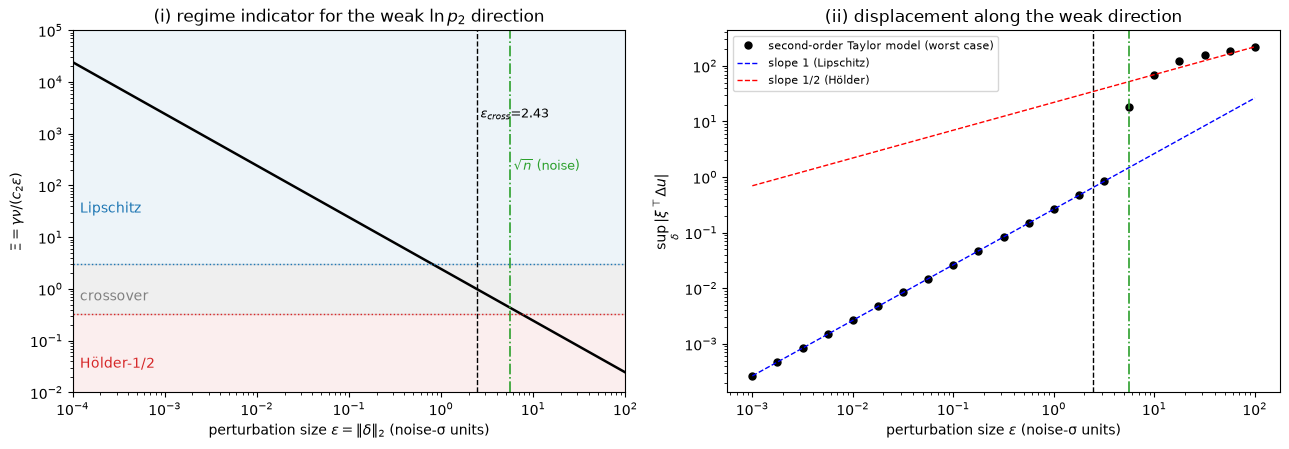

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ec, sqn = out_q['eps_cross'], np.sqrt(len(r_p))
# (a) Xi(eps) 与区域
a = ax[0]
a.loglog(eps_fine, Xi_fine, 'k-', lw=1.8)
a.axhspan(3, 1e6, color='tab:blue', alpha=0.08); a.axhspan(1/3, 3, color='gray', alpha=0.12); a.axhspan(1e-6, 1/3, color='tab:red', alpha=0.08)
a.axhline(3, color='tab:blue', ls=':', lw=1); a.axhline(1/3, color='tab:red', ls=':', lw=1)
a.axvline(ec, color='k', ls='--', lw=1); a.axvline(sqn, color='tab:green', ls='-.', lw=1.2)
a.text(1.2e-4, 30, 'Lipschitz', color='tab:blue'); a.text(1.2e-4, 0.6, 'crossover', color='gray'); a.text(1.2e-4, 0.03, 'Hölder-1/2', color='tab:red')
a.text(ec * 1.1, 2e3, f'$\\varepsilon_{{cross}}$={ec:.2f}', fontsize=9); a.text(sqn * 1.1, 2e2, '$\\sqrt{n}$ (noise)', color='tab:green', fontsize=9)
a.set_xlim(eps_fine[0], eps_fine[-1]); a.set_ylim(1e-2, 1e5)
a.set_xlabel('perturbation size $\\varepsilon=\\|\\delta\\|_2$ (noise-σ units)'); a.set_ylabel('$\\Xi=\\gamma\\nu/(c_2\\varepsilon)$')
a.set_title('(i) regime indicator for the weak $\\ln p_2$ direction')
# (b) 数值验证: 最坏偏移 vs eps
a = ax[1]
a.loglog(eps_v, sup_disp, 'ko', ms=5, label='second-order Taylor model (worst case)')
i0 = 0; a.loglog(eps_v, sup_disp[i0] * eps_v / eps_v[i0], 'b--', lw=1, label='slope 1 (Lipschitz)')
i1 = int(np.argmin(np.abs(eps_v - 10.0))); a.loglog(eps_v, sup_disp[i1] * np.sqrt(eps_v / eps_v[i1]), 'r--', lw=1, label='slope 1/2 (Hölder)')
a.axvline(ec, color='k', ls='--', lw=1); a.axvline(sqn, color='tab:green', ls='-.', lw=1.2)
a.set_xlabel('perturbation size $\\varepsilon$ (noise-σ units)'); a.set_ylabel('$\\sup_\\delta|\\xi^\\top\\Delta u|$')
a.set_title('(ii) displacement along the weak direction'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 9.4b 合成图：扰动 ε 与残差曲率的竞争（弱方向 $\ln(p_2x_1(0))$），以及为什么它是弱方向

**图 A**（一张图）：横轴 $\varepsilon=\|\delta\|_2$。右轴直接画二次项系数里的两个竞争量：残差提供的曲率 $\gamma\nu$（常数）和扰动最多能抵消的 $c_2\varepsilon$（斜率 1）。两条线相交处即 $\varepsilon_{\rm cross}=\gamma\nu/c_2$，交点左侧残差占优（Lipschitz），右侧扰动占优（Hölder-½）。左轴为 9.4 的数值验证：沿弱方向的最坏偏移 $\sup_\delta|\xi^\top\Delta u|$，斜率 1 → ½ 的转变应与交点位置一致。

**图 B**（三栏）：(i) $J_\eta$ 的奇异值谱，最后两个远小于其余；(ii) 对应的两个右奇异向量在 $\eta$ 坐标下的分量：$\sigma_7$ 是精确对称方向 $z$，$\sigma_6$ 是弱方向 $w\propto e_{p_2}-(e_{p_2}\!\cdot\! z)z$，即 $\ln(p_2x_1(0))$；(iii) 第 7 节 6 个组合坐标的 profile $\Delta\chi^2$ 叠加：只有 $\ln(p_2x_1(0))$ 向上平坦。

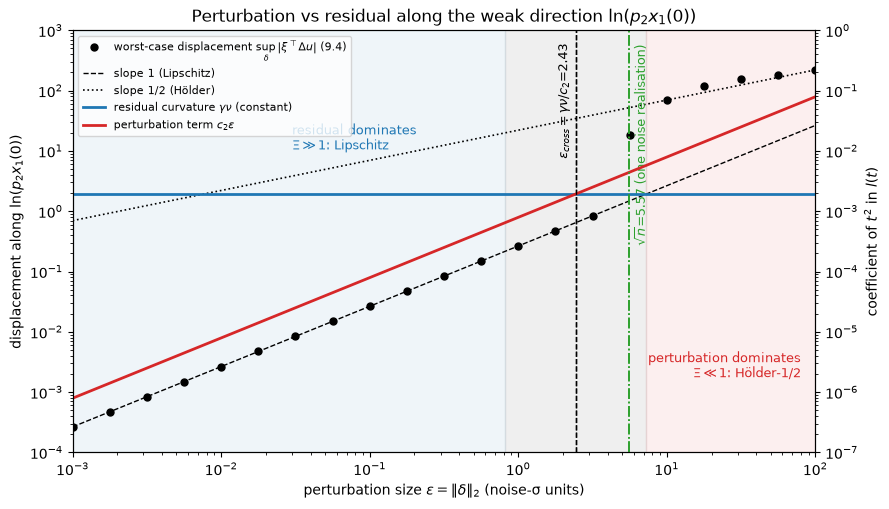

weak direction from SVD      : [ 0.     0.866 -0.    -0.    -0.289 -0.289  0.289]
e_p2 projected orthogonal to z: [-0.     0.866  0.     0.    -0.289 -0.289  0.289]  max |diff| = 0.000221


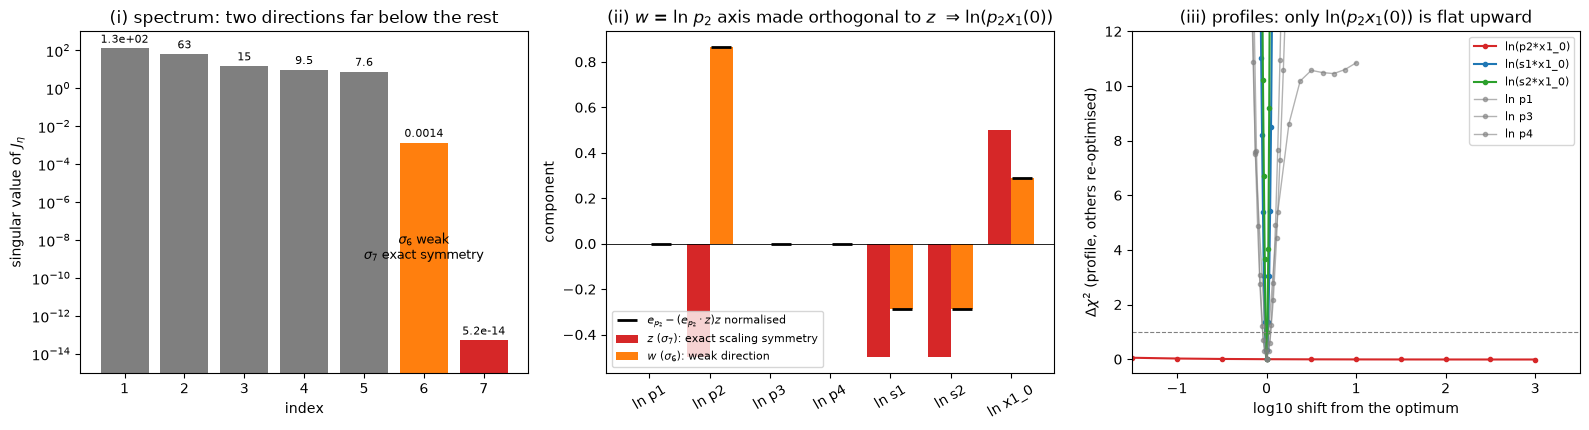

In [31]:
# ---------- 图 A: perturbation vs residual, 一张图 ----------
gam, nu_, c2_, ec_ = out_q['gamma'], out_q['nu'], out_q['c2'], out_q['eps_cross']; sqn_ = np.sqrt(len(r_p))
fig, a1 = plt.subplots(figsize=(9, 5.2))
# 背景: 按 Xi = gamma*nu/(c2*eps) 的三个区域着色 (Xi > 3 / 1/3..3 / < 1/3  <=>  eps < ec/3 / ec/3..3ec / > 3ec)
a1.axvspan(1e-4, ec_ / 3, color='tab:blue', alpha=0.07); a1.axvspan(ec_ / 3, 3 * ec_, color='gray', alpha=0.12); a1.axvspan(3 * ec_, 1e3, color='tab:red', alpha=0.07)
a1.loglog(eps_v, sup_disp, 'ko', ms=5, label='worst-case displacement $\\sup_\\delta|\\xi^\\top\\Delta u|$ (9.4)')
i0 = 0; a1.loglog(eps_v, sup_disp[i0] * eps_v / eps_v[i0], 'k--', lw=1, label='slope 1 (Lipschitz)')
i1 = int(np.argmin(np.abs(eps_v - 10.0))); a1.loglog(eps_v, sup_disp[i1] * np.sqrt(eps_v / eps_v[i1]), 'k:', lw=1.2, label='slope 1/2 (Hölder)')
a1.set_xlabel('perturbation size $\\varepsilon=\\|\\delta\\|_2$ (noise-σ units)'); a1.set_ylabel('displacement along $\\ln(p_2x_1(0))$')
a1.set_xlim(1e-3, 1e2); a1.set_ylim(1e-4, 1e3)
a2 = a1.twinx()
ef = np.logspace(-3, 2, 200)
a2.loglog(ef, np.full_like(ef, gam * nu_), '-', color='tab:blue', lw=2, label='residual curvature $\\gamma\\nu$ (constant)')
a2.loglog(ef, c2_ * ef, '-', color='tab:red', lw=2, label='perturbation term $c_2\\varepsilon$')
a2.set_ylabel('coefficient of $t^2$ in $l(t)$'); a2.set_ylim(1e-7, 1e0)
for a_ in (a1, a2): a_.axvline(ec_, color='k', ls='--', lw=1); a_.axvline(sqn_, color='tab:green', ls='-.', lw=1.2)
a1.text(ec_ * 0.93, 6e2, f'$\\varepsilon_{{cross}}=\\gamma\\nu/c_2$={ec_:.2f}', fontsize=9, rotation=90, va='top', ha='right')
a1.text(sqn_ * 1.08, 6e2, f'$\\sqrt{{n}}$={sqn_:.2f} (one noise realisation)', fontsize=9, rotation=90, va='top', color='tab:green')
a1.text(3e-2, 3e1, 'residual dominates\n$\\Xi\\gg1$: Lipschitz', color='tab:blue', fontsize=9, va='top')
a1.text(8e1, 5e-3, 'perturbation dominates\n$\\Xi\\ll1$: Hölder-1/2', color='tab:red', fontsize=9, va='top', ha='right')
h1, l1 = a1.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); a1.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper left')
a1.set_title('Perturbation vs residual along the weak direction $\\ln(p_2x_1(0))$'); plt.tight_layout(); plt.show()

# ---------- 图 B: 为什么 ln(p2*x1_0) 是弱方向 ----------
U_, s_J_, Vt_J_ = np.linalg.svd(J_p); z_ = Vt_J_[-1]; w_ = Vt_J_[-2]
if z_[6] < 0: z_ = -z_
if w_[1] < 0: w_ = -w_
w_pred = np.zeros(7); w_pred[1] = 1; w_pred -= (w_pred @ z_) * z_; w_pred /= np.linalg.norm(w_pred)      # e_p2 投影到 z 的正交补
print('weak direction from SVD      :', np.round(w_, 3)); print('e_p2 projected orthogonal to z:', np.round(w_pred, 3), ' max |diff| =', np.abs(w_ - w_pred).max().round(6))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
xk = np.arange(1, 8)
ax[0].bar(xk, np.maximum(s_J_, 1e-16), color=['tab:gray'] * 5 + ['tab:orange', 'tab:red']); ax[0].set_yscale('log'); ax[0].set_ylim(1e-15, 1e3)
for i, v in enumerate(s_J_): ax[0].text(i + 1, max(v, 1e-16) * 2, f'{v:.2g}', ha='center', fontsize=8)
ax[0].set_xticks(xk); ax[0].set_xlabel('index'); ax[0].set_ylabel('singular value of $J_\\eta$'); ax[0].set_title('(i) spectrum: two directions far below the rest')
ax[0].text(6, 1e-9, '$\\sigma_6$ weak\n$\\sigma_7$ exact symmetry', ha='center', fontsize=9)
xk7 = np.arange(7); wd = 0.38
ax[1].bar(xk7 - wd/2, z_, wd, color='tab:red', label='$z$ ($\\sigma_7$): exact scaling symmetry')
ax[1].bar(xk7 + wd/2, w_, wd, color='tab:orange', label='$w$ ($\\sigma_6$): weak direction')
ax[1].plot(xk7 + wd/2, w_pred, 'k_', ms=14, mew=2, label='$e_{p_2}-(e_{p_2}\\cdot z)z$ normalised')
ax[1].axhline(0, color='k', lw=0.6); ax[1].set_xticks(xk7); ax[1].set_xticklabels(ETA_NAMES, rotation=30); ax[1].set_ylabel('component'); ax[1].legend(fontsize=8, loc='lower left')
ax[1].set_title('(ii) $w$ = ln $p_2$ axis made orthogonal to $z$  ⇒ ln($p_2x_1(0)$)')
for n_, c_ in zip(CNAMES + ['p1', 'p3', 'p4'], ['tab:red', 'tab:blue', 'tab:green', 'gray', 'gray', 'gray']):
    if n_ in CNAMES: g_, pl_, q0_ = grids_c[n_], profiles_c[n_], best_q[CIDX[n_]]
    else: g_, pl_, q0_ = grids[n_], profiles[n_], best_log[PNAMES.index(n_)]
    ax[2].plot(g_ - q0_, pl_ - best_chi2, '.-', color=c_, lw=1.5 if n_ in CNAMES else 1, alpha=1 if n_ in CNAMES else 0.6, label=f'ln({n_})' if '*' in n_ else f'ln {n_}')
ax[2].axhline(thr_pw, ls='--', color='gray', lw=0.8); ax[2].set_xlim(-1.5, 3.5); ax[2].set_ylim(-0.5, 12)
ax[2].set_xlabel('log10 shift from the optimum'); ax[2].set_ylabel('$\\Delta\\chi^2$ (profile, others re-optimised)'); ax[2].legend(fontsize=8); ax[2].set_title('(iii) profiles: only ln($p_2x_1(0)$) is flat upward')
plt.tight_layout(); plt.show()

### 9.5 将第 9 节结果保存为 MATLAB `.mat`

`crossover_analysis.mat` 包含：`tau_1e6`、`tau_1e3`、`quotient` 三组诊断结果（`gamma, c2, M_N, nu, eps_cross, Xi, regime, flags` 等），$J_\eta$ 的奇异值，精确对称方向与弱方向（$\eta$ 坐标），投影基 `quotient_basis_Q`，以及 9.4 的作图数据 `eps_fine, Xi_fine` 和 `verify.eps, verify.sup_displacement, verify.local_slope`。

In [32]:
from scipy.io import savemat
def _cross_to_mat(o):
    return {k: (np.array(list(v), dtype=object) if k in ('regime', 'flags') else (np.nan if v is None else v)) for k, v in o.items()}
_, _, Vt_e = np.linalg.svd(J_p)
crossover_mat = dict(
    eta_names=np.array(ETA_NAMES, dtype=object), singular_values_J=s_J, nu=np.linalg.norm(r_p), n_data=len(r_p), sqrt_n=np.sqrt(len(r_p)),
    C_norm=C_scale, H_max_norm=H_scale, eps_grid=eps_grid, eps_labels=np.array(eps_lab, dtype=object),
    # 9.2: 两个阈值
    tau_1e6=_cross_to_mat(crossover_results[1e-6]), tau_1e3=_cross_to_mat(crossover_results[1e-3]),
    exact_symmetry_direction_eta=z_sym,
    # 9.3: 去掉精确对称后
    quotient=_cross_to_mat(out_q), quotient_basis_Q=Q, weak_direction_eta=w_dir,
    # 9.4: 展示用曲线
    eps_fine=eps_fine, Xi_fine=Xi_fine,
    # 9.4b: J_eta 的 SVD (右奇异向量按行, 最后两行 = 弱方向, 精确对称方向) 与弱方向的解析预测
    svd_Vt_J=Vt_J_, weak_direction_predicted_eta=w_pred,
    verify=dict(eps=eps_v, sup_displacement=sup_disp, local_slope=slope_v, n_directions=len(dirs_v),
                note='worst-case |xi^T (u(delta)-u(0))| over delta = eps*d (d: normal-acceleration direction +- and 40 random unit vectors), second-order Taylor model in symmetry-removed coordinates'),
)
savemat('crossover_analysis.mat', crossover_mat, long_field_names=True, do_compression=True)
print('saved crossover_analysis.mat with fields:', list(crossover_mat.keys()))

saved crossover_analysis.mat with fields: ['eta_names', 'singular_values_J', 'nu', 'n_data', 'sqrt_n', 'C_norm', 'H_max_norm', 'eps_grid', 'eps_labels', 'tau_1e6', 'tau_1e3', 'exact_symmetry_direction_eta', 'quotient', 'quotient_basis_Q', 'weak_direction_eta', 'eps_fine', 'Xi_fine', 'svd_Vt_J', 'weak_direction_predicted_eta', 'verify']


## 10. 小结
- 数据（16 个时间点的 pSTAT、tSTAT 及其标准差，15 个时间点的 pEpoR）已保存在 `data.npz`。
- 使用论文中的 4 状态 + 10 步延迟链模型、pEpoR 样条输入、$\chi^2$ 目标函数。由于 $(p_2,s_1,s_2,x_1(0))$ 存在精确缩放对称，只在 6 个可识别组合 $p_1,\ p_2x_1(0),\ p_3,\ p_4,\ s_1x_1(0),\ s_2x_1(0)$ 上做多起点优化（解析 Jacobian），全局最优 $\chi^2\approx 57.40$；$s_1x_1(0)$、$s_2x_1(0)$ 在边界内部，$p_2x_1(0)$ 停在上界 $10^6$，因为 $\chi^2$ 随它增大单调下降（实际不可识别）。
- $p_1,p_4$ 与论文数量级一致；7 参数 Hessian 有一个精确为零的特征值，对应 $p_2, x_1(0), s_1, s_2$ 的一维结构不可识别流形（论文 Eq. 11）；另有一个极小的特征值，对应 $p_2x_1(0)$ 方向（最优点停在其上界）。
- 第 7 节按论文 Fig. 3 的扫描宽度与两级阈值计算 7 个原始参数和 3 个组合的 profile likelihood：$p_1,p_3,p_4$ 可识别；$p_2,s_1,s_2,x_1(0)$ 结构不可识别（精确平坦）；$s_1x_1(0)$、$s_2x_1(0)$ 可识别；$p_2x_1(0)$ 向上实际不可识别。结果保存在 `profile_likelihood.npz` / `.mat`。
- 第 8 节按 Hao & Wang 的设置，用前向一阶/二阶灵敏度 ODE 计算了对数坐标下的 $J_\eta$、$H_\eta$，并组装 $F_\eta=J_\eta^\top J_\eta$、$K_\eta=F_\eta+\sum r^*\nabla^2_\eta h$，给出两者的特征值/特征向量及 Theorem 2 的曲率修正量；矩阵保存在 `identifiability_matrices.npz`。
- 第 8.3 节在全局最优处计算了每个坐标的 $\kappa^F_p,\kappa^K_p$、$L^F_p,L^K_p$、残差修正比 $R^{RH}_p$ 及二次模型可信区间：$p_1,p_3,p_4$ 坐标可识别且残差 Hessian 使其 Lipschitz 系数减小（$R^{RH}_p<1$）；$p_2,s_1,s_2,x_1(0)$ 因落在 $\ker K_\eta$ 上而 $\kappa_p=0$，坐标不可识别。结果保存在 `coordinate_identifiability.npz`。
- 第 8.4b 节在 6 维组合坐标 $q=\ln(p_1,p_2x_1(0),p_3,p_4,s_1x_1(0),s_2x_1(0))$ 下重做坐标指标：$K_q$ 正定，$s_1x_1(0)$、$s_2x_1(0)$ 的二次模型 1-σ 区间与第 7 节 profile 区间一致；$p_2x_1(0)$ 的 $\kappa^F\approx10^{-6}$、$\kappa^K\approx10^{-3}$，曲率几乎全部来自残差项，二次模型区间跨越数十个数量级，与 profile 向上无界一致。结果保存在 `coordinate_identifiability_combo.npz` 及 `identifiability_analysis.mat` 的 `coordinate_metrics_combo`。
- 第 8.5b 节把 Yao、Quaiser 与 Hao–Wang $L^K$ 排序也换到组合坐标 $q$ 下（$Z_q=J_q$，无精确零空间），结果见该节表格与合图，保存在 `identifiability_analysis.mat` 的 `yao_combo`、`quaiser_combo`、`comparison_combo`。
- 第 8.5 节在同一 $J_\eta$ 上实现了 Yao orthogonal method（QRCP 排序）与 Quaiser & Mönnigmann eigenvalue method（迭代剔除最小特征向量主分量），并按 Quaiser 的统一准则（依次固定后 $\lambda_{\min}$ 路径）与 Hao–Wang 的坐标 Lipschitz 系数 $L^K_p$ 排序比较，最后给出 Yao 与 Quaiser 结果的合图；第 8 节全部结果保存在 `identifiability_analysis.mat`，第 7 节 profile 曲线保存在 `profile_likelihood.mat`。
- 第 9 节 regime 诊断：精确对称方向在任何阶都不可恢复；去掉它之后的弱方向 $\ln(p_2x_1(0))$ 在扰动远小于噪声时 Lipschitz 稳定，交叉尺度 $\varepsilon_{\rm cross}\approx2.4$（噪声 $\sigma$ 单位），在真实噪声水平 $\sqrt n\approx5.6$ 处进入交叉区并趋向 Hölder-1/2。拟合点是边界点（梯度不为零），定理的内点极小假设只近似成立。结果保存在 `crossover_analysis.mat`。
- 与论文差异的主要来源是 pEpoR 输入的插值方式：自然三次样条在稀疏的后段节点之间过冲；改用单调的 PCHIP 或线性插值时，全局最优 $\chi^2$ 降到约 38，与论文的约 39.2 一致（本 notebook 仍使用自然三次样条）。噪声 $\sigma_k$、数据、观测量与延迟链设置与论文一致。